# Dual WWR CVA Engine: Citigroup Calibration (BBB+ Reference Entity)

This notebook produces the numerical results of the thesis. It loads the simulation engine of `dual_wwr_cva_jump_diffusion.ipynb` (Modules 1-7) unchanged and recalibrates both legs of the model to Citigroup, using market data as of 2026-08-11.

- **Interest rates (HW1F).** The short-rate parameters $(a,\sigma_r)$ are calibrated to the normal volatilities of liquid USD SOFR swaptions. The SOFR history (`SOFR 2023 -2026.xlsx`) provides the historical sample, and the OIS curve snapshot (`SOFR 8_11.xlsx`) is bootstrapped into today's discount curve.
- **Credit (CIR++).** The intensity parameters $(\kappa,\bar\lambda,\sigma_\lambda)$ are estimated by exact maximum likelihood on the historical series of Citigroup's 5Y CDS spread (`Citigroup 5Y CDS 2024 - 2026.xlsx`), since no liquid market for options on CDS spreads exists. The CIR process has a known non-central chi-squared transition density, which makes the exact likelihood available.

The deterministic shifts $b_r(t)$ and $b_\lambda(t)$ then make the short rate and the hazard rate reproduce today's OIS discount curve and the market-implied CDS survival curve exactly, independently of the choice of $(a,\sigma_r)$ and $(\kappa,\bar\lambda,\sigma_\lambda)$. The estimated parameters therefore carry only the dynamics, and no secondary Q-measure refit against the CDS term structure is performed.


### Hull-White 1F: SOFR Data and Calibration


In [1]:
# SOFR data (US DOLLAR SECURED OVERNIGHT FINANCING RATE SOFR - FRB)
import pandas as pd
import numpy as np

df_sofr = pd.read_excel("../4_market_data/sofr/SOFR 2023 -2026.xlsx")
df_sofr.columns = ["Date", "SOFR"]
df_sofr["SOFR"] = pd.to_numeric(df_sofr["SOFR"], errors="coerce")
df_sofr["SOFR"] = df_sofr["SOFR"] / 100
df_sofr = df_sofr.dropna(subset=["Date", "SOFR"])
df_sofr = df_sofr.sort_values("Date")
sofr_series = df_sofr.set_index("Date")["SOFR"]

print(f"SOFR series: {sofr_series.index.min().date()} -> {sofr_series.index.max().date()}, n={len(sofr_series)}")
print(sofr_series.head())

SOFR series: 2022-12-30 -> 2026-08-10, n=900
Date
2022-12-30    0.0430
2023-01-03    0.0431
2023-01-04    0.0430
2023-01-05    0.0431
2023-01-06    0.0431
Name: SOFR, dtype: float64


In [2]:
# Calibrate the Hull-White interest model coef. by SOFR historical data. [P-measure: actual probability]
# dr(t) = dx_r(t) + db_r(t). db_r(t) is so small that we can ignore it.
# dr(t) approx= -a r(t) dt + sigma_r*dW_r
def calibrate_hw(sofr_series, dt=1/252):
    dr = sofr_series[1:].values - sofr_series[:-1].values # dr(t) = r(t+1)-r(t)
    r_lag = sofr_series[:-1].values.reshape(-1, 1) # r(t)

    from sklearn.linear_model import LinearRegression
    reg = LinearRegression().fit(r_lag, dr) # dr(t) = intercept + beta*r(t) + e(t)

    a_calibrated = -reg.coef_[0] / dt # beta = -a*dt => a = -beta/dt
    residuals = dr - reg.predict(r_lag) # e(t) = sigma_r*sqrt(dt)*Z_1, where Z_1 ~ N(0,1)
    sigma_r_calibrated = np.std(residuals) / np.sqrt(dt)  # std(e(t)) = sigma_r*sqrt(dt)

    return a_calibrated, sigma_r_calibrated


a, sigma_r = calibrate_hw(sofr_series)

print("a =", a)
print("sigma_r =", sigma_r)

a = 0.21069570046045932
sigma_r = 0.006346620256380813


In [3]:
import QuantLib as ql
import numpy as np
import matplotlib.pyplot as plt

def get_ql_br_t(market_data, a, sigma_r, max_years=10):
    # 1. Setting
    calculation_date = ql.Date(11, 8, 2026)  # matches the actual as-of date of the SOFR/CDS market data used below
    ql.Settings.instance().evaluationDate = calculation_date

    # SOFR
    calendar = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
    day_count = ql.Actual360()
    settlement_days = 2

    # 2. SOFR curve (Bootstrapping)
    # market_data = { '1M': xx, '6M': xx, ... }
    helpers = []
    index = ql.Sofr()

    for tenor_str, rate in market_data.items():
        tenor = ql.Period(tenor_str)
        helpers.append(ql.OISRateHelper(
            settlement_days,
            tenor,
            ql.QuoteHandle(ql.SimpleQuote(rate)),
            index
        ))

    # Log-Cubic curve -> discount curve
    yield_curve = ql.PiecewiseLogCubicDiscount(settlement_days, calendar, helpers, day_count)
    yield_curve.enableExtrapolation()

    # 3. b_r(t)
    # b_r(t) = f_r^M(0,t) + (sigma_r^2 / 2a^2) * (1 - exp(-at))^2
    times = np.linspace(0, max_years, int(max_years * 252))
    br_t_values = []

    for t in times:
        # get f_r^M(0, t)
        f_r_M = yield_curve.forwardRate(t, t, ql.Continuous, ql.NoFrequency).rate()

        # Hull-White adjustment
        adjustment_r = (sigma_r**2 / (2 * a**2)) * (1 - np.exp(-a * t))**2

        br_t_values.append(f_r_M + adjustment_r)

    return times, np.array(br_t_values), yield_curve

In [4]:
# Refinitiv SOFR OIS curve snapshot (Q-measure), realtime as of 2026/08/11
df_ois = pd.read_excel("../4_market_data/licensed_not_for_upload/SOFR 8_11.xlsx", sheet_name="Curve1 - Realtime", header=None)
df_ois.columns = ["Maturity", "Bid", "Yield", "Ask", "BenchmarkSpread", "NetChange"]
df_ois = df_ois.iloc[2:].copy()
df_ois["Bid"] = pd.to_numeric(df_ois["Bid"], errors="coerce")
ois_map = dict(zip(df_ois["Maturity"], df_ois["Bid"]))

sofr_market_quotes = {
    "1M": ois_map["1M"] / 100, "3M": ois_map["3M"] / 100, "6M": ois_map["6M"] / 100,
    "1Y": ois_map["1Y"] / 100, "2Y": ois_map["2Y"] / 100, "5Y": ois_map["5Y"] / 100,
    "10Y": ois_map["10Y"] / 100, "30Y": ois_map["30Y"] / 100,
}

t_axis, br_curve, sofr_yield_curve = get_ql_br_t(sofr_market_quotes, a, sigma_r)

print("sofr_market_quotes:")
for k, v in sofr_market_quotes.items():
    print(f"  {k:4s} = {v:.6%}")
print(f"b_r(t) curve for t=1: b_r(1)= {br_curve[252]:.6f}")
print(f"b_r(t) curve for t=10: b_r(10)={br_curve[2519]:.6f}")

sofr_market_quotes:
  1M   = 3.634500%
  3M   = 3.746000%
  6M   = 3.869900%
  1Y   = 4.024500%
  2Y   = 4.070000%
  5Y   = 4.098900%
  10Y  = 4.270500%
  30Y  = 4.485300%
b_r(t) curve for t=1: b_r(1)= 0.040837
b_r(t) curve for t=10: b_r(10)=0.045538


In [5]:
#b_r(t) under Q-measure for valuation purposes!!
swaption_vols = [
    # Expiry 1.5Y
    (1.5, 1, 111.00), (1.5, 2, 107.40), (1.5, 3, 103.90), (1.5, 4, 100.75),
    (1.5, 5, 98.25), (1.5, 7, 94.05), (1.5, 10, 89.85), (1.5, 30, 83.15),

    # Expiry 2Y
    (2.0, 1, 105.95), (2.0, 2, 103.25), (2.0, 3, 100.50), (2.0, 4, 98.25),
    (2.0, 5, 95.90), (2.0, 7, 92.50), (2.0, 10, 88.95), (2.0, 30, 82.80),

    # Expiry 3Y
    (3.0, 1, 101.40), (3.0, 2, 98.25), (3.0, 3, 96.30), (3.0, 4, 94.95),
    (3.0, 5, 93.05), (3.0, 7, 90.45), (3.0, 10, 87.95), (3.0, 30, 82.20)
]

yield_curve_handle = ql.RelinkableYieldTermStructureHandle(sofr_yield_curve)
index = ql.Sofr(yield_curve_handle)

helpers = []
for expiry, tenor, vol in swaption_vols:
    vol_quote = ql.QuoteHandle(ql.SimpleQuote(vol / 10000.0)) # Normal Vol bps /10000
    helper = ql.SwaptionHelper(
        ql.Period(int(expiry*12), ql.Months),
        ql.Period(int(tenor), ql.Years),
        vol_quote, index,
        ql.Period(1, ql.Years), ql.Actual360(), ql.Actual360(), yield_curve_handle,
        ql.BlackCalibrationHelper.RelativePriceError,
        ql.nullDouble(), 1.0,
        1 # 1: Normal Volatility
    )
    helpers.append(helper)

model = ql.HullWhite(yield_curve_handle, a, sigma_r)
engine = ql.JamshidianSwaptionEngine(model)

for h in helpers:
    h.setPricingEngine(engine)

model.calibrate(helpers, ql.LevenbergMarquardt(), ql.EndCriteria(1000, 100, 1e-8, 1e-8, 1e-8))

# under Q-measure
a_calibrated = model.params()[0]
sigma_r_calibrated = model.params()[1]

print(f"Calibrated a: {a_calibrated:.6f}")
print(f"Calibrated sigma: {sigma_r_calibrated:.6f}")

t_axis_calibrated, br_curve_calibrated, sofr_yield_curve_calibrated = get_ql_br_t(sofr_market_quotes, a_calibrated, sigma_r_calibrated)


from scipy.interpolate import PchipInterpolator
br_func_calibrated = PchipInterpolator(t_axis_calibrated, br_curve_calibrated)

Calibrated a: 0.021505
Calibrated sigma: 0.010035


### CIR++: Citigroup CDS Data and Exact Maximum Likelihood Estimation


In [6]:
# CDS Spreads 5Y Data (2024-2026) - Citigroup (BBB+ rating)
df_cds_5Y = pd.read_excel("../4_market_data/licensed_not_for_upload/Citigroup 5Y CDS 2024 - 2026.xlsx")
df_cds_5Y.columns = ["Date", "Spread5Y"]
df_cds_5Y["Spread5Y"] = pd.to_numeric(df_cds_5Y["Spread5Y"], errors="coerce")
df_cds_5Y["Spread5Y"] = df_cds_5Y["Spread5Y"] / 10000

# Assume R = 0.4
# lambda = CDS Spreads / (1 - R)
recovery_rate = 0.4
df_cds_5Y["lambda"] = df_cds_5Y["Spread5Y"] / (1 - recovery_rate)

df_cds_5Y = df_cds_5Y.dropna(subset=["Date", "lambda"])
df_cds_5Y = df_cds_5Y.sort_values("Date")

lambda_series = df_cds_5Y.set_index("Date")["lambda"]

print(f"Citigroup 5Y lambda series: {lambda_series.index.min().date()} -> {lambda_series.index.max().date()}, n={len(lambda_series)}")
print(lambda_series.head())

Citigroup 5Y lambda series: 2024-08-12 -> 2026-08-10, n=517
Date
2024-08-12    0.010210
2024-08-13    0.010545
2024-08-14    0.010037
2024-08-15    0.009518
2024-08-16    0.009537
Name: lambda, dtype: float64


In [7]:
# Under P-measure (Historical data): exact MLE via the CIR non-central
# chi-squared transition density, instead of the discretized-regression
# approximation. The CIR transition density is known in closed form (Cox,
# Ingersoll, Ross 1985); using it directly avoids the Euler-discretization
# bias the simple regression carries, especially relevant here since kappa
# turns out to be fairly large (fast mean reversion, small dt/kappa is not
# obviously satisfied for daily data).
from scipy.stats import ncx2
from scipy.optimize import minimize
from sklearn.linear_model import LinearRegression


def calibrate_cir_regression(l_series, dt=1/252):
    '''Discretized-regression estimator (kept only as an initial guess / cross-check).'''
    l_series = l_series[l_series > 1e-6]
    d_l = l_series[1:].values - l_series[:-1].values
    l_lag = l_series[:-1].values
    y = d_l / np.sqrt(l_lag)
    x1 = 1.0 / np.sqrt(l_lag)
    x2 = np.sqrt(l_lag)
    X = np.column_stack([x1, x2])
    reg = LinearRegression(fit_intercept=False).fit(X, y)
    kappa0 = -reg.coef_[1] / dt
    l_bar0 = (reg.coef_[0] / dt) / kappa0
    res = y - reg.predict(X)
    sigma0 = np.std(res) / np.sqrt(dt)
    return kappa0, l_bar0, sigma0


def calibrate_cir_mle(lam_series, dt=1/252):
    '''Exact MLE using the CIR process's closed-form non-central chi-squared
    transition density: lambda_{t+dt} | lambda_t ~ c * chi2_df(nc), with
      c = sigma^2 (1-e^{-k dt}) / (4k),  df = 4 k lambda_bar / sigma^2,
      nc = 4 k e^{-k dt} lambda_t / (sigma^2 (1-e^{-k dt})).'''
    lam = lam_series[lam_series > 1e-8].values
    lam_t, lam_tp1 = lam[:-1], lam[1:]

    def neg_loglik(params):
        kappa, lambda_bar, sigma = params
        if kappa <= 0 or lambda_bar <= 0 or sigma <= 0:
            return 1e12
        c = sigma**2 * (1 - np.exp(-kappa*dt)) / (4*kappa)
        if c <= 0:
            return 1e12
        df = 4*kappa*lambda_bar / sigma**2
        nc = 4*kappa*np.exp(-kappa*dt)*lam_t / (sigma**2*(1-np.exp(-kappa*dt)))
        x = lam_tp1 / c
        pdf_vals = np.clip(ncx2.pdf(x, df, nc) / c, 1e-300, None)
        return -np.sum(np.log(pdf_vals))

    k0, lb0, s0 = calibrate_cir_regression(lam_series, dt)
    init = [max(k0, 0.1), max(lb0, 1e-4), max(s0, 1e-4)]
    opt_res = minimize(neg_loglik, init, method="Nelder-Mead",
                        options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 20000, "maxfev": 20000})
    return opt_res.x[0], opt_res.x[1], opt_res.x[2], (k0, lb0, s0), opt_res


kappa_reg, lambda_bar_reg, sigma_reg = calibrate_cir_regression(lambda_series)
kappa, lambda_bar, sigma_lambda, (_, _, _), opt_res = calibrate_cir_mle(lambda_series)
sigma_lambda = max(sigma_lambda, 0.02)  # floor: use the calibrated value unless it falls below this

print(f"Regression (cross-check): kappa={kappa_reg:.4f}  lambda_bar={lambda_bar_reg:.6f}  sigma={sigma_reg:.6f}")
print(f"Exact MLE (used):         kappa={kappa:.4f}  lambda_bar={lambda_bar:.6f}  sigma_lambda={sigma_lambda:.6f}")
print(f"MLE converged: {opt_res.success}, neg-loglik={opt_res.fun:.4f}")

feller = 2*kappa*lambda_bar - sigma_lambda**2
print(f"Feller condition (2*kappa*lambda_bar - sigma_lambda^2 = {feller:.6f}, >0 required for strict positivity)")

Regression (cross-check): kappa=7.3871  lambda_bar=0.009412  sigma=0.036965
Exact MLE (used):         kappa=8.6064  lambda_bar=0.009423  sigma_lambda=0.036899
MLE converged: True, neg-loglik=-3608.3311
Feller condition (2*kappa*lambda_bar - sigma_lambda^2 = 0.160843, >0 required for strict positivity)


In [8]:
import QuantLib as ql
import numpy as np
from scipy.interpolate import PchipInterpolator

def get_ql_blambda_t(
    cds_market_data, sofr_yield_curve, kappa, lambda_bar, sigma_lambda, x0, max_years=10, recovery_rate=0.4):

    # --- 1. Settings ---
    calc_date = ql.Date(11, 8, 2026)  # matches the actual as-of date of the Citigroup CDS curve used below
    ql.Settings.instance().evaluationDate = calc_date
    calendar = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
    day_count = ql.Actual360()
    settlement_days = 2

    # For CDS Bootstrap
    risk_free_ts = ql.RelinkableYieldTermStructureHandle()
    risk_free_ts.linkTo(sofr_yield_curve)

    # --- 2. Market Hazard Curve Bootstrap (QuantLib) ---
    cds_helpers = []
    for tenor_str, spread in cds_market_data.items():
        helper = ql.SpreadCdsHelper(
            ql.QuoteHandle(ql.SimpleQuote(spread)),
            ql.Period(tenor_str),
            settlement_days, calendar, ql.Quarterly, ql.Following,
            ql.DateGeneration.TwentiethIMM, day_count, recovery_rate, risk_free_ts
        )
        cds_helpers.append(helper)

    # Raw Market Data
    hazard_curve = ql.PiecewiseFlatHazardRate(settlement_days, calendar, cds_helpers, day_count)
    hazard_curve.enableExtrapolation()

    # --- 3. PCHIP (Piecewise Cubic Hermite Interpolating Polynomial) ---
    times = np.linspace(0, max_years, int(max_years * 365) + 1)

    # Cumulative Hazard Function H(t) = -ln(Q(t))
    raw_H = np.array([-np.log(max(hazard_curve.survivalProbability(float(t)), 1e-16)) for t in times])
    H_interp = PchipInterpolator(times, raw_H)
    fm_curve = H_interp.derivative(1)

    # --- 4. Theoretical CIR forward intensity f_CIR(0,t) ---
    h = np.sqrt(kappa**2 + 2.0*sigma_lambda**2)
    def fcir_curve(t):
        t = np.asarray(t, dtype=float)
        exp_ht = np.exp(h*t)
        denom = 2.0*h + (kappa+h)*(exp_ht-1.0)
        return (2.0*kappa*lambda_bar*(exp_ht-1.0))/denom + x0*(4.0*h**2*exp_ht)/denom**2

    fcir_vals = fcir_curve(times)
    b_vals = fm_curve(times) - fcir_vals
    bl_func = PchipInterpolator(times, b_vals)

    return dict(t_axis_l=times, bl_func=bl_func, fm_curve=fm_curve, fcir_curve=fcir_curve, hazard_curve=hazard_curve)

In [9]:
# Citigroup CDS term structure snapshot (Q-measure curve LEVEL only -- used
# solely to anchor x_lambda(0)=f_M(0) and to build b_lambda(t); NOT used to
# re-fit kappa/lambda_bar/sigma_lambda, see the methodology note above).
# Source: Refinitiv "USD, REFINITIV EOD (R), SNRFOR, XR" curve for Citigroup;
# 5Y=53.331bps matches the historical series' most recent print exactly.
cds_market_data = {
    "6M": 24.550 / 10000, "1Y": 26.757 / 10000, "2Y": 32.761 / 10000,
    "3Y": 37.253 / 10000, "5Y": 53.331 / 10000, "7Y": 69.857 / 10000, "10Y": 90.838 / 10000,
}

b_lambda = get_ql_blambda_t(cds_market_data, sofr_yield_curve_calibrated, kappa, lambda_bar, sigma_lambda, x0=lambda_bar)
t_axis_l = b_lambda["t_axis_l"]
fm_curve = b_lambda["fm_curve"]

print("cds_market_data (Citigroup):")
for k, v in cds_market_data.items():
    print(f"  {k:4s} = {v:.6%}")

cds_market_data (Citigroup):
  6M   = 0.245500%
  1Y   = 0.267570%
  2Y   = 0.327610%
  3Y   = 0.372530%
  5Y   = 0.533310%
  7Y   = 0.698570%
  10Y  = 0.908380%


In [10]:
# No Q-measure least-squares refit: kappa, lambda_bar, sigma_lambda are used
# exactly as estimated by MLE above. x_lambda(0) is anchored to the market
# curve's own t=0 value (standard convention, matches the original notebook),
# and b_lambda(t) is rebuilt once more with this x0 to get the final shift.
x_lambda_0 = fm_curve(t_axis_l)[0]

b_lambda_calibration = get_ql_blambda_t(
    cds_market_data, sofr_yield_curve_calibrated, kappa, lambda_bar, sigma_lambda, x_lambda_0
)

kappa_calibration = kappa
lambda_bar_calibration = lambda_bar
sigma_lambda_calibration = sigma_lambda

t_axis_l_calibration     = b_lambda_calibration["t_axis_l"]
bl_func_calibration      = b_lambda_calibration["bl_func"]
fm_curve_calibration     = b_lambda_calibration["fm_curve"]
fcir_curve_calibration   = b_lambda_calibration["fcir_curve"]
hazard_curve_calibration = b_lambda_calibration["hazard_curve"]

print(f"kappa_calibration:        {kappa_calibration:.4f}")
print(f"lambda_bar_calibration:   {lambda_bar_calibration:.6f}")
print(f"sigma_lambda_calibration: {sigma_lambda_calibration:.6f}")
print(f"x_lambda_0:               {x_lambda_0:.6f}")

# Sanity check: f_CIR(t) + b_lambda(t) should reproduce f_M(t) exactly
# (algebraic identity, independent of kappa/lambda_bar/sigma_lambda/x0).
recon = fcir_curve_calibration(t_axis_l_calibration) + bl_func_calibration(t_axis_l_calibration)
target = fm_curve_calibration(t_axis_l_calibration)
print(f"Sanity check max|f_CIR + b_lambda - f_M| over t in [0,10]: {np.max(np.abs(recon - target)):.2e}  (should be ~0)")

kappa_calibration:        8.6064
lambda_bar_calibration:   0.009423
sigma_lambda_calibration: 0.036899
x_lambda_0:               0.004073
Sanity check max|f_CIR + b_lambda - f_M| over t in [0,10]: 3.47e-18  (should be ~0)


### Empirical Spearman Rank Correlation (SOFR vs. Citigroup CDS) and the Implied $\rho_{r,\lambda}$


In [11]:
# Spearman rank correlation - Citigroup, on the same updated SOFR/CDS data
# used for calibration above (first-differenced, to avoid spurious
# correlation between two independently-trending non-stationary series).
from scipy.stats import spearmanr

df_combined = pd.concat([sofr_series, lambda_series], axis=1, join='inner')
df_combined.columns = ['SOFR', 'lambda']

df_combined['d_sofr'] = df_combined['SOFR'].diff()
df_combined['d_lambda'] = df_combined['lambda'].diff()

df_analysis = df_combined.dropna()

rho_s, p_value = spearmanr(df_analysis['d_sofr'], df_analysis['d_lambda'])
rho_estimated = 2 * np.sin((np.pi / 6) * rho_s)

print(f"Sample size: {len(df_analysis)}")
print(f"Spearman rank correlation': {rho_s:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"Pearson correlation'': {rho_estimated:.4f}")

Sample size: 492
Spearman rank correlation': -0.0913
p-value: 0.0430
Pearson correlation'': -0.0955


### IRS Trade Configuration

The baseline trade is a 10-year payer IRS ($\delta=-1$) with a notional of USD 1 million.


In [12]:
# IRS pricing
import numpy as np
import QuantLib as ql
import matplotlib.pyplot as plt

swap_config = {
    'N': 1000000,                      
    'delta': -1,                                     # Payer Swap 
    'payment_dates': [i / 2.0 for i in range(0, 21)] # pay evert half year, 10Y
}

max_years = 10
T_pay = swap_config['payment_dates'] 
notional = swap_config['N']


## Part 2: Dual WWR CVA Engine

The engine is organized into seven modules:
1. Grid initialization
2. Dual WWR random variable generation (correlated Brownian increments $dW_r$ and $dW_\lambda$)
3. Hull-White 1F forward-measure zero-coupon bond simulation
4. CIR++ hazard-rate simulation (Milstein scheme) with continuous WWR drift
5. IRS exposure valuation
6. Gaussian copula jump-to-default path weights
7. Final CVA aggregation


In [13]:
# Module 1 - Grid initialization
import numpy as np
from scipy.stats import norm


def build_time_grid(T, steps_per_year=365):
    """Build the simulation time grid on [0, T] with a fixed number of steps per year."""
    n_steps = int(round(T * steps_per_year))
    t_axis = np.linspace(0.0, T, n_steps + 1)
    dt = np.diff(t_axis)
    return t_axis, dt


In [14]:
# Module 2 - Dual WWR random variable generation
def spearman_to_pearson(rho_spearman):
    """Convert a Spearman rank correlation into the equivalent Pearson correlation:
    rho_{r,lambda} = 2 * sin(pi/6 * rho_s)."""
    return 2.0 * np.sin(np.pi / 6.0 * rho_spearman)


def generate_dual_wwr_randoms(t_axis, n_paths, rho_r_lambda, seed=1234, antithetic=True):
    """
    Generate all random inputs shared by the interest-rate and hazard-rate simulators.

    Continuous diffusion WWR (Eq. 5.4): dW_r and dW_lambda are built from two
    independent standard-normal matrices Z1, Z2 via Cholesky-style mixing:
        dW_r(t_k)      = Z1(t_k) * sqrt(dt_k)
        dW_lambda(t_k) = (rho_r_lambda * Z1(t_k) + sqrt(1 - rho_r_lambda^2) * Z2(t_k)) * sqrt(dt_k)

    Jump WWR: u_tau is a single uniform draw per path, constant across time,
    representing that path\'s idiosyncratic tail-event percentile.
    """
    rng = np.random.default_rng(seed)
    dt = np.diff(t_axis)
    n_steps = len(dt)

    if antithetic:
        half = n_paths // 2
        Z1_half = rng.standard_normal((n_steps, half))
        Z2_half = rng.standard_normal((n_steps, half))
        Z1 = np.concatenate([Z1_half, -Z1_half], axis=1)
        Z2 = np.concatenate([Z2_half, -Z2_half], axis=1)
        u_half = rng.uniform(0.0, 1.0, size=half)
        u_tau = np.concatenate([u_half, 1.0 - u_half])
    else:
        Z1 = rng.standard_normal((n_steps, n_paths))
        Z2 = rng.standard_normal((n_steps, n_paths))
        u_tau = rng.uniform(0.0, 1.0, size=n_paths)

    sqrt_dt = np.sqrt(dt)[:, np.newaxis]
    dW_r = Z1 * sqrt_dt
    dW_lambda = (rho_r_lambda * Z1 + np.sqrt(1.0 - rho_r_lambda ** 2) * Z2) * sqrt_dt

    return {"Z1": Z1, "Z2": Z2, "dW_r": dW_r, "dW_lambda": dW_lambda, "u_tau": u_tau}


In [15]:
# Module 3 - Hull-White 1F forward-measure zero-coupon bond simulation
import QuantLib as ql


def simulate_forward_zcb_paths(yield_curve, a, sigma_r, dW_r, t_axis, payment_dates):
    """
    Simulate zero-coupon bond prices P(t_k, T_h) under the T_m-forward measure Q_{T_m},
    where T_m = payment_dates[-1] is the numeraire maturity.

    Rather than simulating the short rate r(t) directly, this simulates the forward
    bond price FwdP(t_k; T_m, T_h) = P(t_k, T_h) / P(t_k, T_m) as a log-normal
    martingale under Q_{T_m} (Eq. 5.1):

        sigma_P(t, T)   = (sigma_r / a) * (1 - exp(-a * (T - t)))
        Sigma_F(t, T_h) = sigma_P(t, T_h) - sigma_P(t, T_m)

        FwdP(t_k) = FwdP(t_{k-1}) * exp(
            -0.5 * Sigma_F(t_{k-1})^2 * dt - Sigma_F(t_{k-1}) * dW_r(t_k)
        )

    P(t_k, T_h) is then recovered as FwdP(t_k; T_m, T_h) / FwdP(t_k; T_m, t_k).
    """
    payment_dates = np.asarray(payment_dates, dtype=float)
    n_steps = len(t_axis)
    n_paths = dW_r.shape[1]
    n_targets = len(payment_dates)
    T_m = payment_dates[-1]

    P_paths = np.zeros((n_steps, n_paths, n_targets))

    P0_Tm = yield_curve.discount(float(T_m))
    P0_targets = np.array([yield_curve.discount(float(T)) for T in payment_dates])
    FwdP = np.tile(P0_targets / P0_Tm, (n_paths, 1))
    P_paths[0, :, :] = P0_targets

    for k in range(n_steps - 1):
        t_prev, t_curr = t_axis[k], t_axis[k + 1]
        dt = t_curr - t_prev

        active_idx = np.where(payment_dates >= t_curr)[0]
        active_T = payment_dates[active_idx]

        sigma_P_Tm = (sigma_r / a) * (1.0 - np.exp(-a * (T_m - t_prev)))
        sigma_P_active = (sigma_r / a) * (1.0 - np.exp(-a * (active_T - t_prev)))
        Sigma_F = sigma_P_active - sigma_P_Tm

        FwdP[:, active_idx] *= np.exp(
            -0.5 * (Sigma_F ** 2) * dt - Sigma_F * dW_r[k, :, np.newaxis]
        )

        exact_idx = np.where(np.isclose(payment_dates, t_curr))[0]
        if len(exact_idx) > 0:
            FwdP_benchmark = FwdP[:, exact_idx].squeeze(axis=1)
            P_tcurr_Tm = 1.0 / FwdP_benchmark
        else:
            next_idx = np.where(payment_dates > t_curr)[0][0]
            T_R = payment_dates[next_idx]
            FwdP_TR = FwdP[:, next_idx]
            tau = T_R - t_curr
            P_tcurr_TR = np.exp(-yield_curve.forwardRate(t_curr, T_R, ql.Continuous).rate() * tau)
            P_tcurr_Tm = P_tcurr_TR / FwdP_TR

        P_paths[k + 1, :, :] = FwdP * P_tcurr_Tm[:, np.newaxis]

    return P_paths


In [16]:
# Module 4 - CIR++ hazard-rate simulation (Milstein) with continuous WWR drift
def simulate_hazard_paths(
    kappa, lambda_bar, sigma_lambda, x0,
    a, sigma_r, rho_r_lambda,
    bl_func, dW_lambda, t_axis, T_m,
):
    """
    Simulate the CIR++ shifted square-root process x_lambda(t) via the Milstein
    scheme (Eq. 5.2), including the continuous-WWR drift adjustment that arises
    from the correlation between the rate and hazard Brownian motions:

        mu(x_lambda, t) = kappa * (lambda_bar - x_lambda)
            - (rho_r_lambda * sigma_lambda * sigma_r / a) * (1 - exp(-a*(T_m - t))) * sqrt(x_lambda)

        x_lambda(t_k) = x_lambda(t_{k-1}) + mu(x_lambda, t_{k-1}) * dt
            + sigma_lambda * sqrt(x_lambda(t_{k-1})) * dW_lambda(t_k)
            + 0.25 * sigma_lambda^2 * (dW_lambda(t_k)^2 - dt)

    Values are floored at zero (full truncation) whenever the square root would
    otherwise be undefined. The deterministic CIR++ shift b_lambda(t) is added
    afterwards (Eq. 5.3):

        lambda_diff(t_k) = x_lambda(t_k) + b_lambda(t_k)
    """
    n_steps = len(t_axis)
    n_paths = dW_lambda.shape[1]
    dt = np.diff(t_axis)

    x_lambda = np.zeros((n_steps, n_paths))
    x_lambda[0, :] = x0

    for k in range(n_steps - 1):
        t = t_axis[k]
        x_prev = np.maximum(x_lambda[k], 0.0)
        sqrt_x = np.sqrt(x_prev)

        wwr_term = (rho_r_lambda * sigma_lambda * sigma_r / a) * (1.0 - np.exp(-a * (T_m - t))) * sqrt_x
        drift = (kappa * (lambda_bar - x_prev) - wwr_term) * dt[k]

        diffusion = sigma_lambda * sqrt_x * dW_lambda[k]
        milstein_corr = 0.25 * (sigma_lambda ** 2) * (dW_lambda[k] ** 2 - dt[k])

        x_lambda[k + 1] = np.maximum(x_prev + drift + diffusion + milstein_corr, 0.0)

    lambda_diff = x_lambda + bl_func(t_axis)[:, np.newaxis]
    return lambda_diff


def path_survival_probabilities(lambda_diff, t_axis):
    """
    Compute the path-wise survival probability Q_j^diff(t_k) and its increment
    Delta Q_j^diff(t_k), using a left-Riemann sum for the integrated hazard:

        Q_j^diff(t_k)       = exp(- sum_{i=1}^{k} lambda_diff_j(t_{i-1}) * dt_i)
        Delta Q_j^diff(t_k) = Q_j^diff(t_k) - Q_j^diff(t_{k-1})   (negative by construction)
    """
    n_steps, n_paths = lambda_diff.shape
    dt = np.diff(t_axis)[:, np.newaxis]

    integrated_hazard = lambda_diff[:-1, :] * dt
    Q = np.ones((n_steps, n_paths))
    Q[1:, :] = np.exp(-np.cumsum(integrated_hazard, axis=0))

    delta_Q = np.diff(Q, axis=0)  # aligned to t_1 .. t_{n_steps-1}
    return Q, delta_Q


In [17]:
# Module 5 - IRS exposure valuation
def fair_swap_rate(yield_curve, payment_dates):
    """Par swap rate K such that V(0) = 0: K = (P(0,T0) - P(0,Tm)) / annuity."""
    Tk = np.asarray(payment_dates, dtype=float)
    P0_T0 = yield_curve.discount(float(Tk[0]))
    P0_Tm = yield_curve.discount(float(Tk[-1]))
    alphas = np.diff(Tk)
    P0_Tk = np.array([yield_curve.discount(float(t)) for t in Tk[1:]])
    annuity = np.sum(alphas * P0_Tk)
    return (P0_T0 - P0_Tm) / annuity


def swap_cashflow_weights(payment_dates, K):
    """Fixed cash-flow weight vector: w_0 = -1, w_h = K*alpha_h, w_m = 1 + K*alpha_m."""
    Tk = np.asarray(payment_dates, dtype=float)
    alphas = np.diff(Tk)
    m = len(Tk) - 1
    w = np.zeros(m + 1)
    w[0] = -1.0
    w[1:m] = K * alphas[:-1]
    w[m] = 1.0 + K * alphas[-1]
    return w


def simulate_irs_value(P_paths, t_axis, payment_dates, notional, position_sign, yield_curve):
    """
    Reconstruct the undiscounted path-wise IRS value:

        V_j(t_k) = position_sign * N * ( -1{t_k > T_0} + sum_{T_h >= t_k} w_h * P_j(t_k, T_h) )

    position_sign = +1 for a receiver swap, -1 for a payer swap.
    Returns V_j(t_k) and the positive exposure E_j(t_k) = max(V_j(t_k), 0).

    The active weight vector w_h(t_k) = w_h * 1{T_h >= t_k} is piecewise constant in
    t_k: it only changes at the m+1 payment dates. Rather than looping over every
    simulation step and re-selecting the active columns (an expensive 3D fancy-index
    per step), the time grid is grouped into the runs where the active mask is
    constant and each run is priced with a single batched matrix-vector product.
    """
    n_steps, n_paths, n_targets = P_paths.shape
    Tk = np.asarray(payment_dates, dtype=float)
    t_axis = np.asarray(t_axis)
    K = fair_swap_rate(yield_curve, Tk)
    w = swap_cashflow_weights(Tk, K)

    active_mask = Tk[np.newaxis, :] >= np.round(t_axis, 4)[:, np.newaxis]  # (n_steps, n_targets)
    mask_key = active_mask @ (1 << np.arange(n_targets))
    change_points = np.where(np.diff(mask_key) != 0)[0] + 1
    segment_starts = np.concatenate([[0], change_points])
    segment_ends = np.concatenate([change_points, [n_steps]])

    v_all = np.zeros((n_steps, n_paths))
    for s, e in zip(segment_starts, segment_ends):
        w_active = w * active_mask[s]
        block = P_paths[s:e].reshape(-1, n_targets)
        v_all[s:e] = (block @ w_active).reshape(e - s, n_paths)

    correction = np.where(t_axis > Tk[0], w[0], 0.0)
    v_all += correction[:, np.newaxis]

    V = position_sign * notional * v_all
    E = np.maximum(V, 0.0)
    return V, E, K


In [18]:
# Module 6 - Gaussian Copula jump-WWR path weights
def copula_path_weights(E, u_tau, rho_copula, eps=1e-6):
    """
    Build the per-time, per-path Gaussian-Copula weights w_j(t_k) that reweight
    each path\'s contribution to CVA according to the correlation between:
      - u_E^(j)(t_k): the empirical rank of the path\'s exposure E_j(t_k), and
      - u_tau^(j):    the path\'s fixed idiosyncratic jump-WWR latent variable.

    Steps (Eq. 3.8 / Eq. 5.5):
        u_E(t_k) = rank(E_j(t_k)) / (M + 1)
        x_E = Phi^{-1}(u_E),  x_tau = Phi^{-1}(u_tau)
        c(u_E, u_tau; rho) = 1/sqrt(1-rho^2) * exp(
            -(rho^2*(x_E^2 + x_tau^2) - 2*rho*x_E*x_tau) / (2*(1-rho^2))
        )
        w_j(t_k) = c_j(t_k) / sum_l c_l(t_k)

    Ranking is vectorized across every time step at once (a single double-argsort
    along axis=1, and a single batched call to norm.ppf) instead of looping over t_k.
    """
    n_steps, n_paths = E.shape

    if abs(rho_copula) < 1e-12:
        return np.full((n_steps, n_paths), 1.0 / n_paths)  # independence: uniform weights

    ranks = np.argsort(np.argsort(E, axis=1), axis=1) + 1
    u_E = np.clip(ranks / (n_paths + 1), eps, 1.0 - eps)
    x_E = norm.ppf(u_E)  # (n_steps, n_paths)

    u_tau_c = np.clip(u_tau, eps, 1.0 - eps)
    x_tau = norm.ppf(u_tau_c)[np.newaxis, :]  # (1, n_paths), broadcasts over t_k

    rho2 = rho_copula ** 2
    log_density = -(rho2 * (x_E ** 2 + x_tau ** 2) - 2.0 * rho_copula * x_E * x_tau) / (2.0 * (1.0 - rho2))
    density = np.exp(log_density) / np.sqrt(1.0 - rho2)

    return density / np.sum(density, axis=1, keepdims=True)


In [19]:
# Module 6 (addition) - Student-t Copula jump-WWR path weights
from scipy.stats import t as student_t
from scipy.special import gammaln


def copula_path_weights_student_t(E, u_tau, rho_copula, dof=4, eps=1e-6):
    """
    Student-t Copula variant of Module 6, added alongside (not replacing) the
    Gaussian Copula version above.

    The Gaussian Copula has zero asymptotic tail dependence: no matter how high
    rho_copula is set, the probability that exposure and the jump-WWR latent
    variable are simultaneously extreme stays small, which is why the Gaussian
    sweep produces a fairly flat CVA-vs-rho_copula curve. The bivariate Student-t
    Copula has strictly positive tail dependence for any rho_copula > -1, so
    paths that are jointly extreme in both exposure rank and u_tau are upweighted
    much more sharply as rho_copula grows -- this is the standard fix in the
    copula literature for modelling genuine "jump" / tail-event co-movement.

    Steps, paralleling the Gaussian construction in Module 6:
        u_E(t_k) = rank(E_j(t_k)) / (M + 1)
        x_E = t_dof^{-1}(u_E),  x_tau = t_dof^{-1}(u_tau)
        c_t(u_E, u_tau; rho, dof) = f_T2(x_E, x_tau; rho, dof) / (f_T(x_E; dof) * f_T(x_tau; dof))
        w_j(t_k) = c_t,j(t_k) / sum_l c_t,l(t_k)

    dof (degrees of freedom, "nu"): smaller dof -> heavier tails -> stronger tail
    dependence. As dof -> infinity this converges to the Gaussian Copula above.
    """
    n_steps, n_paths = E.shape

    if abs(rho_copula) < 1e-12:
        return np.full((n_steps, n_paths), 1.0 / n_paths)  # independence: uniform weights

    ranks = np.argsort(np.argsort(E, axis=1), axis=1) + 1
    u_E = np.clip(ranks / (n_paths + 1), eps, 1.0 - eps)
    x_E = student_t.ppf(u_E, dof)  # (n_steps, n_paths)

    u_tau_c = np.clip(u_tau, eps, 1.0 - eps)
    x_tau = student_t.ppf(u_tau_c, dof)[np.newaxis, :]  # (1, n_paths), broadcasts over t_k

    rho2 = rho_copula ** 2
    quad_form = (x_E ** 2 - 2.0 * rho_copula * x_E * x_tau + x_tau ** 2) / (dof * (1.0 - rho2))
    log_bivariate = -0.5 * (dof + 2) * np.log1p(quad_form)
    log_marginal_E = -0.5 * (dof + 1) * np.log1p(x_E ** 2 / dof)
    log_marginal_tau = -0.5 * (dof + 1) * np.log1p(x_tau ** 2 / dof)

    log_const = (
        gammaln(dof / 2.0) + gammaln((dof + 2) / 2.0) - 2.0 * gammaln((dof + 1) / 2.0)
        - 0.5 * np.log(1.0 - rho2)
    )

    log_density = log_const + log_bivariate - log_marginal_E - log_marginal_tau
    density = np.exp(log_density)

    return density / np.sum(density, axis=1, keepdims=True)


### Module 6: The Jump-to-Default Margin $u_\tau(t)$

The copula in Module 6 couples two uniform marginals: the empirical rank of the path's exposure, $u_E^{(j)}(t_k)=\mathrm{rank}\big(E_j(t_k)\big)/(M+1)$, and the jump-to-default margin $u_\tau(t_k)$. Following the thesis, $u_\tau$ is a **deterministic, market-implied survival probability curve** and not a path-dependent draw:

$$\lambda^{jump}=\frac{S_{CDS}}{1-R},\qquad Q^{jump}(t)=e^{-\lambda^{jump}t},\qquad u_\tau(t)=Q^{jump}(t),$$

where $S_{CDS}$ is a stress-period CDS spread and the credit-triangle approximation, CDS spread $\approx(1-R)\lambda^{jump}$, is applied. It carries no path index, so it takes the same value across all $M$ paths at a given date and varies only across dates.

Two properties motivate this choice. First, a random, path-specific $u_\tau^{(j)}$ is statistically neutral in expectation: a copula density integrates to one over either margin for any fixed value of the other (Sklar's theorem), so the reweighting it produces is Monte Carlo noise and not a reproducible WWR signal. Second, the margin is defined as the survival probability and not as the cumulative default probability $1-Q^{jump}$, because only the survival probability satisfies $u_\tau(0)=1>0.5$ at the start of the trade, which is required for the copula to tilt default probability mass toward high-exposure paths when $\rho_{copula}>0$.

The cell below initializes $\lambda^{jump}$ with a generic placeholder ($S_{CDS}=300$bps, $\lambda^{jump}=0.05$), which is replaced by Citigroup's own stress-period spread in the next cell.


In [20]:
# Module 6 (market-implied deterministic u_tau)
# S_CDS_ASSUMED / LAMBDA_JUMP_ASSUMED: illustrative BB-grade WWR stress
# assumption -- see the markdown note above for why this is not bootstrapped
# from the calibrated entity's own (AAA/BBB-grade) CDS curve.
S_CDS_ASSUMED = 0.0300
LAMBDA_JUMP_ASSUMED = S_CDS_ASSUMED / (1.0 - recovery_rate)
print(f"S_CDS_assumed = {S_CDS_ASSUMED*10000:.1f} bps   lambda_jump_assumed = {LAMBDA_JUMP_ASSUMED:.6f}")


def compute_market_implied_u_tau(t_axis, lambda_jump):
    """
    Deterministic, time-varying u_tau(t_k) = Q^jump(t_k) = exp(-lambda_jump * t_k),
    the Credit-Triangle survival probability. Same value for every path at a
    given t_k; varies across t_k, not across paths -- the opposite broadcast
    axis from the original per-path random u_tau.
    """
    return np.exp(-lambda_jump * np.asarray(t_axis))


def copula_path_weights_market_tau(E, u_tau_t, rho_copula, eps=1e-6):
    """
    Gaussian Copula weights (same density as Module 6 above), but with x_tau
    broadcast over TIME (n_steps, 1) instead of over PATHS (1, n_paths): u_tau_t
    is the deterministic market-implied curve from compute_market_implied_u_tau,
    identical for every path at a given t_k.
    """
    n_steps, n_paths = E.shape

    if abs(rho_copula) < 1e-12:
        return np.full((n_steps, n_paths), 1.0 / n_paths)

    ranks = np.argsort(np.argsort(E, axis=1), axis=1) + 1
    u_E = np.clip(ranks / (n_paths + 1), eps, 1.0 - eps)
    x_E = norm.ppf(u_E)  # (n_steps, n_paths)

    u_tau_c = np.clip(u_tau_t, eps, 1.0 - eps)
    x_tau = norm.ppf(u_tau_c)[:, np.newaxis]  # (n_steps, 1), broadcasts over paths

    rho2 = rho_copula ** 2
    log_density = -(rho2 * (x_E ** 2 + x_tau ** 2) - 2.0 * rho_copula * x_E * x_tau) / (2.0 * (1.0 - rho2))
    density = np.exp(log_density) / np.sqrt(1.0 - rho2)

    return density / np.sum(density, axis=1, keepdims=True)

S_CDS_assumed = 300.0 bps   lambda_jump_assumed = 0.050000


**Jump-to-default intensity calibrated to Citigroup's stress period.**
Following the thesis, $\lambda^{jump}$ is calibrated directly from Citigroup's market-observed 5Y CDS spread during the 2008-2009 financial crisis (calendar years 2008 and 2009, 501 daily observations), and not from the current CDS curve used to calibrate $\lambda^{diff}$, since that episode is when the market priced the sudden default risk that the jump-to-default mechanism represents. Because a CDS spread is already a Q-measure market price, no change of measure is required. The average stress spread is $S_{CDS}=250.39$bps, which gives $\lambda^{jump}=0.0417$.

The value must also keep $u_\tau(t)$ above 0.5 over the whole trade horizon, so that $\rho_{copula}>0$ represents wrong-way risk. This requires $\lambda^{jump}<\ln(2)/T_{max}\approx0.0693$, or equivalently $S_{CDS}<(1-R)\ln(2)/T_{max}\approx416$bps. The check printed below confirms that the calibrated value satisfies this condition with a comfortable margin.


In [21]:
# Override S_CDS_ASSUMED / LAMBDA_JUMP_ASSUMED with Citigroup's own
# 2008-2009 financial-crisis CDS spread (replacing the generic 300bps used
# above), for consistency with the rest of this notebook's Citigroup-specific
# calibration.
df_crisis = pd.read_excel("../4_market_data/licensed_not_for_upload/5Y citygroup CDS 2007 - 2015.xlsx")
df_crisis.columns = ["Date", "Spread"]
df_crisis["Spread"] = pd.to_numeric(df_crisis["Spread"], errors="coerce")
df_crisis = df_crisis.dropna(subset=["Date", "Spread"]).sort_values("Date")

crisis_window = df_crisis[(df_crisis["Date"] >= "2008-01-01") & (df_crisis["Date"] <= "2009-12-31")]
S_CDS_ASSUMED = crisis_window["Spread"].mean() / 10000
LAMBDA_JUMP_ASSUMED = S_CDS_ASSUMED / (1.0 - recovery_rate)

print(f"Citigroup 2008-2009 crisis window: n={len(crisis_window)} obs, "
      f"{crisis_window['Date'].min().date()} to {crisis_window['Date'].max().date()}")
print(f"S_CDS_assumed (Citigroup crisis avg) = {S_CDS_ASSUMED*10000:.2f} bps   "
      f"lambda_jump_assumed = {LAMBDA_JUMP_ASSUMED:.6f}")

t_star = np.log(2) / LAMBDA_JUMP_ASSUMED
threshold_bps = (1 - recovery_rate) * np.log(2) / max_years * 10000
print(f"Validity check: t* = ln(2)/lambda = {t_star:.2f}y  "
      f"({'SAFE' if t_star > max_years else 'UNSAFE'} for a {max_years:.0f}Y trade horizon)")
print(f"Equivalent S_CDS threshold = {threshold_bps:.1f}bps  "
      f"(current value {S_CDS_ASSUMED*10000:.1f}bps is "
      f"{'within' if S_CDS_ASSUMED*10000 < threshold_bps else 'OUTSIDE'} the safe range)")

Citigroup 2008-2009 crisis window: n=501 obs, 2008-01-02 to 2009-12-30
S_CDS_assumed (Citigroup crisis avg) = 250.39 bps   lambda_jump_assumed = 0.041732
Validity check: t* = ln(2)/lambda = 16.61y  (SAFE for a 10Y trade horizon)
Equivalent S_CDS threshold = 415.9bps  (current value 250.4bps is within the safe range)


In [22]:
# Module 7 - Final CVA aggregation
def compute_dual_wwr_cva(E, P_paths_Tm, delta_Q_diff, w_copula, P0_Tm, recovery_rate):
    """
    Aggregate the dual-WWR CVA (Eq. 5.6):

        CVA = -(1-R) * P(0,T_m) * sum_k sum_j
                  [ E_j(t_k) / P_j(t_k,T_m) ] * w_j(t_k) * Delta Q_j^diff(t_k)

    E            : (n_steps, n_paths) positive exposure from Module 5
    P_paths_Tm   : (n_steps, n_paths) path-wise discount factor to T_m
    delta_Q_diff : (n_steps-1, n_paths) survival-probability increments from Module 4,
                   aligned to t_1..t_n (negative by construction)
    w_copula     : (n_steps, n_paths) copula weights from Module 6
    P0_Tm        : today\'s discount factor P(0, T_m)
    recovery_rate: R
    """
    rebased_exposure = E[1:, :] / P_paths_Tm[1:, :]
    weighted_sum = rebased_exposure * w_copula[1:, :] * delta_Q_diff

    loss_given_default = 1.0 - recovery_rate
    cva = -loss_given_default * P0_Tm * np.sum(weighted_sum)
    return cva


def run_dual_wwr_cva(
    yield_curve, a, sigma_r,
    kappa, lambda_bar, sigma_lambda, x0, bl_func,
    payment_dates, notional, position_sign, recovery_rate,
    rho_r_lambda, rho_copula,
    T_max, n_paths, seed=1234, steps_per_year=365,
):
    """Run the full seven-module dual-WWR CVA Monte Carlo engine end to end."""
    t_axis, dt = build_time_grid(T_max, steps_per_year)
    T_m = payment_dates[-1]

    randoms = generate_dual_wwr_randoms(t_axis, n_paths, rho_r_lambda, seed=seed)

    P_paths = simulate_forward_zcb_paths(yield_curve, a, sigma_r, randoms["dW_r"], t_axis, payment_dates)

    lambda_diff = simulate_hazard_paths(
        kappa, lambda_bar, sigma_lambda, x0,
        a, sigma_r, rho_r_lambda, bl_func, randoms["dW_lambda"], t_axis, T_m,
    )
    Q_diff, delta_Q_diff = path_survival_probabilities(lambda_diff, t_axis)

    V, E, K = simulate_irs_value(P_paths, t_axis, payment_dates, notional, position_sign, yield_curve)

    u_tau_t = compute_market_implied_u_tau(t_axis, LAMBDA_JUMP_ASSUMED)
    w_copula = copula_path_weights_market_tau(E, u_tau_t, rho_copula)

    P_paths_Tm = P_paths[:, :, -1]
    P0_Tm = yield_curve.discount(float(T_m))

    cva = compute_dual_wwr_cva(E, P_paths_Tm, delta_Q_diff, w_copula, P0_Tm, recovery_rate)

    return {
        "t_axis": t_axis, "P_paths": P_paths, "V": V, "E": E,
        "lambda_diff": lambda_diff, "Q_diff": Q_diff, "delta_Q_diff": delta_Q_diff,
        "w_copula": w_copula, "K": K, "cva": cva,
    }


In [23]:
# Module 7 (addition) - Diffusive-only CVA, with no Copula reweighting at all
def compute_diffusive_only_cva(E, P_paths_Tm, delta_Q_diff, P0_Tm, recovery_rate):
    """
    CVA using ONLY the continuous-diffusion WWR channel (rho_r_lambda, transmitted
    through Delta Q_j^diff), with NO Copula reweighting -- every path contributes
    with equal weight 1/M:

        CVA^diff = -(1-R) * P(0,T_m) * sum_k sum_j
                       [ E_j(t_k) / P_j(t_k,T_m) ] * (1/M) * Delta Q_j^diff(t_k)

    This is the special case of compute_dual_wwr_cva with uniform copula weights
    (equivalently, rho_copula = 0 in Module 6). It isolates the effect of the
    rate-hazard Brownian correlation rho_r_lambda alone, with the jump/tail-event
    (Copula) WWR channel switched off entirely.
    """
    n_paths = E.shape[1]
    w_uniform = np.full_like(E, 1.0 / n_paths)
    return compute_dual_wwr_cva(E, P_paths_Tm, delta_Q_diff, w_uniform, P0_Tm, recovery_rate)


### Module 7 (Verification): Rolling $t$-Forward Measure Formulation

`compute_diffusive_only_cva` evaluates the diffusive-only CVA under the fixed terminal measure $\mathbb{Q}_{T_m}$, the measure under which the paths are simulated. The same quantity can be written under a rolling $t$-forward measure $\mathbb{Q}_t$ that changes with every integration point:

$$
CVA^{diff} = (1-R) \int_0^{T} P(0,t)\cdot \mathbb{E}^{\mathbb{Q}_t}\!\left[\sum_i V_i(t)^+ \cdot \lambda^{diff}(t)\cdot Q^{diff}(t)\right] dt
$$

The two expressions give the same price and are linked by the change-of-numeraire identity

$$
P(0,t)\cdot\mathbb{E}^{\mathbb{Q}_t}[X(t)] \;=\; P(0,T_m)\cdot\mathbb{E}^{\mathbb{Q}_{T_m}}\!\left[\frac{X(t)}{P(t,T_m)}\right],
$$

under which the factors $P(0,t)$ cancel and the formula reduces to the one implemented in `compute_diffusive_only_cva`. The function below implements the left-hand side literally: it uses $P(0,t_k)$ from today's yield curve, discretizes $\lambda^{diff}(t_k)Q^{diff}(t_k)\Delta t_k\approx -\Delta Q^{diff}(t_{k+1})$, and rebases the exposure by $P_j(t_k,T_m)$, since the simulated paths are drawn under $\mathbb{Q}_{T_m}$ and not under $\mathbb{Q}_t$. The two implementations use different discretization conventions, so they agree closely but not to machine precision.


In [24]:
# Module 7 (verification) - literal rolling-Qt discretization of the pure diffusive-WWR CVA
def compute_diffusive_only_cva_rolling_measure(V, lambda_diff, Q_diff, P_paths_Tm, t_axis, yield_curve, recovery_rate):
    """
    Same price as compute_diffusive_only_cva, derived from the rolling-Qt formula

        CVA = (1-R) * sum_k P(0,t_k) * E^{Q_tk}[ E_j(t_k) * lambda_j^diff(t_k) * Q_j^diff(t_k) ] * dt_k

    via the change-of-numeraire identity P(0,t)*E^{Qt}[X] = P(0,Tm)*E^{QTm}[X/P(t,Tm)].
    Note this identity replaces P(0,t) with the CONSTANT P(0,T_m) once the
    integrand is rebased by P_j(t_k,T_m) -- P(0,t_k) does NOT appear a second
    time in the code; multiplying by it again would double count the discount
    factor (that was a bug in an earlier draft of this function, caught by the
    cross-check below coming out 22% off). P0_t is still returned purely so the
    P(0,t) curve itself can be inspected/audited against the formula.

        CVA = (1-R) * P(0,T_m) * sum_k mean_j[ E_j(t_k) * lambda_j^diff(t_k) * Q_j^diff(t_k) / P_j(t_k,T_m) ] * dt_k

    Uses the LEFT endpoint t_k for E, lambda, Q (consistent with the rest of the
    engine's left-Riemann convention for the integrated hazard); this differs
    from compute_diffusive_only_cva's right-endpoint-E/Delta-Q convention, so the
    two will not match to machine precision, but should agree closely.
    """
    E = np.maximum(V, 0.0)
    dt = np.diff(t_axis)
    T_m = t_axis[-1]
    P0_Tm = yield_curve.discount(float(T_m))

    # integrand at t_k, k = 0 .. n_steps-2
    integrand = E[:-1, :] * lambda_diff[:-1, :] * Q_diff[:-1, :] / P_paths_Tm[:-1, :]
    mean_integrand = np.mean(integrand, axis=1)

    P0_t = np.array([yield_curve.discount(float(t)) for t in t_axis[:-1]])

    cva = (1.0 - recovery_rate) * P0_Tm * np.sum(mean_integrand * dt)
    return cva, P0_t


### Running the Dual-WWR CVA Engine

The simulation uses the calibrated Hull-White objects (`a_calibrated`, `sigma_r_calibrated`, `sofr_yield_curve_calibrated`), the calibrated CIR++ objects (`kappa_calibration`, `lambda_bar_calibration`, `sigma_lambda_calibration`, `bl_func_calibration`, `x_lambda_0`), the IRS configuration (`T_pay`, `swap_config`, `notional`), and the Spearman-implied correlation `rho_estimated` between SOFR and Citigroup CDS.

**Simulation grid.** Paths are simulated weekly (`steps_per_year=52`, $\Delta t=1/52$) over the 10-year horizon, with $M=10{,}000$ paths and a fixed seed of 1234. A daily grid would increase the size of the bond price tensor `P_paths` roughly fivefold (about 4GB for 10,000 paths over 10 years), so the weekly grid is used.

**Common random numbers.** The exposure `E` and the discount factors `P_paths` depend only on the rate dynamics, so they are computed once and reused across scenarios. The hazard rate paths depend on $\rho_{r,\lambda}$ and are cached for each distinct value, and only the copula weights (Module 6) and the final aggregation (Module 7) are recomputed per scenario. Because the same Gaussian draws $Z_1,Z_2$ and the same $u_\tau(t_k)$ are used in every scenario, differences in CVA between scenarios are attributable to the correlation parameters and not to sampling noise.


In [25]:
# Compare CVA across the two WWR channels: independent, diffusion-only WWR,
# jump-only WWR (Copula), and the combined dual-WWR case.
position_sign = swap_config['delta']
n_paths_run = 10000
seed_run = 1234
t_axis, dt = build_time_grid(max_years, steps_per_year=52)
T_m = T_pay[-1]

# Modules 2+3+5: rate paths and IRS exposure do not depend on rho_r,lambda or
# rho_copula, so they are simulated exactly once and reused across scenarios.
base_randoms = generate_dual_wwr_randoms(t_axis, n_paths_run, rho_r_lambda=0.0, seed=seed_run)
dW_r = base_randoms["dW_r"]

P_paths = simulate_forward_zcb_paths(sofr_yield_curve_calibrated, a_calibrated, sigma_r_calibrated, dW_r, t_axis, T_pay)
V, E, K = simulate_irs_value(P_paths, t_axis, T_pay, notional, position_sign, sofr_yield_curve_calibrated)
P_paths_Tm = P_paths[:, :, -1]
P0_Tm = sofr_yield_curve_calibrated.discount(float(T_m))

# Module 6 (market-implied): deterministic, time-varying u_tau_t, same for
# every path -- computed once and reused across every scenario below.
u_tau_t = compute_market_implied_u_tau(t_axis, LAMBDA_JUMP_ASSUMED)

scenarios = [
    ("Independent (rho_r,lambda=0.0, rho_copula=0.0)", 0.0, 0.0),
    ("Diffusion WWR only (rho_r,lambda=0.4, rho_copula=0.0)", 0.4, 0.0),
    ("Diffusion WWR only (rho_r,lambda=0.8, rho_copula=0.0)", 0.8, 0.0),
    ("Jump WWR only (rho_r,lambda=0.0, rho_copula=0.4)", 0.0, 0.4),
    ("Jump WWR only (rho_r,lambda=0.0, rho_copula=0.8)", 0.0, 0.8),
    ("Dual WWR (rho_r,lambda=0.4, rho_copula=0.4)", 0.4, 0.4),
    ("Dual WWR - strong (rho_r,lambda=0.8, rho_copula=0.8)", 0.8, 0.8),
    (f"Dual WWR - empirical (rho_r,lambda={rho_estimated:.2f}, rho_copula={rho_estimated:.2f})", rho_estimated, rho_estimated),
]

# Module 4 (hazard paths) is cached per distinct rho_r,lambda value.
# lambda_diff itself is kept (not just delta_Q_diff) for use in the diagnostic plots below.
lambda_cache = {}
delta_Q_cache = {}
dual_wwr_results = {}
for label, rho_r_lambda, rho_copula in scenarios:
    if rho_r_lambda not in delta_Q_cache:
        dW_lambda = generate_dual_wwr_randoms(t_axis, n_paths_run, rho_r_lambda, seed=seed_run)["dW_lambda"]
        lambda_diff = simulate_hazard_paths(
            kappa_calibration, lambda_bar_calibration, sigma_lambda_calibration, x_lambda_0,
            a_calibrated, sigma_r_calibrated, rho_r_lambda, bl_func_calibration, dW_lambda, t_axis, T_m,
        )
        _, delta_Q_diff = path_survival_probabilities(lambda_diff, t_axis)
        lambda_cache[rho_r_lambda] = lambda_diff
        delta_Q_cache[rho_r_lambda] = delta_Q_diff
    delta_Q_diff = delta_Q_cache[rho_r_lambda]

    # Modules 6+7: cheap, run fresh for every scenario.
    w_copula = copula_path_weights_market_tau(E, u_tau_t, rho_copula)
    cva = compute_dual_wwr_cva(E, P_paths_Tm, delta_Q_diff, w_copula, P0_Tm, recovery_rate)

    dual_wwr_results[label] = cva
    print(f"{label:65s} CVA = {cva:12.2f}   CVA/N = {cva/notional:.6%}")

Independent (rho_r,lambda=0.0, rho_copula=0.0)                    CVA =      1528.80   CVA/N = 0.152880%


Diffusion WWR only (rho_r,lambda=0.4, rho_copula=0.0)             CVA =      1542.53   CVA/N = 0.154253%


Diffusion WWR only (rho_r,lambda=0.8, rho_copula=0.0)             CVA =      1556.33   CVA/N = 0.155633%


Jump WWR only (rho_r,lambda=0.0, rho_copula=0.4)                  CVA =      2284.71   CVA/N = 0.228471%


Jump WWR only (rho_r,lambda=0.0, rho_copula=0.8)                  CVA =      3056.00   CVA/N = 0.305600%


Dual WWR (rho_r,lambda=0.4, rho_copula=0.4)                       CVA =      2312.32   CVA/N = 0.231232%


Dual WWR - strong (rho_r,lambda=0.8, rho_copula=0.8)              CVA =      3145.03   CVA/N = 0.314503%


Dual WWR - empirical (rho_r,lambda=-0.10, rho_copula=-0.10)       CVA =      1344.68   CVA/N = 0.134468%


### Three-Way WWR Decomposition

This cell isolates the effect of each WWR channel (no WWR, diffusive spread WWR only, jump-to-default WWR only, and dual WWR) using the exposure (`E`), the discount factors (`P_paths_Tm`) and the cached hazard scenarios (`delta_Q_cache`) computed above.


In [26]:
# Three-way WWR decomposition: diffusive-only, copula-only, and dual, across
# several rho levels (rho_r,lambda = rho_copula at each level).
rho_diag_values = [0.4, 0.8, 0.9]

for rho_r_lambda_diag in rho_diag_values:
    rho_copula_diag = rho_r_lambda_diag

    if rho_r_lambda_diag not in delta_Q_cache:
        dW_lambda_diag = generate_dual_wwr_randoms(t_axis, n_paths_run, rho_r_lambda_diag, seed=seed_run)["dW_lambda"]
        lambda_diff_diag = simulate_hazard_paths(
            kappa_calibration, lambda_bar_calibration, sigma_lambda_calibration, x_lambda_0,
            a_calibrated, sigma_r_calibrated, rho_r_lambda_diag, bl_func_calibration, dW_lambda_diag, t_axis, T_m,
        )
        _, delta_Q_diag = path_survival_probabilities(lambda_diff_diag, t_axis)
        lambda_cache[rho_r_lambda_diag] = lambda_diff_diag
        delta_Q_cache[rho_r_lambda_diag] = delta_Q_diag

    cva_no_wwr = compute_diffusive_only_cva(E, P_paths_Tm, delta_Q_cache[0.0], P0_Tm, recovery_rate)
    cva_pure_diffusive = compute_diffusive_only_cva(E, P_paths_Tm, delta_Q_cache[rho_r_lambda_diag], P0_Tm, recovery_rate)
    cva_pure_copula = compute_dual_wwr_cva(
        E, P_paths_Tm, delta_Q_cache[0.0], copula_path_weights_market_tau(E, u_tau_t, rho_copula_diag), P0_Tm, recovery_rate
    )
    cva_dual = compute_dual_wwr_cva(
        E, P_paths_Tm, delta_Q_cache[rho_r_lambda_diag], copula_path_weights_market_tau(E, u_tau_t, rho_copula_diag), P0_Tm, recovery_rate
    )

    print(f"rho_r,lambda = {rho_r_lambda_diag},  rho_copula = {rho_copula_diag}\n")
    print(f"{'No WWR (independent)':45s} CVA = {cva_no_wwr:10.2f}   CVA/N = {cva_no_wwr/notional:.6%}")
    print(f"{'Pure diffusive WWR only (no Copula)':45s} CVA = {cva_pure_diffusive:10.2f}   CVA/N = {cva_pure_diffusive/notional:.6%}")
    print(f"{'Pure jump/Copula WWR only (rho_r,lambda=0)':45s} CVA = {cva_pure_copula:10.2f}   CVA/N = {cva_pure_copula/notional:.6%}")
    print(f"{'Dual WWR (both channels)':45s} CVA = {cva_dual:10.2f}   CVA/N = {cva_dual/notional:.6%}")
    print()

rho_r,lambda = 0.4,  rho_copula = 0.4

No WWR (independent)                          CVA =    1528.80   CVA/N = 0.152880%
Pure diffusive WWR only (no Copula)           CVA =    1542.53   CVA/N = 0.154253%
Pure jump/Copula WWR only (rho_r,lambda=0)    CVA =    2284.71   CVA/N = 0.228471%
Dual WWR (both channels)                      CVA =    2312.32   CVA/N = 0.231232%



rho_r,lambda = 0.8,  rho_copula = 0.8

No WWR (independent)                          CVA =    1528.80   CVA/N = 0.152880%
Pure diffusive WWR only (no Copula)           CVA =    1556.33   CVA/N = 0.155633%
Pure jump/Copula WWR only (rho_r,lambda=0)    CVA =    3056.00   CVA/N = 0.305600%
Dual WWR (both channels)                      CVA =    3145.03   CVA/N = 0.314503%



rho_r,lambda = 0.9,  rho_copula = 0.9

No WWR (independent)                          CVA =    1528.80   CVA/N = 0.152880%
Pure diffusive WWR only (no Copula)           CVA =    1559.78   CVA/N = 0.155978%
Pure jump/Copula WWR only (rho_r,lambda=0)    CVA =    3286.38   CVA/N = 0.328638%
Dual WWR (both channels)                      CVA =    3396.78   CVA/N = 0.339678%



### Cross-Check of the Two Discretizations

The pure diffusive-WWR CVA is recomputed with the fixed $T_m$-measure formula and with the rolling $\mathbb{Q}_t$ formula on the same simulated paths.


In [27]:
# Cross-check: fixed-T_m-measure formula vs. the literal rolling-Qt formula.
lambda_diff_diag = lambda_cache[rho_r_lambda_diag]
Q_diff_diag, _ = path_survival_probabilities(lambda_diff_diag, t_axis)

cva_rolling, P0_t_curve = compute_diffusive_only_cva_rolling_measure(
    V, lambda_diff_diag, Q_diff_diag, P_paths_Tm, t_axis, sofr_yield_curve_calibrated, recovery_rate
)

rel_diff = abs(cva_rolling - cva_pure_diffusive) / abs(cva_pure_diffusive)
print(f"Fixed T_m-measure formula   (compute_diffusive_only_cva)          : CVA = {cva_pure_diffusive:10.4f}")
print(f"Rolling t-forward formula   (compute_diffusive_only_cva_rolling)  : CVA = {cva_rolling:10.4f}")
print(f"Relative difference (discretization error only, not a real gap)  : {rel_diff:.4%}")

Fixed T_m-measure formula   (compute_diffusive_only_cva)          : CVA =  1559.7847
Rolling t-forward formula   (compute_diffusive_only_cva_rolling)  : CVA =  1565.9163
Relative difference (discretization error only, not a real gap)  : 0.3931%


### CVA/Notional Matrix over $\rho_{r,\lambda}\times\rho_{copula}$

This cell fills in every combination of the two correlation parameters, and not only the axes computed above (Table 7.1 of the thesis).


In [28]:
# Full CVA/Notional (%) matrix across rho_r,lambda x rho_copula.
rho_matrix_values = [0.0, 0.4, 0.8, 0.9]

for rho_r_lambda in rho_matrix_values:
    if rho_r_lambda not in delta_Q_cache:
        dW_lambda_m = generate_dual_wwr_randoms(t_axis, n_paths_run, rho_r_lambda, seed=seed_run)["dW_lambda"]
        lambda_diff_m = simulate_hazard_paths(
            kappa_calibration, lambda_bar_calibration, sigma_lambda_calibration, x_lambda_0,
            a_calibrated, sigma_r_calibrated, rho_r_lambda, bl_func_calibration, dW_lambda_m, t_axis, T_m,
        )
        _, delta_Q_m = path_survival_probabilities(lambda_diff_m, t_axis)
        lambda_cache[rho_r_lambda] = lambda_diff_m
        delta_Q_cache[rho_r_lambda] = delta_Q_m

cva_matrix = {}
for rho_r_lambda in rho_matrix_values:
    for rho_copula in rho_matrix_values:
        w_m = copula_path_weights_market_tau(E, u_tau_t, rho_copula)
        cva_m = compute_dual_wwr_cva(E, P_paths_Tm, delta_Q_cache[rho_r_lambda], w_m, P0_Tm, recovery_rate)
        cva_matrix[(rho_r_lambda, rho_copula)] = cva_m / notional * 100  # CVA/N, in %

header_label = "rho_r,lambda vs rho_copula"
print(f"{header_label:<22s}" + "".join(f"{v:>10.1f}" for v in rho_matrix_values))
for rho_r_lambda in rho_matrix_values:
    row = f"{rho_r_lambda:<22.1f}" + "".join(f"{cva_matrix[(rho_r_lambda, rho_copula)]:>10.4f}" for rho_copula in rho_matrix_values)
    print(row)

rho_r,lambda vs rho_copula       0.0       0.4       0.8       0.9
0.0                       0.1529    0.2285    0.3056    0.3286
0.4                       0.1543    0.2312    0.3100    0.3335
0.8                       0.1556    0.2340    0.3145    0.3384
0.9                       0.1560    0.2347    0.3156    0.3397


### Dual-Layer Correlation Sweep

CVA is plotted against $\rho_{copula}$ at three fixed levels of $\rho_{r,\lambda}$ (Figure 7.1 of the thesis).


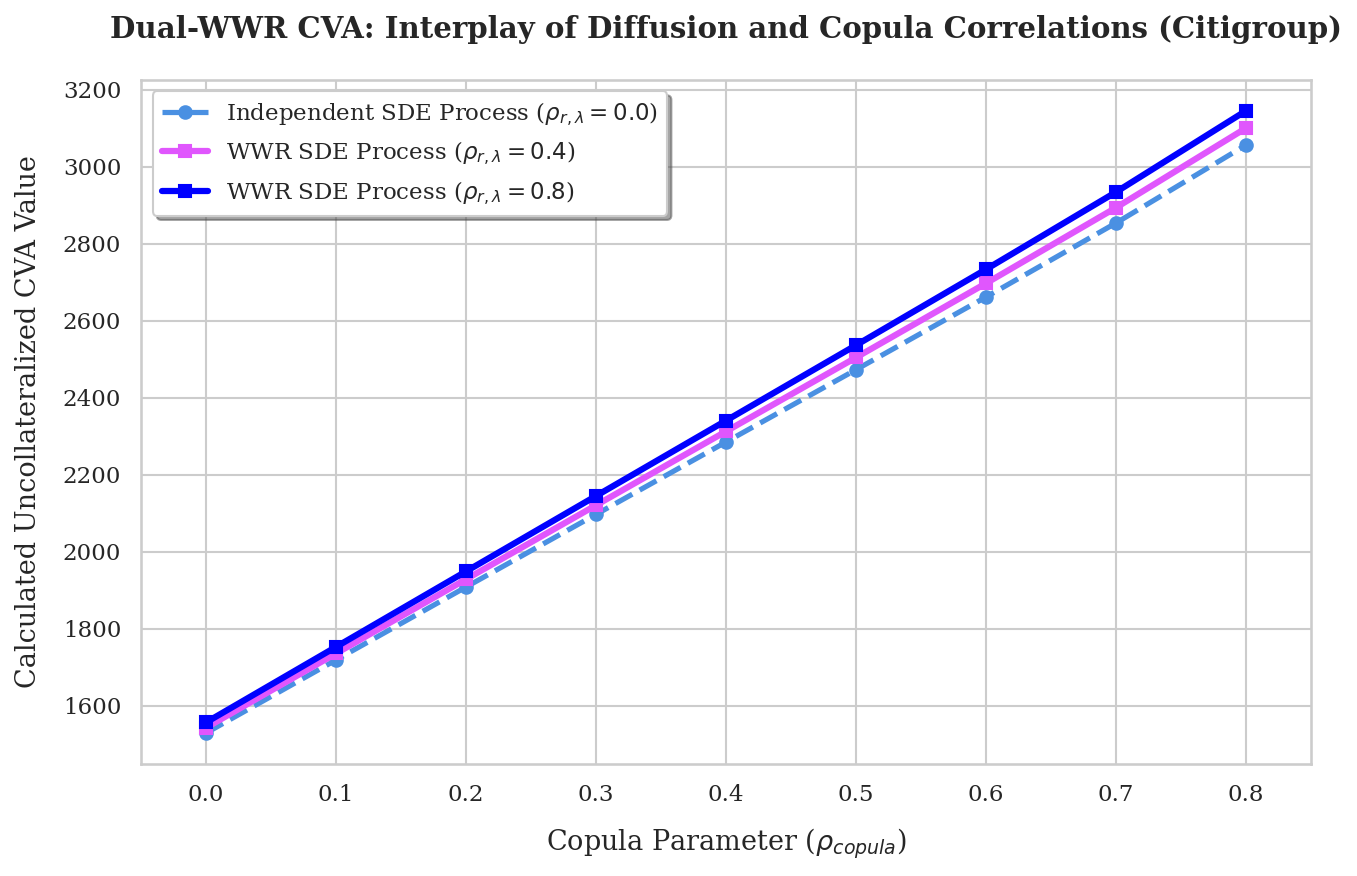

In [29]:
# Sweep rho_copula for three rho_r,lambda regimes.
import matplotlib.pyplot as plt
import seaborn as sns

rho_copula_steps = np.arange(0.0, 0.81, 0.1)
plot_rho_r_lambda = [0.0, 0.4, 0.8]

cva_sweep = {rho_r_lambda: [] for rho_r_lambda in plot_rho_r_lambda}
for rho_r_lambda in plot_rho_r_lambda:
    delta_Q_diff = delta_Q_cache[rho_r_lambda]
    for rho_copula in rho_copula_steps:
        w_copula = copula_path_weights_market_tau(E, u_tau_t, rho_copula)
        cva_val = compute_dual_wwr_cva(E, P_paths_Tm, delta_Q_diff, w_copula, P0_Tm, recovery_rate)
        cva_sweep[rho_r_lambda].append(cva_val)

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.family": "serif", "font.size": 12,
    "axes.labelsize": 13, "axes.titlesize": 14, "figure.dpi": 150,
})

fig, ax = plt.subplots(figsize=(9, 6))
line_styles = {
    0.0: dict(label=r"Independent SDE Process ($\rho_{r,\lambda}=0.0$)",
              color="#4A90E2", linestyle="--", linewidth=2.5, marker="o"),
    0.4: dict(label=r"WWR SDE Process ($\rho_{r,\lambda}=0.4$)",
              color="#E056FD", linestyle="-", linewidth=3.0, marker="s"),
    0.8: dict(label=r"WWR SDE Process ($\rho_{r,\lambda}=0.8$)",
              color="blue", linestyle="-", linewidth=3.0, marker="s"),
}
for rho_r_lambda in plot_rho_r_lambda:
    ax.plot(rho_copula_steps, cva_sweep[rho_r_lambda], markersize=6, **line_styles[rho_r_lambda])

ax.set_title("Dual-WWR CVA: Interplay of Diffusion and Copula Correlations (Citigroup)", pad=20, weight="bold")
ax.set_xlabel(r"Copula Parameter ($\rho_{copula}$)", labelpad=10)
ax.set_ylabel("Calculated Uncollateralized CVA Value", labelpad=10)
ax.set_xlim(-0.05, 0.85)
ax.legend(loc="upper left", frameon=True, shadow=True, fontsize=11)
plt.tight_layout()
plt.savefig("../results/dual_wwr_cva_cross-citi.png", bbox_inches="tight", dpi=300)
plt.show()

### Dual-Layer Correlation Sweep with a Student-t Copula

The sweep above is repeated with a Student-t copula in place of the Gaussian copula, to assess how the results respond to tail dependence.


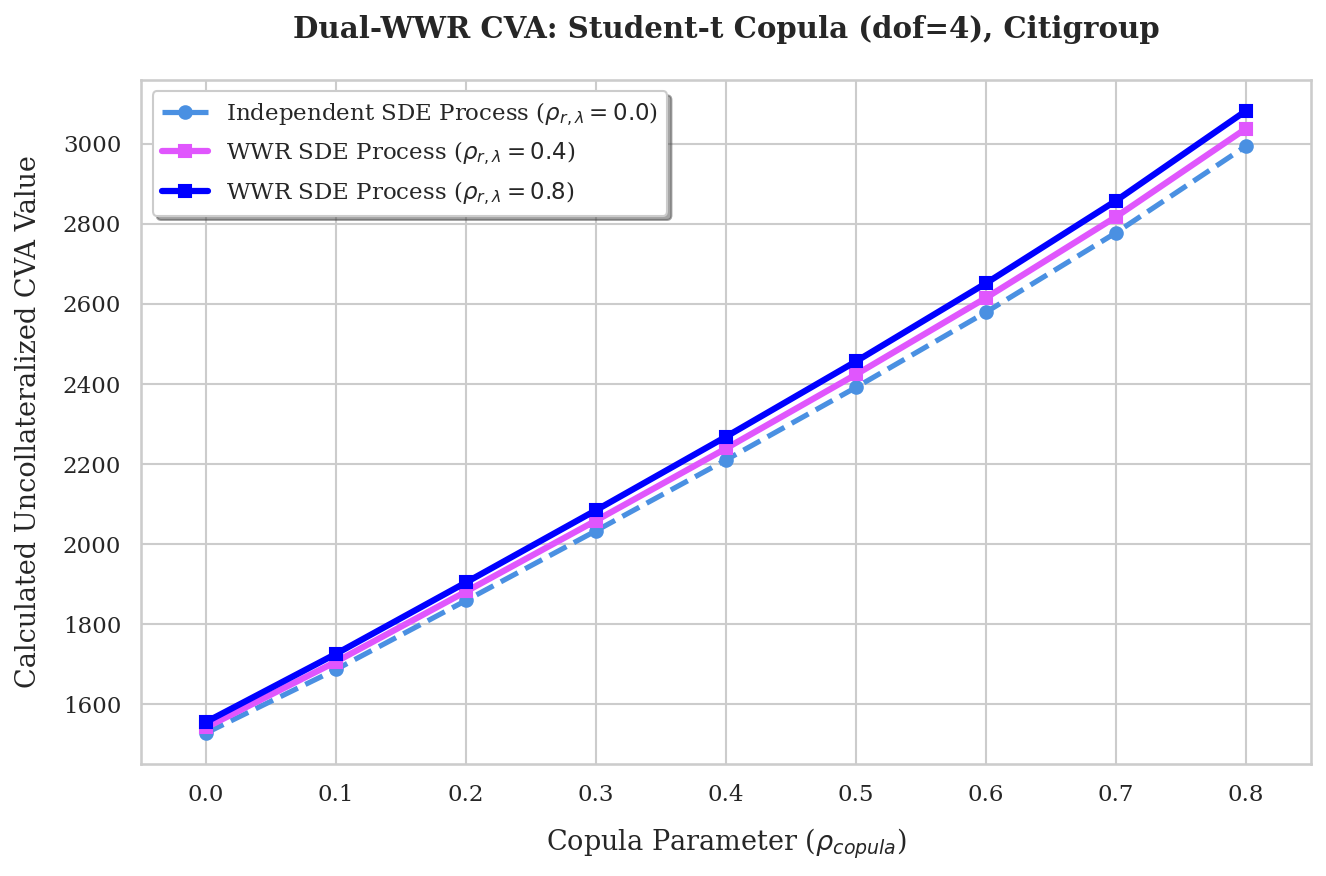


Gaussian vs Student-t (dof=4) at rho_r,lambda=0.4:
  rho_copula=0.0   Gaussian CVA=   1542.53   Student-t CVA=   1542.53   diff=   +0.00
  rho_copula=0.1   Gaussian CVA=   1735.48   Student-t CVA=   1706.86   diff=  -28.62
  rho_copula=0.2   Gaussian CVA=   1928.19   Student-t CVA=   1882.06   diff=  -46.14
  rho_copula=0.3   Gaussian CVA=   2120.46   Student-t CVA=   2059.19   diff=  -61.27
  rho_copula=0.4   Gaussian CVA=   2312.32   Student-t CVA=   2239.29   diff=  -73.03
  rho_copula=0.5   Gaussian CVA=   2504.14   Student-t CVA=   2423.86   diff=  -80.27
  rho_copula=0.6   Gaussian CVA=   2696.96   Student-t CVA=   2615.24   diff=  -81.72
  rho_copula=0.7   Gaussian CVA=   2893.43   Student-t CVA=   2817.35   diff=  -76.09
  rho_copula=0.8   Gaussian CVA=   3100.14   Student-t CVA=   3037.66   diff=  -62.48


In [30]:
# Sweep rho_copula for three rho_r,lambda regimes, using the Student-t Copula.
dof_student_t = 4
_eps = 1e-6
_n_paths = E.shape[1]
_ranks = np.argsort(np.argsort(E, axis=1), axis=1) + 1
_u_E = np.clip(_ranks / (_n_paths + 1), _eps, 1.0 - _eps)
_x_E_t = student_t.ppf(_u_E, dof_student_t)
_x_tau_t = student_t.ppf(np.clip(u_tau_t, _eps, 1.0 - _eps), dof_student_t)[:, np.newaxis]


def _student_t_weights_from_ranks(x_E, x_tau, rho_copula, dof):
    n_steps, n_paths = x_E.shape
    if abs(rho_copula) < 1e-12:
        return np.full((n_steps, n_paths), 1.0 / n_paths)
    rho2 = rho_copula ** 2
    quad_form = (x_E ** 2 - 2.0 * rho_copula * x_E * x_tau + x_tau ** 2) / (dof * (1.0 - rho2))
    log_bivariate = -0.5 * (dof + 2) * np.log1p(quad_form)
    log_marginal_E = -0.5 * (dof + 1) * np.log1p(x_E ** 2 / dof)
    log_marginal_tau = -0.5 * (dof + 1) * np.log1p(x_tau ** 2 / dof)
    log_const = (
        gammaln(dof / 2.0) + gammaln((dof + 2) / 2.0) - 2.0 * gammaln((dof + 1) / 2.0)
        - 0.5 * np.log(1.0 - rho2)
    )
    log_density = log_const + log_bivariate - log_marginal_E - log_marginal_tau
    density = np.exp(log_density)
    return density / np.sum(density, axis=1, keepdims=True)


cva_sweep_t = {rho_r_lambda: [] for rho_r_lambda in plot_rho_r_lambda}
for rho_r_lambda in plot_rho_r_lambda:
    delta_Q_diff = delta_Q_cache[rho_r_lambda]
    for rho_copula in rho_copula_steps:
        w_copula_t = _student_t_weights_from_ranks(_x_E_t, _x_tau_t, rho_copula, dof_student_t)
        cva_val_t = compute_dual_wwr_cva(E, P_paths_Tm, delta_Q_diff, w_copula_t, P0_Tm, recovery_rate)
        cva_sweep_t[rho_r_lambda].append(cva_val_t)

fig, ax = plt.subplots(figsize=(9, 6))
for rho_r_lambda in plot_rho_r_lambda:
    ax.plot(rho_copula_steps, cva_sweep_t[rho_r_lambda], markersize=6, **line_styles[rho_r_lambda])

ax.set_title(f"Dual-WWR CVA: Student-t Copula (dof={dof_student_t}), Citigroup", pad=20, weight="bold")
ax.set_xlabel(r"Copula Parameter ($\rho_{copula}$)", labelpad=10)
ax.set_ylabel("Calculated Uncollateralized CVA Value", labelpad=10)
ax.set_xlim(-0.05, 0.85)
ax.legend(loc="upper left", frameon=True, shadow=True, fontsize=11)
plt.tight_layout()
plt.savefig("../results/dual_wwr_cva_cross_student_t-citi.png", bbox_inches="tight", dpi=300)
plt.show()

print(f"\nGaussian vs Student-t (dof={dof_student_t}) at rho_r,lambda=0.4:")
for rho_copula, cva_g, cva_t in zip(rho_copula_steps, cva_sweep[0.4], cva_sweep_t[0.4]):
    print(f"  rho_copula={rho_copula:.1f}   Gaussian CVA={cva_g:10.2f}   Student-t CVA={cva_t:10.2f}   diff={cva_t - cva_g:+8.2f}")

## Part 3: Diagnostic Plots

Three diagnostics are produced from the simulated output: the zero-coupon bond price paths of Module 3, a cross-plot of the exposure-side discount factors against the hazard rate that verifies the WWR link, and the simulated IRS value paths together with the expected exposure profile of Module 5.


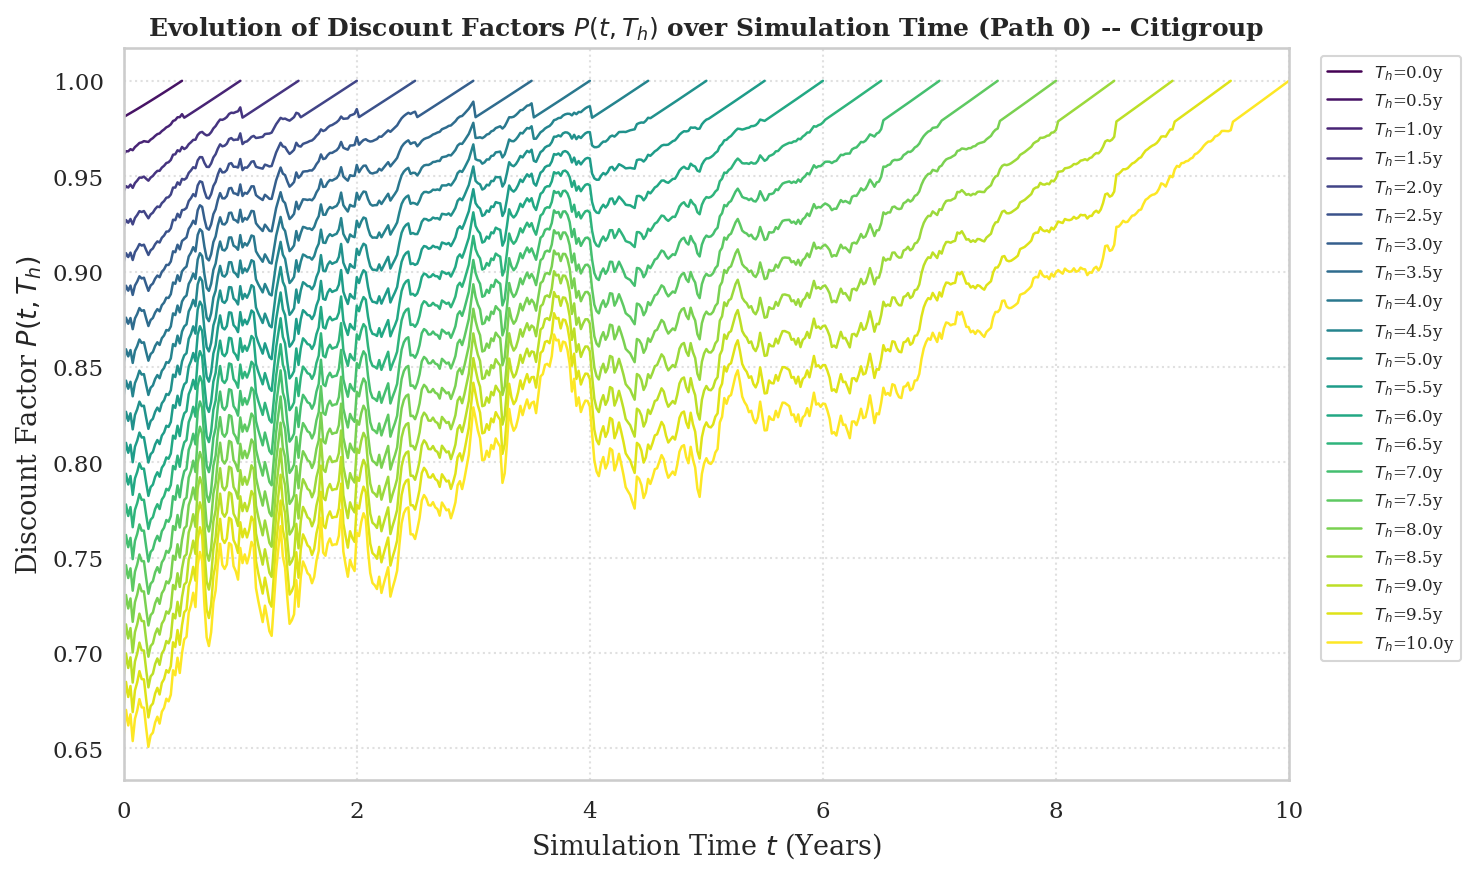

In [31]:
# Plot 1 - Evolution of P(t, T_h) for one simulated path across all payment dates
import matplotlib.pyplot as plt

path_idx = 0  # sample path to visualize

plt.figure(figsize=(10, 6), dpi=150)
cmap = plt.cm.viridis(np.linspace(0, 1, len(T_pay)))
for h, Th_label in enumerate(T_pay):
    active_steps = np.where(t_axis <= Th_label + 1e-9)[0]
    plt.plot(t_axis[active_steps], P_paths[active_steps, path_idx, h],
              color=cmap[h], linewidth=1.2, label=f"$T_h$={Th_label:.1f}y")

plt.title(f"Evolution of Discount Factors $P(t, T_h)$ over Simulation Time (Path {path_idx}) -- Citigroup",
          fontsize=12, weight="bold")
plt.xlabel("Simulation Time $t$ (Years)")
plt.ylabel("Discount Factor $P(t, T_h)$")
plt.xlim(0, max_years)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, ncol=1)
plt.tight_layout()
plt.savefig("../results/dual_wwr_discount_factor_paths-citi.png", bbox_inches="tight", dpi=300)
plt.show()

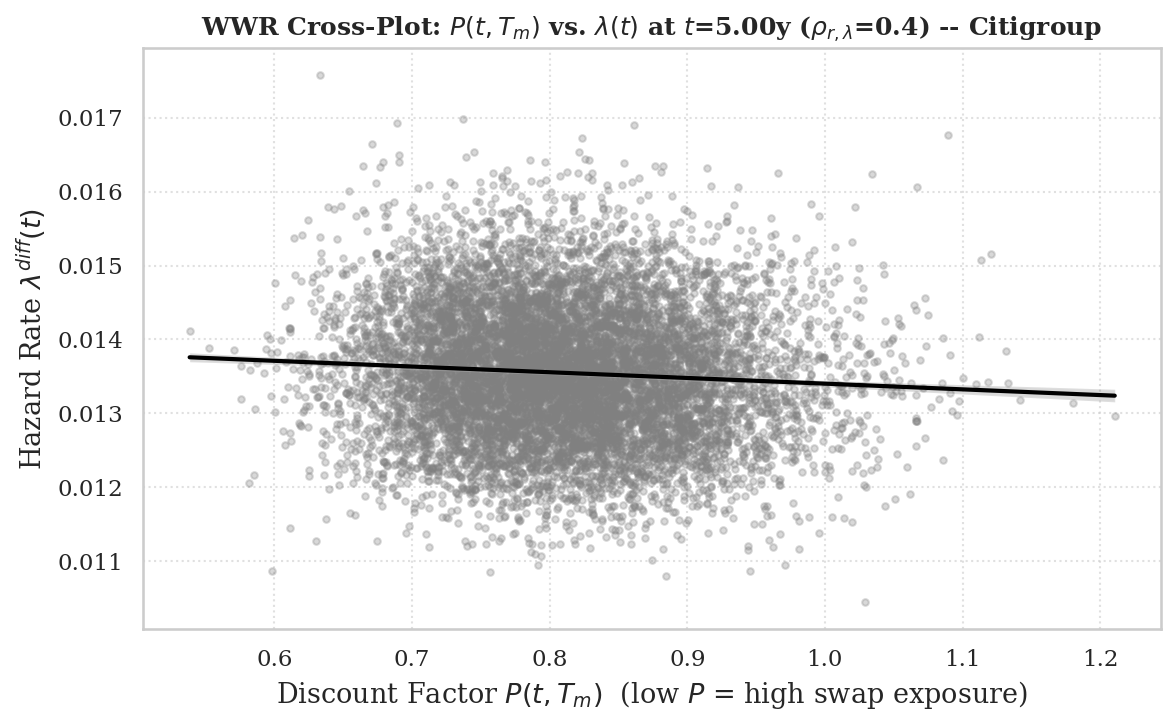

In [32]:
# Plot 2 - Cross-plot of P(t, T_m) vs. the hazard rate lambda(t), verifying the
# continuous-diffusion WWR link (Module 4). Uses the cached "Dual WWR" scenario
# (rho_r,lambda = 0.4) so the correlation is actually visible in the scatter.
import seaborn as sns

rho_r_lambda_plot = 0.4
lambda_diff_plot = lambda_cache[rho_r_lambda_plot]

t_idx = len(t_axis) // 2  # mid-simulation snapshot
P_at_t = P_paths[t_idx, :, -1]          # P(t_idx, T_m) across paths
lambda_at_t = lambda_diff_plot[t_idx, :]  # lambda^diff(t_idx) across paths

plt.figure(figsize=(8, 5), dpi=150)
sns.regplot(x=P_at_t, y=lambda_at_t,
            scatter_kws={"alpha": 0.3, "color": "gray", "s": 10},
            line_kws={"color": "black", "lw": 2})
plt.title(f"WWR Cross-Plot: $P(t,T_m)$ vs. $\\lambda(t)$ at $t$={t_axis[t_idx]:.2f}y "
          f"($\\rho_{{r,\\lambda}}$={rho_r_lambda_plot}) -- Citigroup", fontsize=12, weight="bold")
plt.xlabel("Discount Factor $P(t, T_m)$  (low $P$ = high swap exposure)")
plt.ylabel("Hazard Rate $\\lambda^{diff}(t)$")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("../results/dual_wwr_wwr_crossplot-citi.png", bbox_inches="tight", dpi=300)
plt.show()

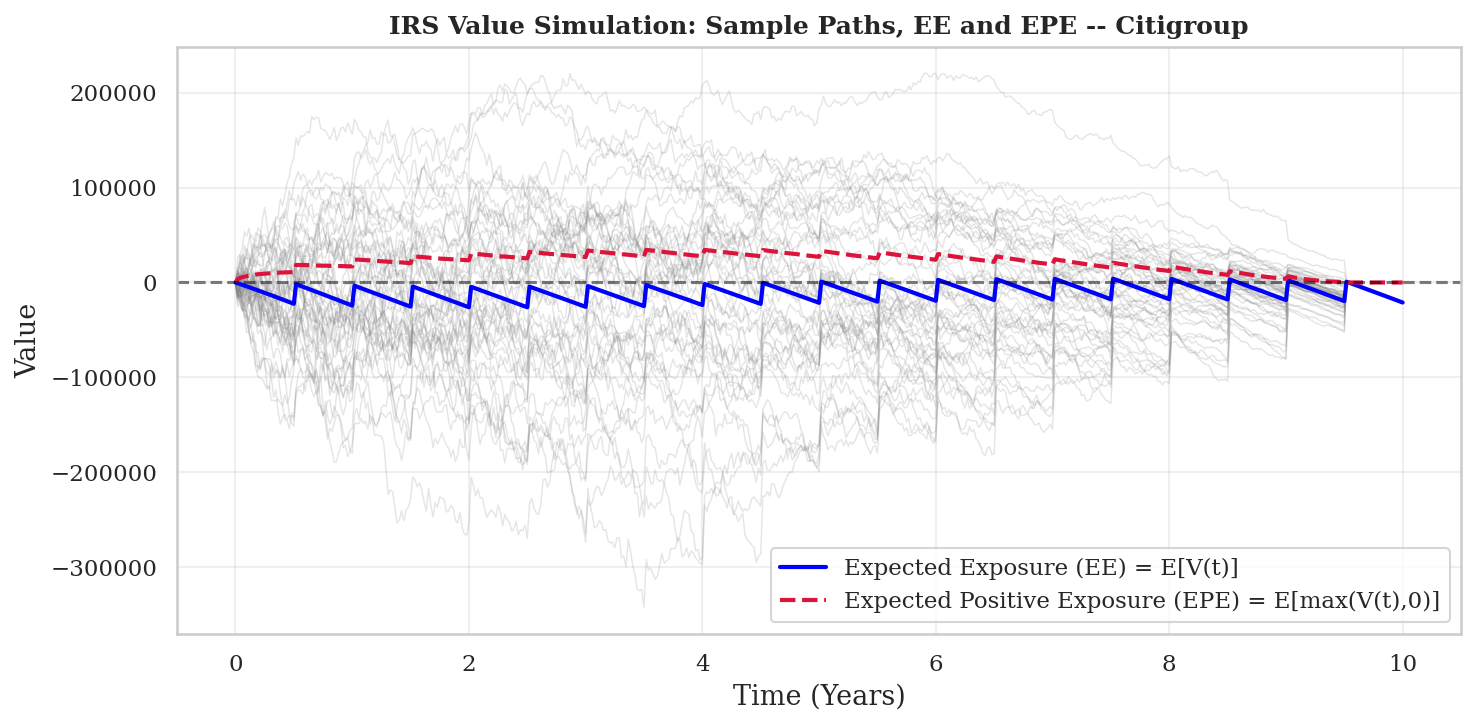

In [33]:
# Plot 3 - Simulated IRS value paths (Module 5) and Expected Exposure
n_sample_paths = 50
ee_curve = np.mean(V, axis=1)
epe_curve = np.mean(E, axis=1)

plt.figure(figsize=(10, 5), dpi=150)
plt.plot(t_axis, V[:, :n_sample_paths], color="gray", alpha=0.2, linewidth=0.7)
plt.plot(t_axis, ee_curve, color="blue", linewidth=2, label="Expected Exposure (EE) = E[V(t)]")
plt.plot(t_axis, epe_curve, color="crimson", linewidth=2, linestyle="--",
         label="Expected Positive Exposure (EPE) = E[max(V(t),0)]")
plt.axhline(0, color="black", linestyle="--", alpha=0.5)

plt.title("IRS Value Simulation: Sample Paths, EE and EPE -- Citigroup", fontsize=12, weight="bold")
plt.xlabel("Time (Years)")
plt.ylabel("Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("../results/dual_wwr_irs_exposure-citi.png", bbox_inches="tight", dpi=300)
plt.show()

## Part 4: AAD Sensitivities

Modules 3-7 are rebuilt in PyTorch so that a single `cva.backward()` call yields every Market Delta (SOFR/OIS curve and CDS-implied hazard curve), Model Vega ($\sigma_r$, $a$, $\kappa$, $\sigma_\lambda$) and WWR Rho ($\rho_{r,\lambda}$, $\rho_{copula}$) sensitivity in one backward pass.

QuantLib does not support PyTorch's automatic differentiation graph, so each market curve is represented by a frozen base curve, bootstrapped once by QuantLib, plus a differentiable per-pillar bump layer (`bump_interp`) implemented entirely in PyTorch tensor operations, which keeps the gradient chain unbroken. The Monte Carlo noise and the copula ranks are held as frozen constants (pathwise convention).


In [34]:
# Bump interpolation and CIR closed-form forward intensity
import torch


def bump_interp(t_query, bump_pillars, T_pillars):
    """Piecewise-linear interpolation of a small per-pillar bump, anchored at
    0 at t=0. The bump is exactly 0 everywhere when bump_pillars is 0."""
    dtype = bump_pillars.dtype
    T_ext = torch.cat([torch.zeros(1, dtype=dtype), T_pillars])
    b_ext = torch.cat([torch.zeros(1, dtype=dtype), bump_pillars])
    t_c = torch.clamp(t_query, T_ext[0], T_ext[-1])
    idx = torch.clamp(torch.searchsorted(T_ext.contiguous(), t_c.contiguous()) - 1, 0, len(T_ext) - 2)
    alpha = (t_c - T_ext[idx]) / (T_ext[idx + 1] - T_ext[idx] + 1e-14)
    return b_ext[idx] + alpha * (b_ext[idx + 1] - b_ext[idx])


def cir_forward_intensity(t, kappa, lambda_bar, sigma_lambda, x0):
    """Closed-form CIR forward intensity f_lambda^CIR(0,t) (same formula used in
    calibration), differentiable w.r.t. kappa, lambda_bar, sigma_lambda, x0."""
    h = torch.sqrt(kappa ** 2 + 2.0 * sigma_lambda ** 2)
    exp_ht = torch.exp(h * t)
    denom = 2.0 * h + (kappa + h) * (exp_ht - 1.0)
    term1 = (2.0 * kappa * lambda_bar * (exp_ht - 1.0)) / denom
    term2 = x0 * (4.0 * h ** 2 * exp_ht) / (denom ** 2)
    return term1 + term2


_TENOR_AAD = {
    "1W": 1/52, "2W": 2/52,
    "1M": 1/12, "2M": 2/12, "3M": 3/12, "6M": 6/12, "9M": 9/12,
    "1Y": 1., "2Y": 2., "3Y": 3., "4Y": 4., "5Y": 5.,
    "7Y": 7., "10Y": 10., "15Y": 15., "20Y": 20., "30Y": 30.,
}


In [35]:
# Module 3 (torch) - HW1F forward-measure ZCB simulation on frozen-exact + bump curve
def simulate_forward_zcb_paths_torch(yield_curve, a, sigma_r, bump_R, T_pillars_r, dW_r, t_axis, payment_dates, dtype):
    """
    Torch-differentiable version of Module 3, built on the EXACT frozen
    QuantLib discount curve plus a small differentiable bump. a, sigma_r,
    bump_R are differentiable leaves; dW_r is frozen Monte Carlo noise. At
    bump_R = 0 this reproduces the NumPy+QuantLib engine exactly.
    """
    payment_dates_np = np.asarray(payment_dates, dtype=float)
    payment_dates_t = torch.as_tensor(payment_dates_np, dtype=dtype)
    n_steps = len(t_axis)
    n_paths = dW_r.shape[1]
    T_m = payment_dates_t[-1]

    P0_pay_frozen = torch.tensor([yield_curve.discount(float(t)) for t in payment_dates_np], dtype=dtype)
    P0_grid_frozen = torch.tensor([yield_curve.discount(float(t)) for t in t_axis], dtype=dtype)
    t_axis_t = torch.as_tensor(t_axis, dtype=dtype)

    z_pay_frozen = -torch.log(P0_pay_frozen) / torch.clamp(payment_dates_t, min=1e-8)
    z_grid_frozen = -torch.log(P0_grid_frozen) / torch.clamp(t_axis_t, min=1e-8)

    P0_targets = torch.exp(-(z_pay_frozen + bump_interp(payment_dates_t, bump_R, T_pillars_r)) * payment_dates_t)
    P0_grid = torch.exp(-(z_grid_frozen + bump_interp(t_axis_t, bump_R, T_pillars_r)) * t_axis_t)
    P0_Tm = P0_targets[-1]

    FwdP = (P0_targets / P0_Tm).unsqueeze(0).repeat(n_paths, 1)
    P_paths = [P0_targets.unsqueeze(0).repeat(n_paths, 1)]

    for k in range(n_steps - 1):
        t_prev, t_curr = float(t_axis[k]), float(t_axis[k + 1])
        dt = t_curr - t_prev

        active_idx = np.where(payment_dates_np >= t_curr)[0]
        active_idx_t = torch.as_tensor(active_idx, dtype=torch.long)
        active_T = payment_dates_t[active_idx_t]

        sigma_P_Tm = (sigma_r / a) * (1.0 - torch.exp(-a * (T_m - t_prev)))
        sigma_P_active = (sigma_r / a) * (1.0 - torch.exp(-a * (active_T - t_prev)))
        Sigma_F = sigma_P_active - sigma_P_Tm

        FwdP_active = FwdP[:, active_idx_t] * torch.exp(
            -0.5 * (Sigma_F ** 2) * dt - Sigma_F.unsqueeze(0) * dW_r[k].unsqueeze(1)
        )
        FwdP_new = FwdP.clone()
        FwdP_new[:, active_idx_t] = FwdP_active
        FwdP = FwdP_new

        exact_idx = np.where(np.isclose(payment_dates_np, t_curr))[0]
        if len(exact_idx) > 0:
            FwdP_bench = FwdP[:, int(exact_idx[0])]
            P_tcurr_Tm = 1.0 / FwdP_bench
        else:
            next_idx = int(np.where(payment_dates_np > t_curr)[0][0])
            T_R = payment_dates_t[next_idx]
            FwdP_TR = FwdP[:, next_idx]
            tau = T_R - t_curr
            f_t_TR = (torch.log(P0_grid[k + 1]) - torch.log(P0_targets[next_idx])) / tau
            P_tcurr_TR = torch.exp(-f_t_TR * tau)
            P_tcurr_Tm = P_tcurr_TR / FwdP_TR

        P_paths.append(FwdP * P_tcurr_Tm.unsqueeze(1))

    return torch.stack(P_paths, dim=0), P0_Tm


In [36]:
# Module 4 (torch) - CIR++ hazard-rate simulation on frozen-exact + bump credit curve
def simulate_hazard_paths_torch(
    fm_curve_calibration, kappa, lambda_bar, sigma_lambda, x0,
    a, sigma_r, rho_r_lambda,
    bump_lambda, T_pillars_l, dW_lambda, t_axis, T_m, dtype,
):
    """Torch-differentiable version of Module 4, built on the EXACT frozen
    PCHIP-calibrated market hazard curve plus a small differentiable bump."""
    n_steps = len(t_axis)
    n_paths = dW_lambda.shape[1]
    dt = np.diff(t_axis)

    x_lambda = [x0.expand(n_paths).clone()]
    for k in range(n_steps - 1):
        t = float(t_axis[k])
        x_prev = torch.clamp(x_lambda[-1], min=0.0)
        sqrt_x = torch.sqrt(x_prev)

        wwr_term = (rho_r_lambda * sigma_lambda * sigma_r / a) * (1.0 - torch.exp(-a * (T_m - t))) * sqrt_x
        drift = (kappa * (lambda_bar - x_prev) - wwr_term) * dt[k]
        diffusion = sigma_lambda * sqrt_x * dW_lambda[k]
        milstein_corr = 0.25 * (sigma_lambda ** 2) * (dW_lambda[k] ** 2 - dt[k])

        x_next = torch.clamp(x_prev + drift + diffusion + milstein_corr, min=0.0)
        x_lambda.append(x_next)

    x_lambda = torch.stack(x_lambda, dim=0)

    t_axis_t = torch.as_tensor(np.asarray(t_axis, dtype=float), dtype=dtype)
    fM_frozen = torch.tensor(fm_curve_calibration(t_axis), dtype=dtype)
    fM = fM_frozen + bump_interp(t_axis_t, bump_lambda, T_pillars_l)
    fCIR = cir_forward_intensity(t_axis_t, kappa, lambda_bar, sigma_lambda, x0)
    b_lambda = fM - fCIR

    return x_lambda + b_lambda.unsqueeze(1)


def path_survival_probabilities_torch(lambda_diff, t_axis):
    """Torch-differentiable version of path_survival_probabilities."""
    n_steps, n_paths = lambda_diff.shape
    dtype = lambda_diff.dtype
    dt = torch.as_tensor(np.diff(t_axis), dtype=dtype).unsqueeze(1)

    integrated_hazard = lambda_diff[:-1, :] * dt
    logQ = -torch.cumsum(integrated_hazard, dim=0)
    Q = torch.cat([torch.ones((1, n_paths), dtype=dtype), torch.exp(logQ)], dim=0)
    delta_Q = Q[1:] - Q[:-1]
    return Q, delta_Q


### Market Delta Convention: Fixed $K$

The Market Delta is the sensitivity of the CVA of a trade that already exists on the book. The swap's fixed rate $K$ is therefore held at the original contract's par level, computed once from the unbumped curve (`compute_fixed_K`), and is not restruck to par under each bumped curve. Restriking $K$ would instead measure the CVA of a swap that is always struck at-the-money.

The two conventions differ in the sign of the parallel rate delta. Restriking $K$ largely cancels the effect that higher rates raise the value of a payer swap and hence its exposure and CVA, which leaves the discounting term ($P(0,T_m)$ falling as rates rise) to dominate. Holding $K$ fixed restores the positive parallel delta. All sensitivities in this notebook use the fixed-$K$ convention.


In [37]:
# Module 5 (torch) - IRS exposure valuation on frozen-exact + bump curve
def compute_fixed_K(yield_curve, payment_dates):
    """The swap's fixed (contractual) rate: breakeven under the ORIGINAL,
    unbumped curve. Computed once and held fixed for every subsequent bump --
    see the markdown note above on why Market Delta must be measured against
    an existing contract's fixed rate, not one re-struck under each bump."""
    Tk_np = np.asarray(payment_dates, dtype=float)
    P0_pay = np.array([yield_curve.discount(float(t)) for t in Tk_np])
    alphas = Tk_np[1:] - Tk_np[:-1]
    annuity = np.sum(alphas * P0_pay[1:])
    return float((P0_pay[0] - P0_pay[-1]) / annuity)


def simulate_irs_value_torch(P_paths, t_axis, payment_dates, notional, position_sign, dtype, K_fixed):
    """Torch-differentiable version of Module 5. K_fixed is a plain constant
    (see compute_fixed_K) -- it does NOT depend on bump_R, so Market Delta
    (d CVA/d bump_R) flows entirely through the simulated discount paths
    P_paths (Module 3), matching the standard convention of holding an
    EXISTING trade's fixed rate constant when computing its rate sensitivity."""
    n_steps, n_paths, n_targets = P_paths.shape
    Tk_np = np.asarray(payment_dates, dtype=float)
    Tk = torch.as_tensor(Tk_np, dtype=dtype)
    K = torch.as_tensor(K_fixed, dtype=dtype)

    alphas = Tk[1:] - Tk[:-1]
    m = len(Tk_np) - 1
    w_list = [torch.tensor(-1.0, dtype=dtype)]
    w_list += [K * alphas[i] for i in range(m - 1)]
    w_list += [1.0 + K * alphas[-1]]
    w = torch.stack(w_list)

    active_mask = Tk_np[np.newaxis, :] >= np.round(np.asarray(t_axis), 4)[:, np.newaxis]

    V_list = []
    for k in range(n_steps):
        active_idx = np.where(active_mask[k])[0]
        if len(active_idx) == 0:
            V_list.append(torch.zeros(n_paths, dtype=dtype))
            continue
        idx_t = torch.as_tensor(active_idx, dtype=torch.long)
        v_t = P_paths[k][:, idx_t] @ w[idx_t]
        if t_axis[k] > Tk_np[0]:
            v_t = v_t + w[0]
        V_list.append(v_t)

    V = torch.stack(V_list, dim=0) * (position_sign * notional)
    E = torch.clamp(V, min=0.0)
    return V, E, K

In [38]:
# Module 6 (torch) - Gaussian Copula weights, frozen ranks (Market Delta decoupling)
def frozen_copula_ranks(E_frozen_np, u_tau_t_np, eps=1e-6):
    """
    Precompute the frozen (non-differentiable) Copula rank transform x_E, x_tau
    from a reference realization of the exposure and the market-implied,
    deterministic, time-varying jump-WWR latent variable u_tau_t (Module 6,
    market-implied). Per the Market Delta decoupling convention, these ranks
    are treated as CONSTANTS for every theta except rho_copula.
    """
    n_steps, n_paths = E_frozen_np.shape
    ranks = np.argsort(np.argsort(E_frozen_np, axis=1), axis=1) + 1
    u_E = np.clip(ranks / (n_paths + 1), eps, 1.0 - eps)
    x_E = norm.ppf(u_E)
    x_tau = norm.ppf(np.clip(u_tau_t_np, eps, 1.0 - eps))
    return (
        torch.as_tensor(x_E, dtype=torch.float64),
        torch.as_tensor(x_tau, dtype=torch.float64),
    )


def copula_path_weights_torch(x_E, x_tau, rho_copula, eps=1e-12):
    """Gaussian Copula weights (Module 6, market-implied) as a differentiable
    function of rho_copula ONLY -- x_E, x_tau are frozen constants (see
    frozen_copula_ranks). x_tau is broadcast over the PATHS axis (n_steps, 1),
    the opposite convention from the original per-path-random x_tau (1, n_paths),
    since u_tau_t now varies by time step, not by path. This is what makes
    Term 3 (Copula Channel) vanish for every theta except rho_copula."""
    rho2 = rho_copula ** 2
    x_tau_col = x_tau.unsqueeze(1)
    log_density = -(rho2 * (x_E ** 2 + x_tau_col ** 2) - 2.0 * rho_copula * x_E * x_tau_col) / (2.0 * (1.0 - rho2 + eps))
    density = torch.exp(log_density) / torch.sqrt(1.0 - rho2 + eps)
    return density / torch.sum(density, dim=1, keepdim=True)


In [39]:
# Module 7 (torch) - Final CVA aggregation
def compute_dual_wwr_cva_torch(E, P_paths_Tm, delta_Q_diff, w_copula, P0_Tm, recovery_rate):
    """Torch-differentiable version of Module 7."""
    rebased_exposure = E[1:, :] / P_paths_Tm[1:, :]
    weighted_sum = rebased_exposure * w_copula[1:, :] * delta_Q_diff
    loss_given_default = 1.0 - recovery_rate
    return -loss_given_default * P0_Tm * torch.sum(weighted_sum)


In [40]:
# End-to-end AAD driver
def build_frozen_noise(t_axis, n_paths, seed=1234):
    """Module 2, frozen: draws Z1, Z2 (antithetic) once with NumPy. u_tau_t is no
    longer drawn here -- it is the deterministic market-implied curve from
    compute_market_implied_u_tau, independent of the Monte Carlo seed."""
    n_steps = len(t_axis)
    rng = np.random.default_rng(seed)
    half = n_paths // 2
    Z1_half = rng.standard_normal((n_steps - 1, half))
    Z2_half = rng.standard_normal((n_steps - 1, half))
    Z1 = np.concatenate([Z1_half, -Z1_half], axis=1)
    Z2 = np.concatenate([Z2_half, -Z2_half], axis=1)
    return Z1, Z2


def run_aad_sensitivities(
    yield_curve, fm_curve_calibration, sofr_market_quotes, cds_market_data,
    a0, sigma_r0, kappa0, lambda_bar0, sigma_lambda0, x_lambda_0,
    rho_r_lambda0, rho_copula0,
    payment_dates, notional, position_sign, recovery_rate,
    T_max, n_paths, seed=1234, steps_per_year=26, dtype=torch.float64,
    lambda_jump_assumed=None,
    theta_R_shift=0.0, theta_lambda_shift=0.0,
):
    """
    End-to-end differentiable dual-WWR CVA: every theta in the classification
    table is a leaf tensor, every other input is frozen Monte Carlo noise (or,
    for the market curves, the exact frozen QuantLib/PCHIP curve plus a
    differentiable bump). A single cva.backward() call yields the full
    sensitivity vector.
    """
    sofr_tenors = list(sofr_market_quotes.keys())
    T_pillars_r = torch.tensor([_TENOR_AAD[t] for t in sofr_tenors], dtype=dtype)
    # theta_R_shift: parallel re-centering point for the Market Delta leaf
    # (0.0 for every existing call site; nonzero only for the cross-gamma
    # finite-difference driver below, which evaluates the OTHER curve's
    # Delta at a shifted parallel bump on this curve).
    bump_R = torch.full((len(sofr_tenors),), theta_R_shift, dtype=dtype, requires_grad=True)

    cds_tenors = list(cds_market_data.keys())
    T_pillars_l = torch.tensor([_TENOR_AAD[t] for t in cds_tenors], dtype=dtype)
    bump_lambda = torch.full((len(cds_tenors),), theta_lambda_shift, dtype=dtype, requires_grad=True)

    a = torch.tensor(a0, dtype=dtype, requires_grad=True)
    sigma_r = torch.tensor(sigma_r0, dtype=dtype, requires_grad=True)
    kappa = torch.tensor(kappa0, dtype=dtype, requires_grad=True)
    lambda_bar = torch.tensor(lambda_bar0, dtype=dtype, requires_grad=True)
    sigma_lambda = torch.tensor(sigma_lambda0, dtype=dtype, requires_grad=True)
    x0 = torch.tensor(x_lambda_0, dtype=dtype, requires_grad=True)
    rho_r_lambda = torch.tensor(rho_r_lambda0, dtype=dtype, requires_grad=True)
    rho_copula = torch.tensor(rho_copula0, dtype=dtype, requires_grad=True)

    if lambda_jump_assumed is None:
        lambda_jump_assumed = LAMBDA_JUMP_ASSUMED

    # Fixed contractual K: the ORIGINAL trade's breakeven rate under the
    # unbumped curve, independent of theta_R_shift/bump_R (see the Market
    # Delta convention note above Module 5 (torch)).
    K_fixed = compute_fixed_K(yield_curve, payment_dates)

    n_steps = int(round(T_max * steps_per_year)) + 1
    t_axis = np.linspace(0.0, T_max, n_steps)
    Z1, Z2 = build_frozen_noise(t_axis, n_paths, seed=seed)
    u_tau_t_np = compute_market_implied_u_tau(t_axis, lambda_jump_assumed)

    dt_np = np.diff(t_axis)
    sqrt_dt_t = torch.as_tensor(dt_np ** 0.5, dtype=dtype).unsqueeze(1)
    Z1_t = torch.as_tensor(Z1, dtype=dtype)
    Z2_t = torch.as_tensor(Z2, dtype=dtype)

    dW_r = Z1_t * sqrt_dt_t
    dW_lambda = (rho_r_lambda * Z1_t + torch.sqrt(1.0 - rho_r_lambda ** 2) * Z2_t) * sqrt_dt_t

    T_m = payment_dates[-1]

    P_paths, P0_Tm = simulate_forward_zcb_paths_torch(
        yield_curve, a, sigma_r, bump_R, T_pillars_r, dW_r, t_axis, payment_dates, dtype,
    )
    lambda_diff = simulate_hazard_paths_torch(
        fm_curve_calibration, kappa, lambda_bar, sigma_lambda, x0, a, sigma_r, rho_r_lambda,
        bump_lambda, T_pillars_l, dW_lambda, t_axis, T_m, dtype,
    )
    Q_diff, delta_Q_diff = path_survival_probabilities_torch(lambda_diff, t_axis)
    V, E, K = simulate_irs_value_torch(
        P_paths, t_axis, payment_dates, notional, position_sign, dtype, K_fixed,
    )

    E_frozen_np = E.detach().numpy()
    x_E, x_tau = frozen_copula_ranks(E_frozen_np, u_tau_t_np)
    w_copula = copula_path_weights_torch(x_E, x_tau, rho_copula)

    P_paths_Tm = P_paths[:, :, -1]
    cva = compute_dual_wwr_cva_torch(E, P_paths_Tm, delta_Q_diff, w_copula, P0_Tm, recovery_rate)

    cva.backward()

    return {
        "cva": cva.item(),
        "bump_R": bump_R, "sofr_tenors": sofr_tenors,
        "bump_lambda": bump_lambda, "cds_tenors": cds_tenors,
        "a": a, "sigma_r": sigma_r, "kappa": kappa, "lambda_bar": lambda_bar,
        "sigma_lambda": sigma_lambda, "x0": x0,
        "rho_r_lambda": rho_r_lambda, "rho_copula": rho_copula,
    }


### AAD Sensitivity Report across the WWR Scenarios

The AAD engine is run for five scenarios (Independent, Diffusion-only, Jump-only, Dual and Dual-strong). For each scenario, the base CVA is cross-checked against the NumPy engine at matched Monte Carlo settings (3,000 paths, seed 1234), and every Market Delta, Model Vega and WWR Rho sensitivity is reported, using the Citigroup calibration and $\lambda^{jump}=0.0417$.


In [41]:
# AAD sensitivity report across the five canonical WWR scenarios, plus a
# same-settings NumPy-engine CVA for direct comparison.
AAD_N_PATHS = 3000
AAD_STEPS_PER_YEAR = 26
AAD_SEED = 1234

def numpy_engine_cva(rho_r_lambda, rho_copula, n_paths=AAD_N_PATHS, steps_per_year=AAD_STEPS_PER_YEAR, seed=AAD_SEED):
    """Same Modules 1-7 NumPy pipeline as Part 2, at matched Monte Carlo settings."""
    t_axis_np, _ = build_time_grid(max_years, steps_per_year)
    randoms_np = generate_dual_wwr_randoms(t_axis_np, n_paths, rho_r_lambda, seed=seed)
    P_paths_np = simulate_forward_zcb_paths(sofr_yield_curve_calibrated, a_calibrated, sigma_r_calibrated, randoms_np["dW_r"], t_axis_np, T_pay)
    lambda_diff_np = simulate_hazard_paths(kappa_calibration, lambda_bar_calibration, sigma_lambda_calibration, x_lambda_0, a_calibrated, sigma_r_calibrated, rho_r_lambda, bl_func_calibration, randoms_np["dW_lambda"], t_axis_np, T_pay[-1])
    _, delta_Q_np = path_survival_probabilities(lambda_diff_np, t_axis_np)
    _, E_np, _ = simulate_irs_value(P_paths_np, t_axis_np, T_pay, notional, swap_config["delta"], sofr_yield_curve_calibrated)
    u_tau_t_np = compute_market_implied_u_tau(t_axis_np, LAMBDA_JUMP_ASSUMED)
    w_np = copula_path_weights_market_tau(E_np, u_tau_t_np, rho_copula)
    P_Tm_np = P_paths_np[:, :, -1]
    P0_Tm_np = sofr_yield_curve_calibrated.discount(float(T_pay[-1]))
    return compute_dual_wwr_cva(E_np, P_Tm_np, delta_Q_np, w_np, P0_Tm_np, recovery_rate)


aad_scenarios = [
    ("Independent",     0.0, 0.0),
    ("Diffusion-only",  0.4, 0.0),
    ("Jump-only",        0.0, 0.4),
    ("Dual",             0.4, 0.4),
    ("Dual-strong",      0.8, 0.8),
]

aad_results = {}
for label, rho_r_lambda, rho_copula in aad_scenarios:
    cva_np = numpy_engine_cva(rho_r_lambda, rho_copula)
    result = run_aad_sensitivities(
        yield_curve=sofr_yield_curve_calibrated, fm_curve_calibration=fm_curve_calibration,
        sofr_market_quotes=sofr_market_quotes, cds_market_data=cds_market_data,
        a0=a_calibrated, sigma_r0=sigma_r_calibrated,
        kappa0=kappa_calibration, lambda_bar0=lambda_bar_calibration,
        sigma_lambda0=sigma_lambda_calibration, x_lambda_0=x_lambda_0,
        rho_r_lambda0=rho_r_lambda, rho_copula0=rho_copula,
        payment_dates=T_pay, notional=notional, position_sign=swap_config["delta"],
        recovery_rate=recovery_rate,
        T_max=max_years, n_paths=AAD_N_PATHS, seed=AAD_SEED, steps_per_year=AAD_STEPS_PER_YEAR,
    )
    aad_results[label] = result
    cva_aad_val = result["cva"]
    rel_diff = (cva_aad_val - cva_np) / cva_np
    print(f"=== {label} (rho_r,lambda={rho_r_lambda}, rho_copula={rho_copula}) ===")
    print(f"  NumPy engine CVA = {cva_np:10.4f}   AAD engine CVA = {cva_aad_val:10.4f}   rel_diff = {rel_diff:+.4%}")

    print("  [Market Delta -- SOFR/OIS par curve, bump_R]")
    for tenor, grad in zip(result["sofr_tenors"], result["bump_R"].grad):
        print(f"    R_h[{tenor:4s}]  dCVA/dbump = {grad.item():+12.4f}   (per 1bp = {grad.item()*1e-4:+8.4f})")

    print("  [Market Delta -- CDS-implied hazard curve, bump_lambda]")
    for tenor, grad in zip(result["cds_tenors"], result["bump_lambda"].grad):
        print(f"    lambda_h[{tenor:4s}]  dCVA/dbump = {grad.item():+12.4f}   (per 1bp = {grad.item()*1e-4:+8.4f})")

    print("  [Model Vega]")
    sigma_r_grad = result["sigma_r"].grad.item()
    a_grad = result["a"].grad.item()
    kappa_grad = result["kappa"].grad.item()
    sigma_lambda_grad = result["sigma_lambda"].grad.item()
    print(f"    sigma_r={sigma_r_grad:+12.4f}   a={a_grad:+12.4f}   kappa={kappa_grad:+12.4f}   sigma_lambda={sigma_lambda_grad:+12.4f}")

    print("  [WWR Rho]")
    rho_rl_grad = result["rho_r_lambda"].grad.item()
    rho_cop_grad = result["rho_copula"].grad.item()
    print(f"    rho_r,lambda={rho_rl_grad:+12.4f}   rho_copula={rho_cop_grad:+12.4f}")
    print()


=== Independent (rho_r,lambda=0.0, rho_copula=0.0) ===
  NumPy engine CVA =  1507.2997   AAD engine CVA =  1507.3552   rel_diff = +0.0037%
  [Market Delta -- SOFR/OIS par curve, bump_R]
    R_h[1M  ]  dCVA/dbump =     -15.7494   (per 1bp =  -0.0016)
    R_h[3M  ]  dCVA/dbump =     -58.1089   (per 1bp =  -0.0058)
    R_h[6M  ]  dCVA/dbump =    -253.0532   (per 1bp =  -0.0253)
    R_h[1Y  ]  dCVA/dbump =   -1304.5402   (per 1bp =  -0.1305)
    R_h[2Y  ]  dCVA/dbump =  -12388.5584   (per 1bp =  -1.2389)
    R_h[5Y  ]  dCVA/dbump =  -76971.5625   (per 1bp =  -7.6972)
    R_h[10Y ]  dCVA/dbump = +194583.9734   (per 1bp = +19.4584)
    R_h[30Y ]  dCVA/dbump =      +0.0000   (per 1bp =  +0.0000)
  [Market Delta -- CDS-implied hazard curve, bump_lambda]
    lambda_h[6M  ]  dCVA/dbump =   +3981.8701   (per 1bp =  +0.3982)
    lambda_h[1Y  ]  dCVA/dbump =   +9317.3107   (per 1bp =  +0.9317)
    lambda_h[2Y  ]  dCVA/dbump =  +15137.2488   (per 1bp =  +1.5137)
    lambda_h[3Y  ]  dCVA/dbump =  +24

=== Diffusion-only (rho_r,lambda=0.4, rho_copula=0.0) ===
  NumPy engine CVA =  1520.7790   AAD engine CVA =  1520.8345   rel_diff = +0.0036%
  [Market Delta -- SOFR/OIS par curve, bump_R]
    R_h[1M  ]  dCVA/dbump =     -16.4291   (per 1bp =  -0.0016)
    R_h[3M  ]  dCVA/dbump =     -61.5970   (per 1bp =  -0.0062)
    R_h[6M  ]  dCVA/dbump =    -263.3553   (per 1bp =  -0.0263)
    R_h[1Y  ]  dCVA/dbump =   -1331.4620   (per 1bp =  -0.1331)
    R_h[2Y  ]  dCVA/dbump =  -12478.1858   (per 1bp =  -1.2478)
    R_h[5Y  ]  dCVA/dbump =  -77113.0519   (per 1bp =  -7.7113)
    R_h[10Y ]  dCVA/dbump = +195728.7382   (per 1bp = +19.5729)
    R_h[30Y ]  dCVA/dbump =      +0.0000   (per 1bp =  +0.0000)
  [Market Delta -- CDS-implied hazard curve, bump_lambda]
    lambda_h[6M  ]  dCVA/dbump =   +3975.1079   (per 1bp =  +0.3975)
    lambda_h[1Y  ]  dCVA/dbump =   +9307.2770   (per 1bp =  +0.9307)
    lambda_h[2Y  ]  dCVA/dbump =  +15124.3537   (per 1bp =  +1.5124)
    lambda_h[3Y  ]  dCVA/dbump =  

=== Jump-only (rho_r,lambda=0.0, rho_copula=0.4) ===
  NumPy engine CVA =  2256.3739   AAD engine CVA =  2256.5157   rel_diff = +0.0063%
  [Market Delta -- SOFR/OIS par curve, bump_R]
    R_h[1M  ]  dCVA/dbump =     -30.8636   (per 1bp =  -0.0031)
    R_h[3M  ]  dCVA/dbump =    -114.4102   (per 1bp =  -0.0114)
    R_h[6M  ]  dCVA/dbump =    -447.8506   (per 1bp =  -0.0448)
    R_h[1Y  ]  dCVA/dbump =   -2134.7414   (per 1bp =  -0.2135)
    R_h[2Y  ]  dCVA/dbump =  -17819.3184   (per 1bp =  -1.7819)
    R_h[5Y  ]  dCVA/dbump =  -96754.8592   (per 1bp =  -9.6755)
    R_h[10Y ]  dCVA/dbump = +260902.0475   (per 1bp = +26.0902)
    R_h[30Y ]  dCVA/dbump =      +0.0000   (per 1bp =  +0.0000)
  [Market Delta -- CDS-implied hazard curve, bump_lambda]
    lambda_h[6M  ]  dCVA/dbump =  +10360.4345   (per 1bp =  +1.0360)
    lambda_h[1Y  ]  dCVA/dbump =  +20099.0574   (per 1bp =  +2.0099)
    lambda_h[2Y  ]  dCVA/dbump =  +28622.2680   (per 1bp =  +2.8622)
    lambda_h[3Y  ]  dCVA/dbump =  +4025

=== Dual (rho_r,lambda=0.4, rho_copula=0.4) ===
  NumPy engine CVA =  2283.5037   AAD engine CVA =  2283.6453   rel_diff = +0.0062%
  [Market Delta -- SOFR/OIS par curve, bump_R]
    R_h[1M  ]  dCVA/dbump =     -32.7529   (per 1bp =  -0.0033)
    R_h[3M  ]  dCVA/dbump =    -123.3913   (per 1bp =  -0.0123)
    R_h[6M  ]  dCVA/dbump =    -472.1937   (per 1bp =  -0.0472)
    R_h[1Y  ]  dCVA/dbump =   -2190.6951   (per 1bp =  -0.2191)
    R_h[2Y  ]  dCVA/dbump =  -17969.2819   (per 1bp =  -1.7969)
    R_h[5Y  ]  dCVA/dbump =  -96899.4416   (per 1bp =  -9.6899)
    R_h[10Y ]  dCVA/dbump = +263031.7383   (per 1bp = +26.3032)
    R_h[30Y ]  dCVA/dbump =      +0.0000   (per 1bp =  +0.0000)
  [Market Delta -- CDS-implied hazard curve, bump_lambda]
    lambda_h[6M  ]  dCVA/dbump =  +10347.0266   (per 1bp =  +1.0347)
    lambda_h[1Y  ]  dCVA/dbump =  +20079.9347   (per 1bp =  +2.0080)
    lambda_h[2Y  ]  dCVA/dbump =  +28599.0576   (per 1bp =  +2.8599)
    lambda_h[3Y  ]  dCVA/dbump =  +40226.809

=== Dual-strong (rho_r,lambda=0.8, rho_copula=0.8) ===
  NumPy engine CVA =  3119.3504   AAD engine CVA =  3119.6234   rel_diff = +0.0088%
  [Market Delta -- SOFR/OIS par curve, bump_R]
    R_h[1M  ]  dCVA/dbump =     -46.4872   (per 1bp =  -0.0046)
    R_h[3M  ]  dCVA/dbump =    -191.7650   (per 1bp =  -0.0192)
    R_h[6M  ]  dCVA/dbump =    -708.8851   (per 1bp =  -0.0709)
    R_h[1Y  ]  dCVA/dbump =   -3209.0156   (per 1bp =  -0.3209)
    R_h[2Y  ]  dCVA/dbump =  -25518.6424   (per 1bp =  -2.5519)
    R_h[5Y  ]  dCVA/dbump = -128493.3014   (per 1bp = -12.8493)
    R_h[10Y ]  dCVA/dbump = +361167.7858   (per 1bp = +36.1168)
    R_h[30Y ]  dCVA/dbump =      +0.0000   (per 1bp =  +0.0000)
  [Market Delta -- CDS-implied hazard curve, bump_lambda]
    lambda_h[6M  ]  dCVA/dbump =  +20366.9980   (per 1bp =  +2.0367)
    lambda_h[1Y  ]  dCVA/dbump =  +35982.2407   (per 1bp =  +3.5982)
    lambda_h[2Y  ]  dCVA/dbump =  +46872.6033   (per 1bp =  +4.6873)
    lambda_h[3Y  ]  dCVA/dbump =  +58

### LaTeX Tables for the AAD Sensitivities

The three `threeparttable` LaTeX tables of the thesis (Market Delta for the SOFR/OIS curve, Market Delta for the CDS-implied hazard curve, and Model Vega with WWR Rho) are generated from `aad_results`.


In [42]:
# Build LaTeX threeparttable tables for the AAD sensitivities, scenarios as columns.
def latex_sensitivity_table(row_labels, get_value, scenario_labels, caption, label, notes, value_fmt="{:.4f}"):
    col_spec = "l" + "c" * len(scenario_labels)
    lines = []
    lines.append(r"\begin{table}[htbp]")
    lines.append(r"    \centering")
    lines.append(r"    \begin{threeparttable}")
    lines.append(f"        \\caption{{{caption}}}")
    lines.append(f"        \\label{{{label}}}")
    lines.append(r"        \renewcommand{\arraystretch}{1.25}")
    lines.append(r"        \begin{tabular}{" + col_spec + "}")
    lines.append(r"            \toprule")
    header = r"            \textbf{Parameter} & " + " & ".join(f"\\textbf{{{s}}}" for s in scenario_labels) + r" \\"
    lines.append(header)
    lines.append(r"            \midrule")
    for row in row_labels:
        vals = " & ".join(value_fmt.format(get_value(row, s)) for s in scenario_labels)
        lines.append(f"            {row} & {vals} " + r"\\")
    lines.append(r"            \bottomrule")
    lines.append(r"        \end{tabular}")
    lines.append(r"        \begin{tablenotes}")
    lines.append(r"            \small")
    lines.append(f"            \\item \\textit{{Notes:}} {notes}")
    lines.append(r"        \end{tablenotes}")
    lines.append(r"    \end{threeparttable}")
    lines.append(r"\end{table}")
    return "\n".join(lines)


scenario_labels = list(aad_results.keys())

# Table 1: Market Delta -- SOFR/OIS curve DV01
sofr_tenors_list = aad_results[scenario_labels[0]]["sofr_tenors"]

def get_sofr_dv01(tenor, scenario):
    r = aad_results[scenario]
    idx = r["sofr_tenors"].index(tenor)
    return r["bump_R"].grad[idx].item() * 1e-4

print(latex_sensitivity_table(
    sofr_tenors_list, get_sofr_dv01, scenario_labels,
    caption="Market Delta -- SOFR/OIS Curve DV01 (per 1bp) by WWR Scenario",
    label="tab:sofr_delta",
    notes=(
        "DV01 is $\\partial CVA/\\partial R_h$ scaled to a 1bp parallel bump at each "
        "SOFR/OIS pillar, reported in absolute CVA units (USD) for a \\$1M notional 10Y payer swap."
    ),
))
print()

# Table 2: Market Delta -- CDS-implied hazard curve CS01
cds_tenors_list = aad_results[scenario_labels[0]]["cds_tenors"]

def get_cds_cs01(tenor, scenario):
    r = aad_results[scenario]
    idx = r["cds_tenors"].index(tenor)
    return r["bump_lambda"].grad[idx].item() * 1e-4

print(latex_sensitivity_table(
    cds_tenors_list, get_cds_cs01, scenario_labels,
    caption="Market Delta -- CDS-Implied Hazard Curve CS01 (per 1bp) by WWR Scenario",
    label="tab:cds_delta",
    notes="CS01 is $\\partial CVA/\\partial \\lambda_h$ scaled to a 1bp parallel bump at each CDS-implied hazard pillar.",
))
print()

# Table 3: Model Vega and WWR Rho
vega_rho_params = [
    ("$\\sigma_r$", "sigma_r"),
    ("$a$", "a"),
    ("$\\kappa$", "kappa"),
    ("$\\sigma_\\lambda$", "sigma_lambda"),
    ("$\\rho_{r,\\lambda}$", "rho_r_lambda"),
    ("$\\rho_{copula}$", "rho_copula"),
]

def get_vega_rho(param_label, scenario):
    key = dict(vega_rho_params)[param_label]
    return aad_results[scenario][key].grad.item()

print(latex_sensitivity_table(
    [p[0] for p in vega_rho_params], get_vega_rho, scenario_labels,
    caption="Model Vega and WWR Rho Sensitivities by WWR Scenario",
    label="tab:vega_rho",
    notes="Raw $\\partial CVA/\\partial\\theta$ (not bp-scaled); $\\rho_{r,\\lambda}$ and $\\rho_{copula}$ sensitivities are per unit correlation.",
))


\begin{table}[htbp]
    \centering
    \begin{threeparttable}
        \caption{Market Delta -- SOFR/OIS Curve DV01 (per 1bp) by WWR Scenario}
        \label{tab:sofr_delta}
        \renewcommand{\arraystretch}{1.25}
        \begin{tabular}{lccccc}
            \toprule
            \textbf{Parameter} & \textbf{Independent} & \textbf{Diffusion-only} & \textbf{Jump-only} & \textbf{Dual} & \textbf{Dual-strong} \\
            \midrule
            1M & -0.0016 & -0.0016 & -0.0031 & -0.0033 & -0.0046 \\
            3M & -0.0058 & -0.0062 & -0.0114 & -0.0123 & -0.0192 \\
            6M & -0.0253 & -0.0263 & -0.0448 & -0.0472 & -0.0709 \\
            1Y & -0.1305 & -0.1331 & -0.2135 & -0.2191 & -0.3209 \\
            2Y & -1.2389 & -1.2478 & -1.7819 & -1.7969 & -2.5519 \\
            5Y & -7.6972 & -7.7113 & -9.6755 & -9.6899 & -12.8493 \\
            10Y & 19.4584 & 19.5729 & 26.0902 & 26.3032 & 36.1168 \\
            30Y & 0.0000 & 0.0000 & 0.0000 & 0.0000 & 0.0000 \\
            \bottomrule
 

## Part 4 (Addition): Cross-Gamma $\partial^2 CVA / \partial\theta_R\,\partial\theta_\lambda$

The Market Delta block above reports the first-order sensitivities $\Delta^{(R)}_h$ and $\Delta^{(\lambda)}_h$ to a bump on one curve while the other curve is held fixed. The cross-gamma is a second-order quantity: it measures how much the rate delta moves when the credit curve shifts or, symmetrically, how much the credit delta moves when the rate curve shifts. It is the rates/credit cross-convexity term needed for a second-order P&L attribution, and it cannot be read off the first-order report.

**Definition.** $\theta_R$ and $\theta_\lambda$ denote parallel shifts of the SOFR curve and of the CDS-implied hazard curve, respectively (every pillar bumped by the same amount). Because `bump_R` and `bump_lambda` enter the engine additively per pillar, the parallel delta is the sum of the bucket deltas computed by AAD:
$$\Delta^{(R)}_{\text{parallel}} = \sum_h \Delta^{(R)}_h, \qquad
  \Delta^{(\lambda)}_{\text{parallel}} = \sum_h \Delta^{(\lambda)}_h$$

The cross-gamma is then the central difference of the AAD parallel rate delta as the credit curve is re-centered at $\theta_\lambda \pm l$:
$$\frac{\partial^2 CVA}{\partial\theta_R\,\partial\theta_\lambda} \approx
\frac{\Delta^{(R)}_{\text{parallel}}(\theta_\lambda+l) - \Delta^{(R)}_{\text{parallel}}(\theta_\lambda-l)}{2l}$$

`run_aad_sensitivities` accepts the keyword arguments `theta_R_shift` and `theta_lambda_shift`, which re-center the `bump_R` and `bump_lambda` leaves at a parallel offset instead of zero. The rest of the differentiable graph is unchanged.

**Choice of $l$.** If $l$ is too large, the central difference picks up higher-order curvature (truncation error, $O(l^2)$). If $l$ is too small, floating-point cancellation in the numerator is amplified by the division by $2l$ (round-off error, $O(\varepsilon_{machine}/l)$). We sweep $l$ on a logarithmic grid on the Independent scenario ($\rho_{r,\lambda}=0$, $\rho_{copula}=0$), where both WWR channels are switched off, and select $l^*$ inside the stable plateau between the two failure modes.

*(Citigroup calibration; output files are suffixed `-citi`.)*


In [43]:
# Cross-gamma step-size (l) sweep on the Independent scenario
CROSS_GAMMA_N_PATHS = AAD_N_PATHS
CROSS_GAMMA_STEPS_PER_YEAR = AAD_STEPS_PER_YEAR
CROSS_GAMMA_SEED = AAD_SEED


def parallel_rate_delta(theta_lambda_shift, rho_r_lambda, rho_copula, theta_R_shift=0.0):
    # Delta_R_parallel(theta_R_shift, theta_lambda_shift) = sum_h dCVA/dbump_R[h],
    # evaluated with the credit curve re-centered at theta_lambda_shift.
    r = run_aad_sensitivities(
        yield_curve=sofr_yield_curve_calibrated, fm_curve_calibration=fm_curve_calibration,
        sofr_market_quotes=sofr_market_quotes, cds_market_data=cds_market_data,
        a0=a_calibrated, sigma_r0=sigma_r_calibrated,
        kappa0=kappa_calibration, lambda_bar0=lambda_bar_calibration,
        sigma_lambda0=sigma_lambda_calibration, x_lambda_0=x_lambda_0,
        rho_r_lambda0=rho_r_lambda, rho_copula0=rho_copula,
        payment_dates=T_pay, notional=notional, position_sign=swap_config["delta"],
        recovery_rate=recovery_rate,
        T_max=max_years, n_paths=CROSS_GAMMA_N_PATHS, seed=CROSS_GAMMA_SEED,
        steps_per_year=CROSS_GAMMA_STEPS_PER_YEAR,
        theta_R_shift=theta_R_shift, theta_lambda_shift=theta_lambda_shift,
    )
    return float(r["bump_R"].grad.sum().item())


def parallel_credit_delta(theta_R_shift, rho_r_lambda, rho_copula, theta_lambda_shift=0.0):
    # Delta_lambda_parallel(theta_R_shift, theta_lambda_shift) = sum_h dCVA/dbump_lambda[h],
    # evaluated with the rate curve re-centered at theta_R_shift. Used only for the
    # symmetry check below (Young's theorem: mixed partials should agree).
    r = run_aad_sensitivities(
        yield_curve=sofr_yield_curve_calibrated, fm_curve_calibration=fm_curve_calibration,
        sofr_market_quotes=sofr_market_quotes, cds_market_data=cds_market_data,
        a0=a_calibrated, sigma_r0=sigma_r_calibrated,
        kappa0=kappa_calibration, lambda_bar0=lambda_bar_calibration,
        sigma_lambda0=sigma_lambda_calibration, x_lambda_0=x_lambda_0,
        rho_r_lambda0=rho_r_lambda, rho_copula0=rho_copula,
        payment_dates=T_pay, notional=notional, position_sign=swap_config["delta"],
        recovery_rate=recovery_rate,
        T_max=max_years, n_paths=CROSS_GAMMA_N_PATHS, seed=CROSS_GAMMA_SEED,
        steps_per_year=CROSS_GAMMA_STEPS_PER_YEAR,
        theta_R_shift=theta_R_shift, theta_lambda_shift=theta_lambda_shift,
    )
    return float(r["bump_lambda"].grad.sum().item())


def cross_gamma_R_lambda(l, rho_r_lambda, rho_copula):
    d_up = parallel_rate_delta(+l, rho_r_lambda, rho_copula)
    d_dn = parallel_rate_delta(-l, rho_r_lambda, rho_copula)
    return (d_up - d_dn) / (2.0 * l)


# Log-spaced l grid spanning the roundoff-dominated regime (l ~ 1e-16), through
# the stable plateau, into the truncation-dominated regime (l ~ 1e-1).
l_grid = np.concatenate([np.logspace(-16, -9, 15), np.logspace(-8, -1, 22)[1:]])

gamma_sweep = np.array([cross_gamma_R_lambda(l, rho_r_lambda=0.0, rho_copula=0.0) for l in l_grid])

# Reference value: median gamma over the visibly flat plateau (1e-11 .. 1e-5),
# used only to score each l's relative error for the plot/selection below.
plateau_mask = (l_grid >= 1e-11) & (l_grid <= 1e-5)
gamma_ref = np.median(gamma_sweep[plateau_mask])
rel_error = np.abs(gamma_sweep - gamma_ref) / np.abs(gamma_ref)

# Optimal l: smallest relative error to gamma_ref: tie-broken towards the
# LARGEST l among near-ties (within 2x the best error), the standard
# numerical-differentiation heuristic of staying as far as possible from the
# roundoff cliff while remaining in the truncation-error plateau.
best_err = rel_error.min()
near_tie = np.where(rel_error <= 2.0 * best_err)[0]
l_optimal_idx = near_tie[np.argmax(l_grid[near_tie])]
l_optimal = l_grid[l_optimal_idx]
gamma_optimal = gamma_sweep[l_optimal_idx]

print(f"gamma_ref (plateau median, l in [1e-11, 1e-5]) = {gamma_ref:.4f}")
print(f"l_optimal = {l_optimal:.3e}   cross_gamma(l_optimal) = {gamma_optimal:.4f}   "
      f"rel_error = {rel_error[l_optimal_idx]:.6%}")

for l, g, e in zip(l_grid, gamma_sweep, rel_error):
    marker = "  <-- l_optimal" if l == l_optimal else ""
    print(f"  l={l:.3e}   cross_gamma={g:16.4f}   rel_error={e:.6%}{marker}")


gamma_ref (plateau median, l in [1e-11, 1e-5]) = 8548548.3970
l_optimal = 2.154e-06   cross_gamma(l_optimal) = 8548548.3971   rel_error = 0.000000%
  l=1.000e-16   cross_gamma=    8294591.6802   rel_error=2.970758%
  l=3.162e-16   cross_gamma=    8536189.9395   rel_error=0.144568%
  l=1.000e-15   cross_gamma=    8527422.3238   rel_error=0.247131%
  l=3.162e-15   cross_gamma=    8545393.3788   rel_error=0.036907%
  l=1.000e-14   cross_gamma=    8550705.3882   rel_error=0.025232%
  l=3.162e-14   cross_gamma=    8547464.1526   rel_error=0.012683%
  l=1.000e-13   cross_gamma=    8548158.8030   rel_error=0.004557%
  l=3.162e-13   cross_gamma=    8548591.5739   rel_error=0.000505%
  l=1.000e-12   cross_gamma=    8548529.8769   rel_error=0.000217%
  l=3.162e-12   cross_gamma=    8548543.2559   rel_error=0.000060%
  l=1.000e-11   cross_gamma=    8548549.5219   rel_error=0.000013%
  l=3.162e-11   cross_gamma=    8548548.0877   rel_error=0.000004%
  l=1.000e-10   cross_gamma=    8548548.1395   r

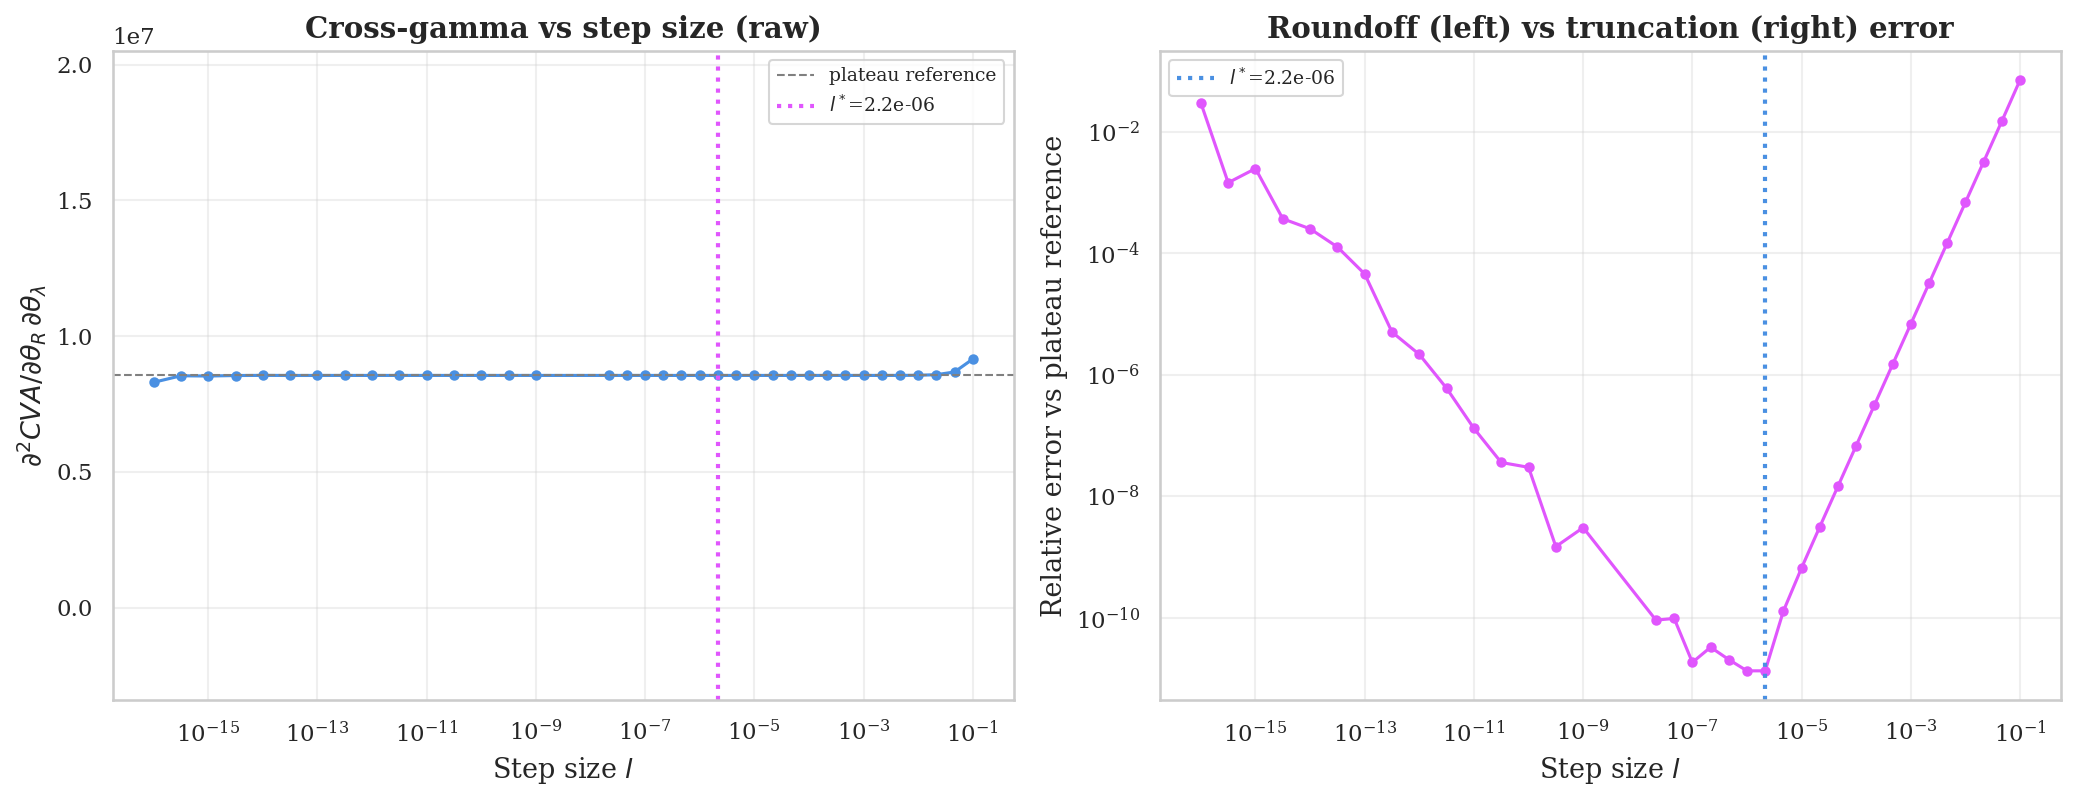

In [44]:
# Plot: cross-gamma vs step size l (raw value, and relative error vs plateau)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

ax1.plot(l_grid, gamma_sweep, marker="o", markersize=4, color="#4A90E2", linewidth=1.5)
ax1.axhline(gamma_ref, color="gray", linestyle="--", linewidth=1, label="plateau reference")
ax1.axvline(l_optimal, color="#E056FD", linestyle=":", linewidth=2, label=f"$l^*$={l_optimal:.1e}")
ax1.set_xscale("log")
ax1.set_ylim(gamma_ref - 4 * abs(gamma_ref) * 0.35, gamma_ref + 4 * abs(gamma_ref) * 0.35)
ax1.set_xlabel(r"Step size $l$")
ax1.set_ylabel(r"$\partial^2 CVA / \partial\theta_R\,\partial\theta_\lambda$")
ax1.set_title("Cross-gamma vs step size (raw)", weight="bold")
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3)

ax2.plot(l_grid, rel_error, marker="o", markersize=4, color="#E056FD", linewidth=1.5)
ax2.axvline(l_optimal, color="#4A90E2", linestyle=":", linewidth=2, label=f"$l^*$={l_optimal:.1e}")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel(r"Step size $l$")
ax2.set_ylabel(r"Relative error vs plateau reference")
ax2.set_title("Roundoff (left) vs truncation (right) error", weight="bold")
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.savefig("../results/dual_wwr_cross_gamma_step_size-citi.png", bbox_inches="tight", dpi=300)
plt.show()


### Truncation versus Round-off Decomposition of the Step-Size Error

The total error of the central difference applied to an AAD-computed gradient is

$$\text{error}(l) \;\approx\; \underbrace{C_1\, l^2}_{\text{truncation}}
\;+\; \underbrace{\dfrac{C_2}{l}}_{\text{round-off}}$$

- **Truncation error** ($l$ large). The central difference replaces the true derivative of $\Delta_{AAD}^{(R)}(\cdot)$ with a quadratic Taylor remainder. This term is systematic: it has a definite sign and grows smoothly with $l$, so the same $l$ always produces the same bias.
- **Round-off error** ($l$ small). $\Delta_{AAD}^{(R)}(+l)$ and $\Delta_{AAD}^{(R)}(-l)$ are known only to double precision ($\varepsilon\approx2.2\times10^{-16}$). Subtracting two nearly equal numbers and dividing by a small $2l$ amplifies this representation error by $1/l$. The amplified noise has no consistent sign and fluctuates unpredictably from one $l$ to the next.

Fitting the two regimes separately on a log-log plot recovers $C_1$ and $C_2$ and confirms the theoretical slopes of $+2$ and $-1$. Minimizing the total error gives the closed-form optimum $l^*_{\text{theory}} = \left(C_2 / 2C_1\right)^{1/3}$, which lies in the same stable region as the empirically selected $l^*$.


Truncation / bias regime (l >= 1e-4):
  fitted slope = +2.002   (theory: +2.000)
  C1 = 6.988151e+00

Roundoff / variance regime (l <= 1e-10):
  fitted slope = -0.989   (theory: -1.000)
  C2 = 2.724604e-18

l_optimal (theory, from C1/C2 fit)   = 5.530e-07
l_optimal (empirical, plateau method) = 2.154e-06
ratio = 0.257x


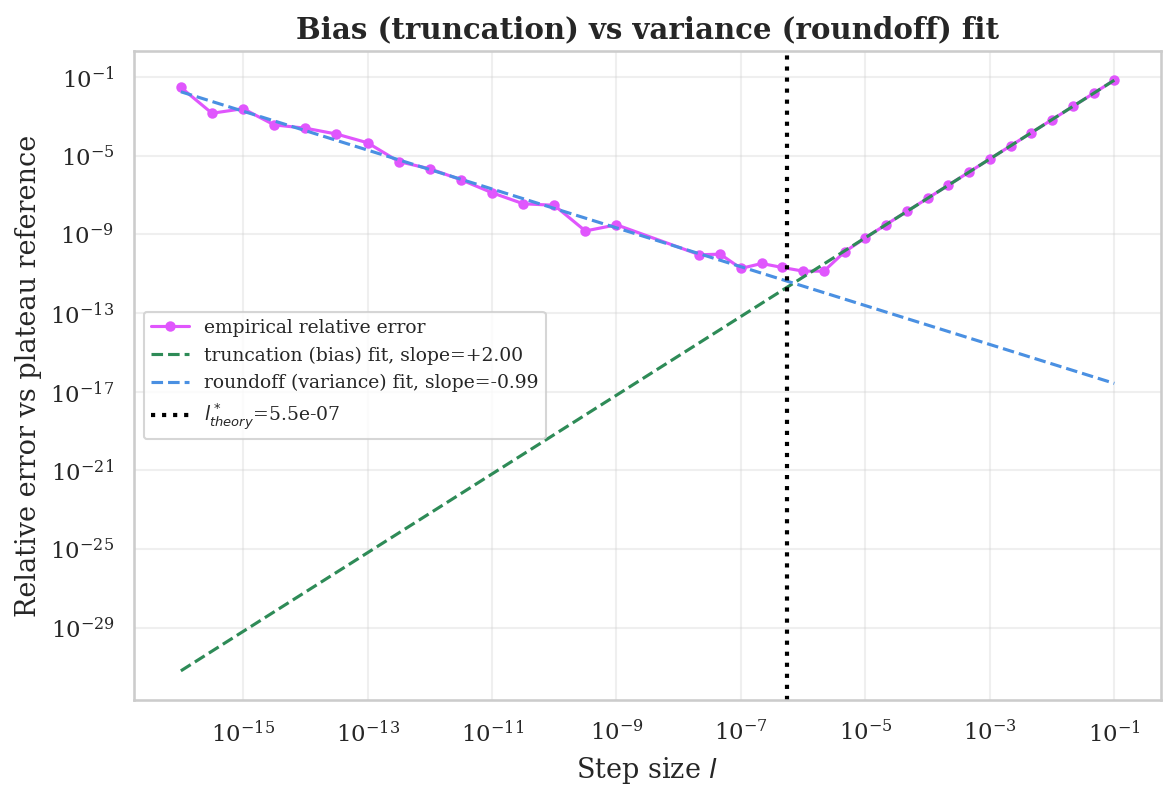

In [45]:
# Bias (truncation) vs variance (roundoff) decomposition: fit error(l) ~ C1*l^2
# in the large-l regime and error(l) ~ C2/l in the small-l regime, on the same
# l_grid / rel_error arrays computed in the step-size sweep above.
trunc_mask = l_grid >= 1e-4
round_mask = l_grid <= 1e-10

log_l = np.log(l_grid)
log_err = np.log(rel_error)

slope_trunc, intercept_trunc = np.polyfit(log_l[trunc_mask], log_err[trunc_mask], 1)
slope_round, intercept_round = np.polyfit(log_l[round_mask], log_err[round_mask], 1)

C1 = np.exp(intercept_trunc)  # truncation ("bias") coefficient: rel_error ~ C1 * l^slope_trunc
C2 = np.exp(intercept_round)  # roundoff ("variance") coefficient: rel_error ~ C2 * l^slope_round

print("Truncation / bias regime (l >= 1e-4):")
print(f"  fitted slope = {slope_trunc:+.3f}   (theory: +2.000)")
print(f"  C1 = {C1:.6e}")
print()
print("Roundoff / variance regime (l <= 1e-10):")
print(f"  fitted slope = {slope_round:+.3f}   (theory: -1.000)")
print(f"  C2 = {C2:.6e}")
print()

# Closed-form minimizer of C1*l^2 + C2/l, using the FITTED slopes (not the
# theoretical 2 and -1) so the formula stays valid even if a regime's slope
# deviates a little from theory.
p, q = -slope_round, slope_trunc  # error ~ C2*l^{-p} + C1*l^{q}, p,q > 0
l_optimal_theory = ((p * C2) / (q * C1)) ** (1.0 / (p + q))

print(f"l_optimal (theory, from C1/C2 fit)   = {l_optimal_theory:.3e}")
print(f"l_optimal (empirical, plateau method) = {l_optimal:.3e}")
print(f"ratio = {l_optimal_theory / l_optimal:.3f}x")

# Overlay the two fitted power-law lines on the relative-error plot.
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(l_grid, rel_error, marker="o", markersize=4, color="#E056FD", linewidth=1.5, label="empirical relative error")

l_fit_line = np.logspace(np.log10(l_grid.min()), np.log10(l_grid.max()), 200)
trunc_fit = np.exp(intercept_trunc) * l_fit_line ** slope_trunc
round_fit = np.exp(intercept_round) * l_fit_line ** slope_round
ax.plot(l_fit_line, trunc_fit, "--", color="#2E8B57", linewidth=1.5,
        label=fr"truncation (bias) fit, slope={slope_trunc:+.2f}")
ax.plot(l_fit_line, round_fit, "--", color="#4A90E2", linewidth=1.5,
        label=fr"roundoff (variance) fit, slope={slope_round:+.2f}")
ax.axvline(l_optimal_theory, color="black", linestyle=":", linewidth=2,
           label=fr"$l^*_{{theory}}$={l_optimal_theory:.1e}")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"Step size $l$")
ax.set_ylabel(r"Relative error vs plateau reference")
ax.set_title("Bias (truncation) vs variance (roundoff) fit", weight="bold")
ax.legend(fontsize=9)
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.savefig("../results/dual_wwr_cross_gamma_bias_variance-citi.png", bbox_inches="tight", dpi=300)
plt.show()

### Cross-Gamma Report and Symmetry Check

Using the selected $l^*$, the cross-gamma is computed for the same five scenarios as the AAD sensitivity report. As a validation, each cross-gamma is also computed in the other direction, $\partial\Delta^{(\lambda)}_{\text{parallel}}/\partial\theta_R$ instead of $\partial\Delta^{(R)}_{\text{parallel}}/\partial\theta_\lambda$. For a smooth function the two mixed partial derivatives must agree, so a large discrepancy would indicate that $l^*$ is not in the stable regime for that scenario.


In [46]:
# Cross-gamma report: five canonical scenarios, both mixed-partial directions
cross_gamma_results = {}
for label, rho_r_lambda, rho_copula in aad_scenarios:
    d_up = parallel_rate_delta(+l_optimal, rho_r_lambda, rho_copula)
    d_dn = parallel_rate_delta(-l_optimal, rho_r_lambda, rho_copula)
    gamma_R_wrt_lambda = (d_up - d_dn) / (2.0 * l_optimal)

    e_up = parallel_credit_delta(+l_optimal, rho_r_lambda, rho_copula)
    e_dn = parallel_credit_delta(-l_optimal, rho_r_lambda, rho_copula)
    gamma_lambda_wrt_R = (e_up - e_dn) / (2.0 * l_optimal)

    symmetry_diff = gamma_R_wrt_lambda - gamma_lambda_wrt_R
    symmetry_rel = symmetry_diff / gamma_R_wrt_lambda

    cross_gamma_results[label] = {
        "gamma_R_wrt_lambda": gamma_R_wrt_lambda,
        "gamma_lambda_wrt_R": gamma_lambda_wrt_R,
        "symmetry_rel_diff": symmetry_rel,
    }

    print(f"=== {label} (rho_r,lambda={rho_r_lambda}, rho_copula={rho_copula}) ===")
    print(f"  d^2CVA/dtheta_R dtheta_lambda  = {gamma_R_wrt_lambda:14.4f}   (per 1bp^2 = {gamma_R_wrt_lambda*1e-8:+10.6f})")
    print(f"  d^2CVA/dtheta_lambda dtheta_R  = {gamma_lambda_wrt_R:14.4f}   (per 1bp^2 = {gamma_lambda_wrt_R*1e-8:+10.6f})")
    print(f"  symmetry check: relative diff  = {symmetry_rel:+.4%}")
    print()


=== Independent (rho_r,lambda=0.0, rho_copula=0.0) ===
  d^2CVA/dtheta_R dtheta_lambda  =   8548548.3971   (per 1bp^2 =  +0.085485)
  d^2CVA/dtheta_lambda dtheta_R  =   8548619.0202   (per 1bp^2 =  +0.085486)
  symmetry check: relative diff  = -0.0008%



=== Diffusion-only (rho_r,lambda=0.4, rho_copula=0.0) ===
  d^2CVA/dtheta_R dtheta_lambda  =   8545321.8165   (per 1bp^2 =  +0.085453)
  d^2CVA/dtheta_lambda dtheta_R  =   8545392.5464   (per 1bp^2 =  +0.085454)
  symmetry check: relative diff  = -0.0008%



=== Jump-only (rho_r,lambda=0.0, rho_copula=0.4) ===
  d^2CVA/dtheta_R dtheta_lambda  =  12545549.2295   (per 1bp^2 =  +0.125455)
  d^2CVA/dtheta_lambda dtheta_R  =  12545618.3997   (per 1bp^2 =  +0.125456)
  symmetry check: relative diff  = -0.0006%



=== Dual (rho_r,lambda=0.4, rho_copula=0.4) ===
  d^2CVA/dtheta_R dtheta_lambda  =  12540339.6500   (per 1bp^2 =  +0.125403)
  d^2CVA/dtheta_lambda dtheta_R  =  12540408.9299   (per 1bp^2 =  +0.125404)
  symmetry check: relative diff  = -0.0006%



=== Dual-strong (rho_r,lambda=0.8, rho_copula=0.8) ===
  d^2CVA/dtheta_R dtheta_lambda  =  17262882.1029   (per 1bp^2 =  +0.172629)
  d^2CVA/dtheta_lambda dtheta_R  =  17262903.6082   (per 1bp^2 =  +0.172629)
  symmetry check: relative diff  = -0.0001%



### Collateralized CVA: CSA and MPOR

This cell reuses `V`, `u_tau_t`, `P_paths_Tm`, `P0_Tm`, `delta_Q_cache`, `dual_wwr_results` and `scenarios` from the cells above. Only the CSA collateral calculation (Module 5) and the copula weighting and aggregation (Modules 6 and 7) are re-run, on the same simulated paths. The threshold and the minimum transfer amount are set to zero (TH = MTA = 0), so that the CVA reductions are driven solely by the delay of the margin period of risk (MPOR).

The MPOR for uncleared OTC derivatives is typically about ten business days. Because the simulation grid is weekly, the MPOR is set to exact multiples of the weekly step (1, 2 and 4 weeks, i.e. 1, 2 and 4 grid steps), which keeps the lagged and the current exposure on the same grid points and avoids interpolation. The 2-week MPOR is the grid-aligned value closest to the ten-business-day convention.


In [47]:
# Module 5 (addition) - CSA/MPOR collateralized trade value
def csa_mpor_netted_value(V, mpor_steps):
    '''
    Approximate CSA-collateralized (margined) trade value under a Margin
    Period of Risk (MPOR), assuming zero threshold and zero minimum transfer
    amount (full collateralization, delayed by MPOR):

        V_csa(t_k) = V(t_k) - V(t_{k-mpor_steps})   for k >= mpor_steps
        V_csa(t_k) = V(t_k)                          for k <  mpor_steps  (no collateral yet)
    '''
    V_csa = V.copy()
    if mpor_steps > 0:
        V_csa[mpor_steps:, :] = V[mpor_steps:, :] - V[:-mpor_steps, :]
    return V_csa

In [48]:
# CVA under CSA collateralization, swept across MPOR = 0/1/2/4 calendar weeks,
# across every WWR scenario from the "Compare CVA..." cell above.
mpor_weeks_list = [0, 1, 2, 4]
print(f"{'Scenario':45s} " + "".join(f"MPOR={w}wk".rjust(12) + "  " for w in mpor_weeks_list))

mpor_results = {}
for label, rho_r_lambda, rho_copula in scenarios:
    delta_Q_diff = delta_Q_cache[rho_r_lambda]
    row = []
    for mpor_weeks in mpor_weeks_list:
        if mpor_weeks == 0:
            E_use = E
        else:
            V_csa = csa_mpor_netted_value(V, mpor_weeks)
            E_use = np.maximum(V_csa, 0.0)
        w_copula = copula_path_weights_market_tau(E_use, u_tau_t, rho_copula)
        cva = compute_dual_wwr_cva(E_use, P_paths_Tm, delta_Q_diff, w_copula, P0_Tm, recovery_rate)
        row.append(cva)
    mpor_results[label] = row
    print(f"{label:45s} " + "".join(f"{v:12.2f}  " for v in row))

print("\nReduction vs. uncollateralized (MPOR=0):")
for label, row in mpor_results.items():
    base = row[0]
    print(f"{label:45s} " + "".join(f"{(1 - v/base):11.2%}  " for v in row))

Scenario                                          MPOR=0wk      MPOR=1wk      MPOR=2wk      MPOR=4wk  


Independent (rho_r,lambda=0.0, rho_copula=0.0)      1528.80        147.06        220.18        328.75  


Diffusion WWR only (rho_r,lambda=0.4, rho_copula=0.0)      1542.53        146.84        222.37        334.73  


Diffusion WWR only (rho_r,lambda=0.8, rho_copula=0.0)      1556.33        146.62        224.57        340.78  


Jump WWR only (rho_r,lambda=0.0, rho_copula=0.4)      2284.71        214.01        315.51        465.97  


Jump WWR only (rho_r,lambda=0.0, rho_copula=0.8)      3056.00        289.84        422.27        618.82  


Dual WWR (rho_r,lambda=0.4, rho_copula=0.4)        2312.32        213.51        319.92        478.07  


Dual WWR - strong (rho_r,lambda=0.8, rho_copula=0.8)      3145.03        288.14        436.98        659.27  


Dual WWR - empirical (rho_r,lambda=-0.10, rho_copula=-0.10)      1344.68        132.04        198.30        296.70  

Reduction vs. uncollateralized (MPOR=0):
Independent (rho_r,lambda=0.0, rho_copula=0.0)       0.00%       90.38%       85.60%       78.50%  
Diffusion WWR only (rho_r,lambda=0.4, rho_copula=0.0)       0.00%       90.48%       85.58%       78.30%  
Diffusion WWR only (rho_r,lambda=0.8, rho_copula=0.0)       0.00%       90.58%       85.57%       78.10%  
Jump WWR only (rho_r,lambda=0.0, rho_copula=0.4)       0.00%       90.63%       86.19%       79.61%  
Jump WWR only (rho_r,lambda=0.0, rho_copula=0.8)       0.00%       90.52%       86.18%       79.75%  
Dual WWR (rho_r,lambda=0.4, rho_copula=0.4)         0.00%       90.77%       86.16%       79.33%  
Dual WWR - strong (rho_r,lambda=0.8, rho_copula=0.8)       0.00%       90.84%       86.11%       79.04%  
Dual WWR - empirical (rho_r,lambda=-0.10, rho_copula=-0.10)       0.00%       90.18%       85.25%       77.94%  


**Reading the MPOR results.** Collateralization is a highly effective risk mitigant in every scenario. At a 1-week MPOR the CVA falls by about 90% relative to the uncollateralized case, at 2 weeks by about 85-86%, and at 4 weeks by about 78-80%. The reduction decreases monotonically in the MPOR within every scenario and is nearly the same across WWR scenarios (within about 2 percentage points at each MPOR), so collateral effectiveness and WWR-driven CVA amplification are largely separate dimensions of risk.


### Netting: a Second (5Y) Trade in the Same Netting Set

A second 5-year IRS with USD 1 million notional is added to the netting set of the 10-year trade and priced off the same simulated rate paths. Its semi-annual payment dates are an exact prefix of the 10-year schedule, so the simulated `P_paths` can be sliced directly and need not be re-simulated.

The 5Y trade matures at $t=5$. Because `simulate_irs_value` applies a floating-leg notional correction at every date after the trade's first payment date without checking the trade's own maturity, the 5Y trade is priced on its own truncated time axis spanning only $[0,5]$ and is zero-padded onto the full 10Y grid, so that it contributes no value or exposure after maturity. The netted exposure is computed on the sum of the trade values before the non-negativity floor, $E_j^{net}(t_k)=\big(\sum_i V_i^{(j)}(t_k)\big)^+$.


In [49]:
# Second trade: 5Y IRS, same notional, sharing the already-simulated P_paths
# (its payment dates are an exact prefix of the 10Y trade's schedule).
T_pay_5y = [t for t in T_pay if t <= 5.0]
notional_5y = notional
print(f"10Y trade payment dates: {len(T_pay)} dates, 0..{T_pay[-1]}")
print(f" 5Y trade payment dates: {len(T_pay_5y)} dates, 0..{T_pay_5y[-1]} (exact prefix of the 10Y schedule)")

n_5y_steps = int(np.sum(t_axis <= 5.0 + 1e-9))
t_axis_5y = t_axis[:n_5y_steps]
P_paths_5y = P_paths[:n_5y_steps, :, :len(T_pay_5y)]
print(f"5Y trade priced on its own {n_5y_steps}-step sub-axis (t<=5), "
      f"zero-padded to the full {len(t_axis)}-step grid for netting.")

10Y trade payment dates: 21 dates, 0..10.0
 5Y trade payment dates: 11 dates, 0..5.0 (exact prefix of the 10Y schedule)
5Y trade priced on its own 261-step sub-axis (t<=5), zero-padded to the full 521-step grid for netting.


In [50]:
# Netting benefit: 10Y trade + 5Y trade, same direction vs. opposite direction.
for label2, sign2 in [("same direction (payer, like the 10Y)", swap_config["delta"]),
                       ("opposite direction (receiver)", -swap_config["delta"])]:
    print(f"\n--- 5Y trade: {label2} ---")
    V_5y_actual, E_5y_actual, K_5y = simulate_irs_value(
        P_paths_5y, t_axis_5y, T_pay_5y, notional_5y, sign2, sofr_yield_curve_calibrated)

    V_5y = np.zeros_like(V)
    V_5y[:n_5y_steps, :] = V_5y_actual
    E_5y = np.maximum(V_5y, 0.0)

    V_net = V + V_5y
    E_net = np.maximum(V_net, 0.0)

    print(f"{'Scenario':30s} {'CVA(10Y alone)':>16s} {'CVA(5Y alone)':>15s} {'Sum (no netting)':>18s} {'CVA(netted)':>13s} {'Netting benefit':>16s}")
    for label, rho_r_lambda, rho_copula in scenarios:
        delta_Q_diff = delta_Q_cache[rho_r_lambda]
        w_10y = copula_path_weights_market_tau(E, u_tau_t, rho_copula)
        cva_10y = compute_dual_wwr_cva(E, P_paths_Tm, delta_Q_diff, w_10y, P0_Tm, recovery_rate)
        w_5y = copula_path_weights_market_tau(E_5y, u_tau_t, rho_copula)
        cva_5y = compute_dual_wwr_cva(E_5y, P_paths_Tm, delta_Q_diff, w_5y, P0_Tm, recovery_rate)
        cva_sum = cva_10y + cva_5y
        w_net = copula_path_weights_market_tau(E_net, u_tau_t, rho_copula)
        cva_net = compute_dual_wwr_cva(E_net, P_paths_Tm, delta_Q_diff, w_net, P0_Tm, recovery_rate)
        benefit = 1.0 - cva_net / cva_sum
        print(f"{label:30s} {cva_10y:16.2f} {cva_5y:15.2f} {cva_sum:18.2f} {cva_net:13.2f} {benefit:15.2%}")


--- 5Y trade: same direction (payer, like the 10Y) ---
Scenario                         CVA(10Y alone)   CVA(5Y alone)   Sum (no netting)   CVA(netted)  Netting benefit


Independent (rho_r,lambda=0.0, rho_copula=0.0)          1528.80          119.63            1648.43       1618.51           1.82%
Diffusion WWR only (rho_r,lambda=0.4, rho_copula=0.0)          1542.53          122.80            1665.33       1635.30           1.80%


Diffusion WWR only (rho_r,lambda=0.8, rho_copula=0.0)          1556.33          126.02            1682.35       1652.21           1.79%


Jump WWR only (rho_r,lambda=0.0, rho_copula=0.4)          2284.71          237.27            2521.98       2483.73           1.52%


Jump WWR only (rho_r,lambda=0.0, rho_copula=0.8)          3056.00          391.95            3447.96       3398.31           1.44%


...

Jump WWR only (rho_r,lambda=0.0, rho_copula=0.4)          2284.71          526.32            2811.03       2097.48          25.38%


Jump WWR only (rho_r,lambda=0.0, rho_copula=0.8)          3056.00          737.82            3793.82       2721.98          28.25%


Dual WWR (rho_r,lambda=0.4, rho_copula=0.4)          2312.32          514.12            2826.44       2117.29          25.09%


Dual WWR - strong (rho_r,lambda=0.8, rho_copula=0.8)          3145.03          694.94            3839.97       2781.10          27.57%


Dual WWR - empirical (rho_r,lambda=-0.10, rho_copula=-0.10)          1344.68          315.58            1660.26       1288.16          22.41%


**Reading the netting results.** When the 5Y trade is booked in the same direction as the 10Y trade (5Y payer), the netting benefit is small, between 1.40% and 1.94% across the scenarios, because both exposures move together and there is little scope for offset. When the 5Y trade runs in the opposite direction (5Y receiver), the benefit is between 22.42% and 28.25%, since the two exposures substantially offset one another before the non-negativity floor is applied.

The effect is driven almost entirely by the jump-to-default channel. Increasing $\rho_{r,\lambda}$ alone leaves both benefits essentially unchanged from the Independent case, whereas increasing $\rho_{copula}$ moves them in opposite directions: the co-directional benefit falls from 1.82% (Independent) to 1.44% ($\rho_{copula}=0.8$) and 1.40% (Dual-strong), while the counter-directional benefit rises from 22.88% to 28.25% and 27.57%, respectively. Netting effectiveness is therefore governed by the degree of exposure offset among the trades in the set, and jump-to-default WWR amplifies or compresses whatever effect is already present.


### Summary of the Citigroup Results

**Calibration.** The credit dynamics are estimated by exact maximum likelihood on Citigroup's historical 5Y CDS spread as $\kappa=8.61$, $\bar\lambda=0.0094$ and $\sigma_\lambda=0.0369$, and the rate parameters are calibrated to swaptions at $(a,\sigma_r)\approx(0.022,0.010)$. The empirical spread correlation is $\rho_s=-0.091$ (Spearman), which maps to a Pearson correlation of about $-0.10$ and does not indicate WWR over this sample window.

**Independent benchmark.** The uncollateralized CVA of the 10Y payer IRS is 1528.80 USD per USD 1 million of notional (0.1529%).

**Diffusive channel.** Raising $\rho_{r,\lambda}$ from 0 to 0.9 with $\rho_{copula}=0$ raises the CVA only from 0.1529% to 0.1560% of the notional (+2.03%). With the high mean reversion speed of the calibrated credit dynamics ($\kappa\approx8.61$), a diffusive deviation of the default intensity is pulled back toward its long-term mean within a short time, which limits the ability of this channel to generate heavy-tailed WWR.

**Jump-to-default channel.** Raising $\rho_{copula}$ from 0 to 0.9 with $\rho_{r,\lambda}=0$ raises the CVA from 0.1529% to 0.3286% of the notional, a premium of 114.9% over the Independent benchmark. This channel does not depend on $\kappa$.

**Dual WWR.** At $(\rho_{r,\lambda},\rho_{copula})=(0.9,0.9)$ the CVA reaches 0.3397% of the notional.


## Part 5: Hedging Performance (Table 1)

This section evaluates the dynamic hedging performance under each WWR scenario using the nine precomputed monthly joint conditional-AAD grids (`dual_wwr_joint_grid_citi_{scenario}_monthly.npz`). For each of the 131 monthly rebalancing dates, a grid holds the CVA, the rate delta, the credit delta and the Model Vega at $9\times9=81$ pilot nodes of $(x_r,x_\lambda)$. The nodes are the 10th to 90th percentiles of the simulated state factors across the $M=10{,}000$ outer paths, and each node is re-simulated forward with 1,000 fresh sub-paths. A bivariate quadratic polynomial is fitted by ordinary least squares to the 81 CVA values of each date and is then evaluated, together with its analytic gradient, at each outer path's own realized state (Appendix B.4 of the thesis).

The grids are built with the Citigroup calibration and $\lambda^{jump}=0.0417$. For each scenario, the naive hedge is sized under the Independent assumption and the adjusted hedge is sized under the scenario's own WWR parameters. This section re-derives the Citigroup calibration locally, so that it can be run independently of the cells above.


In [51]:
import matplotlib
matplotlib.use("Agg")
import nbformat
import numpy as np
import pandas as pd
import QuantLib as ql
from scipy.stats import ncx2
from scipy.optimize import minimize

NB_PATH = "../2_engine_notebook/dual_wwr_cva_engine.ipynb"
nb = nbformat.read(NB_PATH, as_version=4)
ns = {}

print("Loading simulation engine...", flush=True)
for i, c in enumerate(nb.cells):
    if c.cell_type != "code":
        continue
    exec(compile(c.source, f"<engine cell {i}>", "exec"), ns)

build_time_grid = ns["build_time_grid"]; generate_dual_wwr_randoms = ns["generate_dual_wwr_randoms"]
simulate_forward_zcb_paths = ns["simulate_forward_zcb_paths"]; simulate_irs_value = ns["simulate_irs_value"]
simulate_hazard_paths = ns["simulate_hazard_paths"]; path_survival_probabilities = ns["path_survival_probabilities"]
T_pay = ns["T_pay"]; notional = ns["notional"]; swap_config = ns["swap_config"]; max_years = ns["max_years"]

# ---------------------------------------------------------------------------
# Rebuild Citigroup calibration (rates + credit, Exact MLE, no Q-measure
# refit) -- identical methodology to citi_joint_grid_builder.py.
# ---------------------------------------------------------------------------
print("Rebuilding Citigroup calibration...", flush=True)
df_sofr_new = pd.read_excel("../4_market_data/sofr/SOFR 2023 -2026.xlsx")
df_sofr_new.columns = ["Date", "SOFR"]
df_sofr_new["SOFR"] = pd.to_numeric(df_sofr_new["SOFR"], errors="coerce") / 100
df_sofr_new = df_sofr_new.dropna(subset=["Date", "SOFR"]).sort_values("Date")
sofr_series_new = df_sofr_new.set_index("Date")["SOFR"]
a_new, sigma_r_new = ns["calibrate_hw"](sofr_series_new)

df_ois = pd.read_excel("../4_market_data/licensed_not_for_upload/SOFR 8_11.xlsx", sheet_name="Curve1 - Realtime", header=None)
df_ois.columns = ["Maturity", "Bid", "Yield", "Ask", "BenchmarkSpread", "NetChange"]
df_ois = df_ois.iloc[2:].copy()
df_ois["Bid"] = pd.to_numeric(df_ois["Bid"], errors="coerce")
ois_map = dict(zip(df_ois["Maturity"], df_ois["Bid"]))
sofr_market_quotes_new = {t: ois_map[t] / 100 for t in ["1M", "3M", "6M", "1Y", "2Y", "5Y", "10Y", "30Y"]}

_, _, sofr_yield_curve_new_prelim = ns["get_ql_br_t"](sofr_market_quotes_new, a_new, sigma_r_new)
yield_curve_handle_new = ql.RelinkableYieldTermStructureHandle(sofr_yield_curve_new_prelim)
index_new = ql.Sofr(yield_curve_handle_new)
helpers_new = []
for expiry, tenor, vol in ns["swaption_vols"]:
    vol_quote = ql.QuoteHandle(ql.SimpleQuote(vol / 10000.0))
    helper = ql.SwaptionHelper(ql.Period(int(expiry * 12), ql.Months), ql.Period(int(tenor), ql.Years),
        vol_quote, index_new, ql.Period(1, ql.Years), ql.Actual360(), ql.Actual360(),
        yield_curve_handle_new, ql.BlackCalibrationHelper.RelativePriceError, ql.nullDouble(), 1.0, 1)
    helpers_new.append(helper)
model_new = ql.HullWhite(yield_curve_handle_new, a_new, sigma_r_new)
engine_new = ql.JamshidianSwaptionEngine(model_new)
for h in helpers_new:
    h.setPricingEngine(engine_new)
model_new.calibrate(helpers_new, ql.LevenbergMarquardt(), ql.EndCriteria(1000, 100, 1e-8, 1e-8, 1e-8))
a_calibrated = model_new.params()[0]
sigma_r_calibrated = model_new.params()[1]
t_axis_cal_new, br_curve_cal_new, sofr_yield_curve_calibrated = ns["get_ql_br_t"](
    sofr_market_quotes_new, a_calibrated, sigma_r_calibrated)

df_citi = pd.read_excel("../4_market_data/licensed_not_for_upload/Citigroup 5Y CDS 2024 - 2026.xlsx")
df_citi.columns = ["Date", "Spread5Y"]
df_citi["Spread5Y"] = pd.to_numeric(df_citi["Spread5Y"], errors="coerce") / 10000
recovery_rate = 0.4
df_citi["lambda"] = df_citi["Spread5Y"] / (1 - recovery_rate)
df_citi = df_citi.dropna(subset=["Date", "lambda"]).sort_values("Date")
lambda_series_citi = df_citi.set_index("Date")["lambda"]


def calibrate_cir_mle(lam_series, dt=1 / 252):
    lam = lam_series[lam_series > 1e-8].values
    lam_t, lam_tp1 = lam[:-1], lam[1:]

    def neg_loglik(params):
        kappa, lambda_bar, sigma = params
        if kappa <= 0 or lambda_bar <= 0 or sigma <= 0:
            return 1e12
        c = sigma ** 2 * (1 - np.exp(-kappa * dt)) / (4 * kappa)
        if c <= 0:
            return 1e12
        df = 4 * kappa * lambda_bar / sigma ** 2
        nc = 4 * kappa * np.exp(-kappa * dt) * lam_t / (sigma ** 2 * (1 - np.exp(-kappa * dt)))
        x = lam_tp1 / c
        pdf_vals = np.clip(ncx2.pdf(x, df, nc) / c, 1e-300, None)
        return -np.sum(np.log(pdf_vals))

    k0, lb0, s0 = ns["calibrate_cir_regression"](lam_series, dt)
    init = [max(k0, 0.1), max(lb0, 1e-4), max(s0, 1e-4)]
    opt_res = minimize(neg_loglik, init, method="Nelder-Mead",
                        options={"xatol": 1e-10, "fatol": 1e-10, "maxiter": 20000, "maxfev": 20000})
    return opt_res.x[0], opt_res.x[1], opt_res.x[2]


kappa_mle, lambda_bar_mle, sigma_mle_raw = calibrate_cir_mle(lambda_series_citi)
sigma_mle_final = max(sigma_mle_raw, 0.02)
cds_market_data = {
    "6M": 24.550 / 10000, "1Y": 26.757 / 10000, "2Y": 32.761 / 10000,
    "3Y": 37.253 / 10000, "5Y": 53.331 / 10000, "7Y": 69.857 / 10000, "10Y": 90.838 / 10000,
}
b_lambda_prelim = ns["get_ql_blambda_t"](
    cds_market_data, sofr_yield_curve_calibrated, kappa_mle, lambda_bar_mle, sigma_mle_final, x0=lambda_bar_mle)
x_lambda_0 = b_lambda_prelim["fm_curve"](b_lambda_prelim["t_axis_l"])[0]
b_lambda_calibration = ns["get_ql_blambda_t"](
    cds_market_data, sofr_yield_curve_calibrated, kappa_mle, lambda_bar_mle, sigma_mle_final, x0=x_lambda_0)
bl_func_calibration = b_lambda_calibration["bl_func"]
kappa_calibration = kappa_mle
lambda_bar_calibration = lambda_bar_mle
sigma_lambda_calibration = sigma_mle_final
print(f"  rates: a_calibrated={a_calibrated:.6f}  sigma_r_calibrated={sigma_r_calibrated:.6f}")
print(f"  credit: kappa={kappa_calibration:.4f}  lambda_bar={lambda_bar_calibration:.6f}  "
      f"sigma_lambda={sigma_lambda_calibration:.6f}  x_lambda_0={x_lambda_0:.6f}", flush=True)

n_paths_run = 10000
seed_run = 1234
t_axis, dt_grid = build_time_grid(max_years, steps_per_year=52)
T_m = T_pay[-1]


def reconstruct_paths_joint(rho_r_lambda):
    randoms_j = generate_dual_wwr_randoms(t_axis, n_paths_run, rho_r_lambda=rho_r_lambda, seed=seed_run)
    dW_r_j, dW_lambda_j = randoms_j["dW_r"], randoms_j["dW_lambda"]
    n_paths_j = dW_r_j.shape[1]
    x_r_path_j = np.zeros((len(t_axis), n_paths_j))
    for k in range(len(t_axis) - 1):
        t_prev = t_axis[k]
        sigma_P_Tm_k = (sigma_r_calibrated / a_calibrated) * (1.0 - np.exp(-a_calibrated * (T_m - t_prev)))
        drift = (-a_calibrated * x_r_path_j[k, :] - sigma_r_calibrated * sigma_P_Tm_k) * dt_grid[k]
        x_r_path_j[k + 1, :] = x_r_path_j[k, :] + drift + sigma_r_calibrated * dW_r_j[k, :]
    lambda_diff_j = simulate_hazard_paths(
        kappa_calibration, lambda_bar_calibration, sigma_lambda_calibration, x_lambda_0,
        a_calibrated, sigma_r_calibrated, rho_r_lambda, bl_func_calibration, dW_lambda_j, t_axis, T_m,
    )
    h_j = np.sqrt(kappa_calibration ** 2 + 2.0 * sigma_lambda_calibration ** 2)
    exp_ht_j = np.exp(h_j * t_axis)
    denom_j = 2.0 * h_j + (kappa_calibration + h_j) * (exp_ht_j - 1.0)
    fCIR_j = (2.0 * kappa_calibration * lambda_bar_calibration * (exp_ht_j - 1.0)) / denom_j + \
        x_lambda_0 * (4.0 * h_j ** 2 * exp_ht_j) / denom_j ** 2
    fM_j = b_lambda_calibration["fm_curve"](t_axis)
    b_lambda_j = fM_j - fCIR_j
    x_lambda_path_j = np.clip(lambda_diff_j - b_lambda_j[:, np.newaxis], 0.0, None)
    return x_r_path_j, x_lambda_path_j


def fit_bivariate(ckpt_path, field):
    ckpt = np.load(ckpt_path, allow_pickle=True)
    y_g = ckpt[field]
    xr_pg = ckpt["xr_pilot_grid"]
    xl_pg = ckpt["xl_pilot_grid"]
    dates_g = ckpt["t_axis_dates"]
    n_d = y_g.shape[0]
    coeffs_g = np.zeros((n_d, 6))
    for di in range(n_d):
        xr_v, xl_v = np.meshgrid(xr_pg[di, :], xl_pg[di, :], indexing="ij")
        xr_f, xl_f = xr_v.flatten(), xl_v.flatten()
        y = y_g[di, :, :].flatten()
        X = np.column_stack([np.ones_like(xr_f), xr_f, xl_f, xr_f**2, xl_f**2, xr_f*xl_f])
        c, *_ = np.linalg.lstsq(X, y, rcond=None)
        coeffs_g[di, :] = c
    return coeffs_g, dates_g


def value_and_partials(coeffs_g, di, xr, xl):
    c0, c1, c2, c3, c4, c5 = coeffs_g[di, :]
    val = c0 + c1*xr + c2*xl + c3*xr**2 + c4*xl**2 + c5*xr*xl
    d_dxr = c1 + 2*c3*xr + c5*xl
    d_dxl = c2 + 2*c4*xl + c5*xr
    return val, d_dxr, d_dxl


GRID_FILES = {
    "Independent": ("../3_grids_9x9/dual_wwr_joint_grid_citi_independent_monthly.npz", 0.0),
    "WWR(0.4/0.4)": ("../3_grids_9x9/dual_wwr_joint_grid_citi_wwr_monthly.npz", 0.4),
    "WWR(0.8/0.8)": ("../3_grids_9x9/dual_wwr_joint_grid_citi_wwr_strong_monthly.npz", 0.8),
    "Mixed-A(rl=0.4,cop=0.8)": ("../3_grids_9x9/dual_wwr_joint_grid_citi_mixed_(04,08)_monthly.npz", 0.4),
    "Mixed-B(rl=0.8,cop=0.4)": ("../3_grids_9x9/dual_wwr_joint_grid_citi_mixed_(08,04)_monthly.npz", 0.8),
    "Diffusion(0.4/0.0)": ("../3_grids_9x9/dual_wwr_joint_grid_citi_diff_04_monthly.npz", 0.4),
    "Diffusion(0.8/0.0)": ("../3_grids_9x9/dual_wwr_joint_grid_citi_diff_08_monthly.npz", 0.8),
    "Jump(0.0/0.4)": ("../3_grids_9x9/dual_wwr_joint_grid_citi_jump_04_monthly.npz", 0.0),
    "Jump(0.0/0.8)": ("../3_grids_9x9/dual_wwr_joint_grid_citi_jump_08_monthly.npz", 0.0),
}

print("Loading grids, fitting CVA regressions, reconstructing paths...", flush=True)
cva_coeffs = {}
paths = {}
grid_dates_ref = None
for label, (fname, rho_r_lambda) in GRID_FILES.items():
    c_cva, dates_g = fit_bivariate(fname, "cva_grid")
    if grid_dates_ref is None:
        grid_dates_ref = dates_g
    cva_coeffs[label] = c_cva
    xr_p, xl_p = reconstruct_paths_joint(rho_r_lambda)
    paths[label] = (xr_p, xl_p)
    print(f"  {label} done", flush=True)

n_grid_dates = len(grid_dates_ref)
grid_idx_in_full = np.array([np.argmin(np.abs(t_axis - t)) for t in grid_dates_ref])


def compute_joint_residuals(cva_c, hedge_c, xr_path, xl_path):
    n_paths = xr_path.shape[1]
    period_residual = np.zeros((n_grid_dates - 1, n_paths))
    period_unhedged = np.zeros((n_grid_dates - 1, n_paths))
    cva_prev = xr_prev = xl_prev = None
    for di in range(n_grid_dates):
        k_full = grid_idx_in_full[di]
        xr_k = xr_path[k_full, :]
        xl_k = xl_path[k_full, :]
        cva_k, _, _ = value_and_partials(cva_c, di, xr_k, xl_k)
        if di == 0:
            cva_prev, xr_prev, xl_prev = cva_k, xr_k, xl_k
            continue
        _, dcva_dxr_prev, dcva_dxl_prev = value_and_partials(hedge_c, di - 1, xr_prev, xl_prev)
        realized_dcva = cva_k - cva_prev
        linear_predicted = dcva_dxr_prev * (xr_k - xr_prev) + dcva_dxl_prev * (xl_k - xl_prev)
        period_unhedged[di - 1, :] = realized_dcva
        period_residual[di - 1, :] = realized_dcva - linear_predicted
        cva_prev, xr_prev, xl_prev = cva_k, xr_k, xl_k
    return period_residual, period_unhedged


scenarios_t1 = [
    ("Independent CVA + Independent hedge", "Independent", "Independent"),
    ("WWR(0.4/0.4) CVA + Independent hedge (naive)", "WWR(0.4/0.4)", "Independent"),
    ("WWR(0.4/0.4) CVA + WWR(0.4/0.4) hedge (adjusted)", "WWR(0.4/0.4)", "WWR(0.4/0.4)"),
    ("WWR(0.8/0.8) CVA + Independent hedge (naive)", "WWR(0.8/0.8)", "Independent"),
    ("WWR(0.8/0.8) CVA + WWR(0.8/0.8) hedge (adjusted)", "WWR(0.8/0.8)", "WWR(0.8/0.8)"),
    ("Mixed-A(0.4/0.8) CVA + Independent hedge (naive)", "Mixed-A(rl=0.4,cop=0.8)", "Independent"),
    ("Mixed-A(0.4/0.8) CVA + Mixed-A hedge (adjusted)", "Mixed-A(rl=0.4,cop=0.8)", "Mixed-A(rl=0.4,cop=0.8)"),
    ("Mixed-B(0.8/0.4) CVA + Independent hedge (naive)", "Mixed-B(rl=0.8,cop=0.4)", "Independent"),
    ("Mixed-B(0.8/0.4) CVA + Mixed-B hedge (adjusted)", "Mixed-B(rl=0.8,cop=0.4)", "Mixed-B(rl=0.8,cop=0.4)"),
    ("Diffusion(0.4/0.0) CVA + Independent hedge (naive)", "Diffusion(0.4/0.0)", "Independent"),
    ("Diffusion(0.4/0.0) CVA + Diffusion(0.4/0.0) hedge (adjusted)", "Diffusion(0.4/0.0)", "Diffusion(0.4/0.0)"),
    ("Diffusion(0.8/0.0) CVA + Independent hedge (naive)", "Diffusion(0.8/0.0)", "Independent"),
    ("Diffusion(0.8/0.0) CVA + Diffusion(0.8/0.0) hedge (adjusted)", "Diffusion(0.8/0.0)", "Diffusion(0.8/0.0)"),
    ("Jump(0.0/0.4) CVA + Independent hedge (naive)", "Jump(0.0/0.4)", "Independent"),
    ("Jump(0.0/0.4) CVA + Jump(0.0/0.4) hedge (adjusted)", "Jump(0.0/0.4)", "Jump(0.0/0.4)"),
    ("Jump(0.0/0.8) CVA + Independent hedge (naive)", "Jump(0.0/0.8)", "Independent"),
    ("Jump(0.0/0.8) CVA + Jump(0.0/0.8) hedge (adjusted)", "Jump(0.0/0.8)", "Jump(0.0/0.8)"),
]

CONFIDENCE_LEVELS = [95, 97.5, 99]


def var_es(x, alpha_pct):
    q = np.percentile(x, 100 - alpha_pct)
    var = -q
    es = -x[x <= q].mean()
    return var, es


print("\n" + "=" * 110)
print(f"TABLE 1: Hedge Effectiveness, %VaR/%ES reduction (pooled per-period), across all {len(scenarios_t1)} scenarios")
print("=" * 110)

table1_results = {}
for label, cva_key, hedge_key in scenarios_t1:
    xr_p, xl_p = paths[cva_key]
    period_residual, period_unhedged = compute_joint_residuals(cva_coeffs[cva_key], cva_coeffs[hedge_key], xr_p, xl_p)
    flat_res = period_residual.flatten()
    flat_unh = period_unhedged.flatten()

    var_hpl = np.var(flat_unh)
    var_upl = np.var(flat_res)
    HE = 1.0 - var_upl / var_hpl
    HRV = var_upl / var_hpl

    print(f"\n=== {label} ===")
    print(f"  Std(HPL)={np.std(flat_unh):.4f}  Std(UPL)={np.std(flat_res):.4f}  "
          f"HE={HE:.4%}  Hedged Residual Var %={HRV:.4%}")

    var_es_row = {}
    for cl in CONFIDENCE_LEVELS:
        var_h, es_h = var_es(flat_res, cl)
        var_u, es_u = var_es(flat_unh, cl)
        var_reduction = 1 - var_h / var_u
        es_reduction = 1 - es_h / es_u
        var_es_row[cl] = dict(var_h=var_h, es_h=es_h, var_u=var_u, es_u=es_u,
                               var_red=var_reduction, es_red=es_reduction)
        print(f"  {cl}%: VaR hedged={var_h:8.2f}  unhedged={var_u:8.2f}  reduction={var_reduction:7.2%}   "
              f"ES hedged={es_h:8.2f}  unhedged={es_u:8.2f}  reduction={es_reduction:7.2%}")

    table1_results[label] = dict(HE=HE, HRV=HRV, std_hpl=np.std(flat_unh), std_upl=np.std(flat_res), var_es=var_es_row)

# ---------------------------------------------------------------------------
# PLA diagnostics
# ---------------------------------------------------------------------------
print("\n" + "=" * 110)
print("FRTB-style PLA Diagnostics: Mean Test = Mean(UPL)/Std(HPL),  Variance Test = Var(UPL)/Var(HPL)")
print("Thresholds per BCBS265 p.89: mean test must lie within [-10%,+10%]; variance test must be <=20%.")
print("Either violation on its own constitutes a breach (no separate GREEN/AMBER banding for this test).")
print("=" * 110)

pla_results = {}
for label, cva_key, hedge_key in scenarios_t1:
    xr_p, xl_p = paths[cva_key]
    period_residual, period_unhedged = compute_joint_residuals(cva_coeffs[cva_key], cva_coeffs[hedge_key], xr_p, xl_p)
    UPL = period_residual.flatten()
    HPL = period_unhedged.flatten()
    mean_test = np.mean(UPL) / np.std(HPL)
    variance_test = np.var(UPL) / np.var(HPL)
    mean_pass = abs(mean_test) <= 0.10
    var_pass = variance_test <= 0.20
    zone = "PASS" if (mean_pass and var_pass) else "BREACH"
    pla_results[label] = dict(mean_test=mean_test, variance_test=variance_test, zone=zone)
    print(f"\n=== {label} ===")
    print(f"  Mean test     = Mean(UPL)/Std(HPL) = {mean_test:>8.4%}  ({'pass' if mean_pass else 'BREACH'}, threshold +/-10%)")
    print(f"  Variance test = Var(UPL)/Var(HPL)  = {variance_test:>8.4%}  ({'pass' if var_pass else 'BREACH'}, threshold <=20%)")
    print(f"  PLA result: {zone}")

print("\nDone.")
np.savez(
    "../results/citi_table1_pla_results.npz",
    table1_results=table1_results, pla_results=pla_results, allow_pickle=True,
)


Loading simulation engine...


Rebuilding Citigroup calibration...


  rates: a_calibrated=0.021505  sigma_r_calibrated=0.010035
  credit: kappa=8.6064  lambda_bar=0.009423  sigma_lambda=0.036899  x_lambda_0=0.004073


Loading grids, fitting CVA regressions, reconstructing paths...


  Independent done


...

  95%: VaR hedged=   81.71  unhedged=  507.82  reduction= 83.91%   ES hedged=  144.69  unhedged=  732.50  reduction= 80.25%
  97.5%: VaR hedged=  110.51  unhedged=  671.05  reduction= 83.53%   ES hedged=  195.20  unhedged=  883.80  reduction= 77.91%
  99%: VaR hedged=  159.09  unhedged=  871.37  reduction= 81.74%   ES hedged=  293.54  unhedged= 1073.50  reduction= 72.66%

FRTB-style PLA Diagnostics: Mean Test = Mean(UPL)/Std(HPL),  Variance Test = Var(UPL)/Var(HPL)
Thresholds per BCBS265 p.89: mean test must lie within [-10%,+10%]; variance test must be <=20%.
Either violation on its own constitutes a breach (no separate GREEN/AMBER banding for this test).

=== Independent CVA + Independent hedge ===
  Mean test     = Mean(UPL)/Std(HPL) = -4.4183%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.2203%  (pass, threshold <=20%)
  PLA result: PASS



=== WWR(0.4/0.4) CVA + Independent hedge (naive) ===
  Mean test     = Mean(UPL)/Std(HPL) = -6.3501%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  6.4054%  (pass, threshold <=20%)
  PLA result: PASS

=== WWR(0.4/0.4) CVA + WWR(0.4/0.4) hedge (adjusted) ===
  Mean test     = Mean(UPL)/Std(HPL) = -6.0975%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.3570%  (pass, threshold <=20%)
  PLA result: PASS

=== WWR(0.8/0.8) CVA + Independent hedge (naive) ===
  Mean test     = Mean(UPL)/Std(HPL) = -7.4302%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  = 15.8422%  (pass, threshold <=20%)
  PLA result: PASS

=== WWR(0.8/0.8) CVA + WWR(0.8/0.8) hedge (adjusted) ===
  Mean test     = Mean(UPL)/Std(HPL) = -6.9354%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.6486%  (pass, threshold <=20%)
  PLA result: PASS

=== Mixed-A(0.4/0.8) CVA + Independent hedge (naive) ===
  Mean test     = Mean(UPL)/Std(HPL) = -7.3662%  (pass


=== Mixed-A(0.4/0.8) CVA + Mixed-A hedge (adjusted) ===
  Mean test     = Mean(UPL)/Std(HPL) = -6.8799%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.6214%  (pass, threshold <=20%)
  PLA result: PASS

=== Mixed-B(0.8/0.4) CVA + Independent hedge (naive) ===
  Mean test     = Mean(UPL)/Std(HPL) = -6.4102%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  6.6175%  (pass, threshold <=20%)
  PLA result: PASS

=== Mixed-B(0.8/0.4) CVA + Mixed-B hedge (adjusted) ===
  Mean test     = Mean(UPL)/Std(HPL) = -6.1494%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.3698%  (pass, threshold <=20%)
  PLA result: PASS

=== Diffusion(0.4/0.0) CVA + Independent hedge (naive) ===
  Mean test     = Mean(UPL)/Std(HPL) = -4.4674%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.2220%  (pass, threshold <=20%)
  PLA result: PASS



=== Diffusion(0.4/0.0) CVA + Diffusion(0.4/0.0) hedge (adjusted) ===
  Mean test     = Mean(UPL)/Std(HPL) = -4.4617%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.2252%  (pass, threshold <=20%)
  PLA result: PASS

=== Diffusion(0.8/0.0) CVA + Independent hedge (naive) ===
  Mean test     = Mean(UPL)/Std(HPL) = -4.5157%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.2273%  (pass, threshold <=20%)
  PLA result: PASS

=== Diffusion(0.8/0.0) CVA + Diffusion(0.8/0.0) hedge (adjusted) ===
  Mean test     = Mean(UPL)/Std(HPL) = -4.5037%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.2300%  (pass, threshold <=20%)
  PLA result: PASS

=== Jump(0.0/0.4) CVA + Independent hedge (naive) ===
  Mean test     = Mean(UPL)/Std(HPL) = -6.2880%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  6.1995%  (pass, threshold <=20%)
  PLA result: PASS

=== Jump(0.0/0.4) CVA + Jump(0.0/0.4) hedge (adjusted) ===
  Mean test     = Mea


=== Jump(0.0/0.8) CVA + Independent hedge (naive) ===
  Mean test     = Mean(UPL)/Std(HPL) = -7.2994%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  = 14.9993%  (pass, threshold <=20%)
  PLA result: PASS

=== Jump(0.0/0.8) CVA + Jump(0.0/0.8) hedge (adjusted) ===
  Mean test     = Mean(UPL)/Std(HPL) = -6.8197%  (pass, threshold +/-10%)
  Variance test = Var(UPL)/Var(HPL)  =  3.5944%  (pass, threshold <=20%)
  PLA result: PASS

Done.


**Reading Table 1.** The adjusted hedge achieves a hedge effectiveness (HE) of about 96.3% to 96.8% in every scenario, matching the Independent benchmark (96.78%). The naive hedge degrades non-uniformly. It remains close to the adjusted benchmark when $\rho_{copula}=0.4$ (HE of about 93.4% to 93.6%), but falls to about 84.2% to 84.6% when $\rho_{copula}=0.8$, with the variance ratio of the unexplained P&L (UPL) rising from about 3-4% to about 15-16%. The amplification is driven almost entirely by $\rho_{copula}$ and not by $\rho_{r,\lambda}$.

The two naive $\rho_{copula}=0.8$ cases remain below the 20% PLA variance-test threshold, so they formally pass the FRTB PLA test, but they consume roughly 75% of the allowed variance budget and leave a thin safety buffer. The adjusted hedge restores the variance ratio to about 3-4%.
